In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os, sys, platform, subprocess
from pathlib import Path

print("python:", sys.version.split()[0], "|", platform.platform())
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True).stdout or "no GPU")

# package layout that will move into your repo unchanged later
ROOT = Path("/kaggle/working/imu_vlm_pipeline")
for d in ["pipeline", "outputs", "cache"]:
    (ROOT / d).mkdir(parents=True, exist_ok=True)
(ROOT / "pipeline" / "__init__.py").touch()
sys.path.insert(0, str(ROOT))
print("project root:", ROOT)

python: 3.13.15 | Linux-6.18.55+-x86_64-with-glibc2.39
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB

project root: /kaggle/working/imu_vlm_pipeline


In [2]:
INPUT = Path("/kaggle/input/datasets/smsiam/kitti-raw")
print("datasets attached:", [p.name for p in INPUT.iterdir()])

# locate every OXTS (IMU/GPS) sequence and its matching image folder
oxts_dirs = sorted(p.parent for p in INPUT.rglob("oxts") if p.is_dir())
print(f"\nfound {len(oxts_dirs)} drive(s) with oxts:")
for d in oxts_dirs[:10]:
    print(" ", d)

if oxts_dirs:
    d = oxts_dirs[0]
    print("\ncontents of first drive:", sorted(x.name for x in d.iterdir()))
    for sub in ["oxts", "image_02", "image_03"]:
        sp = d / sub
        if sp.exists():
            files = sorted(sp.rglob("*.*"))
            print(f"{sub}: {len(files)} files, e.g. {[f.name for f in files[:3]]}")

datasets attached: ['Output']

found 0 drive(s) with oxts:


In [3]:
from collections import Counter

INPUT = Path("/kaggle/input/datasets/smsiam/kitti-raw")

# 1) directory tree, 3 levels deep, with file counts
def tree(p, depth=0, max_depth=3):
    if depth > max_depth: return
    kids = sorted(p.iterdir())
    dirs  = [k for k in kids if k.is_dir()]
    files = [k for k in kids if k.is_file()]
    print("  " * depth + f"{p.name}/  ({len(dirs)} dirs, {len(files)} files)")
    for d in dirs[:8]:
        tree(d, depth + 1, max_depth)
    if len(dirs) > 8:
        print("  " * (depth + 1) + f"... +{len(dirs) - 8} more dirs")

tree(INPUT)

# 2) what file types are in here, and total size
exts = Counter(f.suffix.lower() for f in INPUT.rglob("*") if f.is_file())
print("\nfile types:", exts.most_common(10))

# 3) any IMU/GPS-looking files by name, wherever they are
hits = [f for f in INPUT.rglob("*")
        if any(k in f.name.lower() for k in ("oxts", "imu", "gps", "timestamps", "dataformat"))]
print(f"\nIMU/GPS-looking files: {len(hits)}")
for h in hits[:10]:
    print(" ", h.relative_to(INPUT))

# 4) a few sample files
samples = [f for f in INPUT.rglob("*") if f.is_file()][:5]
print("\nsample files:", [str(s.relative_to(INPUT)) for s in samples])

kitti-raw/  (1 dirs, 0 files)
  Output/  (76 dirs, 2 files)
    2011_09_26_drive_0001_sync_02/  (0 dirs, 218 files)
    2011_09_26_drive_0001_sync_03/  (0 dirs, 218 files)
    2011_09_26_drive_0005_sync_02/  (0 dirs, 310 files)
    2011_09_26_drive_0005_sync_03/  (0 dirs, 310 files)
    2011_09_26_drive_0011_sync_02/  (0 dirs, 240 files)
    2011_09_26_drive_0011_sync_03/  (0 dirs, 240 files)
    2011_09_26_drive_0014_sync_02/  (0 dirs, 630 files)
    2011_09_26_drive_0014_sync_03/  (0 dirs, 630 files)
    ... +68 more dirs

file types: [('.jpg', 42630), ('.npy', 42630), ('.txt', 154)]

IMU/GPS-looking files: 0

sample files: ['Output/train.txt', 'Output/val.txt', 'Output/2011_09_26_drive_0001_sync_02/0000000000.jpg', 'Output/2011_09_26_drive_0001_sync_02/0000000000.npy', 'Output/2011_09_26_drive_0001_sync_02/0000000001.jpg']


In [4]:
import subprocess, shutil

BASE = "https://s3.eu-central-1.amazonaws.com/avg-kitti/raw_data"
DATE = "2011_09_26"
RAW  = Path("/kaggle/working/kitti_raw"); RAW.mkdir(exist_ok=True)

def fetch_drive(drive_id: str):
    name = f"{DATE}_drive_{drive_id}_sync"
    zpath = RAW / f"{name}.zip"
    if not (RAW / DATE / name / "oxts").exists():
        url = f"{BASE}/{name[:-5]}/{name}.zip"
        r = subprocess.run(["wget", "-q", "-O", str(zpath), url])
        assert r.returncode == 0 and zpath.stat().st_size > 1e6, f"download failed: {url}"
        # keep only what the pipeline needs: left color camera + IMU/GPS (skips velodyne, the bulk of the zip)
        subprocess.run(["unzip", "-q", "-o", str(zpath), "*/image_02/*", "*/oxts/*", "-d", str(RAW)], check=True)
        zpath.unlink()
    d = RAW / DATE / name
    n_img  = len(list((d / "image_02" / "data").glob("*.png")))
    n_oxts = len(list((d / "oxts" / "data").glob("*.txt")))
    print(f"{name}: {n_img} images, {n_oxts} oxts files")
    return d

d = fetch_drive("0005")
print(open(d / "oxts" / "dataformat.txt").read()[:600])
print(open(d / "oxts" / "data" / "0000000000.txt").read())
print(open(d / "oxts" / "timestamps.txt").read().splitlines()[:3])
print("disk free (GB):", round(shutil.disk_usage("/kaggle/working").free / 1e9, 1))

2011_09_26_drive_0005_sync: 154 images, 154 oxts files
lat:   latitude of the oxts-unit (deg)
lon:   longitude of the oxts-unit (deg)
alt:   altitude of the oxts-unit (m)
roll:  roll angle (rad),    0 = level, positive = left side up,      range: -pi   .. +pi
pitch: pitch angle (rad),   0 = level, positive = front down,        range: -pi/2 .. +pi/2
yaw:   heading (rad),       0 = east,  positive = counter clockwise, range: -pi   .. +pi
vn:    velocity towards north (m/s)
ve:    velocity towards east (m/s)
vf:    forward velocity, i.e. parallel to earth-surface (m/s)
vl:    leftward velocity, i.e. parallel to earth-surface (m/s)
vu:    upward veloc
49.011212804408 8.4228850417969 112.83492279053 0.022447 1e-05 -1.2219096732051 -3.3256321640686 1.1384311814592 3.5147680214713 0.037625160413037 -0.03878884255623 -0.29437452763793 0.037166856911681 9.9957015129717 -0.30581030960531 -0.19635662515203 9.9942128010936 -0.017332142869546 0.024792163815438 0.14511808479348 -0.017498934149631 0.

In [5]:
def fetch_extract(drive_id: str):
    name = f"{DATE}_drive_{drive_id}_extract"
    zpath = RAW / f"{name}.zip"
    url = f"{BASE}/{DATE}_drive_{drive_id}/{name}.zip"
    r = subprocess.run(["wget", "-q", "-O", str(zpath), url])
    if r.returncode != 0 or zpath.stat().st_size < 1e6:
        print("extract zip not available at", url); return None
    out = RAW / "extract"; out.mkdir(exist_ok=True)
    subprocess.run(["unzip", "-q", "-o", str(zpath), "*/image_02/*", "*/oxts/*", "-d", str(out)], check=True)
    zpath.unlink()
    return out

out = fetch_extract("0005")
if out:
    for p in sorted(out.rglob("timestamps.txt"))[:3]:
        lines = p.read_text().splitlines()
        print(p.relative_to(out), "->", len(lines), "timestamps, first two:", lines[:2])
    print("oxts files:", len(list(out.rglob("oxts/data/*.txt"))))

2011_09_26/2011_09_26_drive_0005_extract/image_02/timestamps.txt -> 160 timestamps, first two: ['2011-09-26 13:04:31.829276672', '2011-09-26 13:04:31.932657152']
2011_09_26/2011_09_26_drive_0005_extract/oxts/timestamps.txt -> 1648 timestamps, first two: ['2011-09-26 13:04:31.879697321', '2011-09-26 13:04:31.889636280']
oxts files: 1648


cam: 160 stamps / 160 pngs | imu: 1648 samples
cam dt  mean 103.3 ms  max 103.5 ms
imu dt  mean 10.0 ms  max 129.8 ms
IMU samples per camera interval: min/median/max = 3 10.0 19
coverage: first cam before first imu? True | last cam after last imu? False
GT path length: 73.9 m


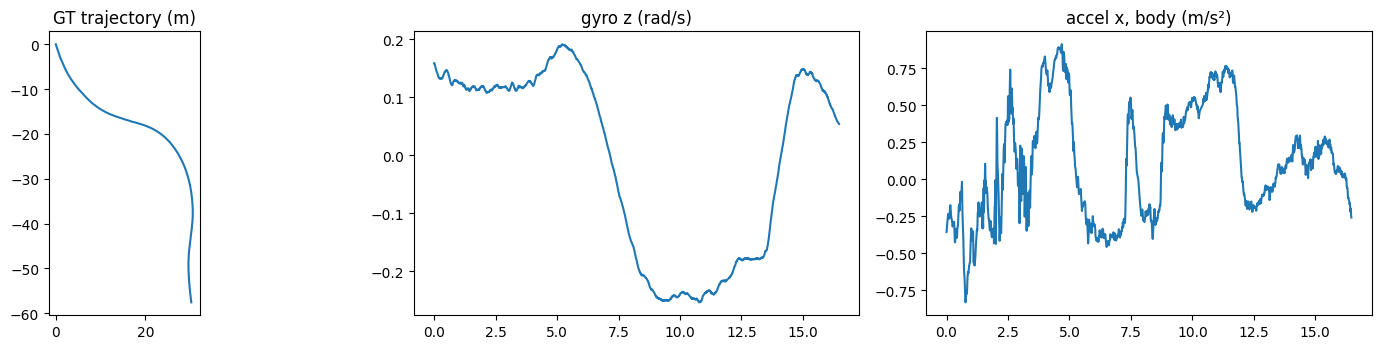

In [6]:
import numpy as np, matplotlib.pyplot as plt

DRIVE = RAW / "extract" / DATE / f"{DATE}_drive_0005_extract"

def read_ts(p):  # 'YYYY-MM-DD HH:MM:SS.nnnnnnnnn' -> int64 ns
    s = [l.strip().replace(" ", "T") for l in open(p) if l.strip()]
    return np.array(s, dtype="datetime64[ns]").astype(np.int64)

cam_ts  = read_ts(DRIVE / "image_02" / "timestamps.txt")
imu_ts  = read_ts(DRIVE / "oxts" / "timestamps.txt")
oxts    = np.stack([np.loadtxt(DRIVE / "oxts" / "data" / f"{i:010d}.txt")
                    for i in range(len(imu_ts))])           # (N, 30)
# field map: 0-2 lat lon alt | 3-5 roll pitch yaw | 11-13 ax ay az (body, with gravity) | 17-19 wx wy wz (body)
lat, lon, alt, roll, pitch, yaw = oxts[:, :6].T
acc, gyr = oxts[:, 11:14], oxts[:, 17:20]
n_png = len(list((DRIVE / "image_02" / "data").glob("*.png")))
print(f"cam: {len(cam_ts)} stamps / {n_png} pngs | imu: {len(imu_ts)} samples")

# rates and gaps
dt_cam, dt_imu = np.diff(cam_ts) * 1e-9, np.diff(imu_ts) * 1e-9
print(f"cam dt  mean {dt_cam.mean()*1e3:.1f} ms  max {dt_cam.max()*1e3:.1f} ms")
print(f"imu dt  mean {dt_imu.mean()*1e3:.1f} ms  max {dt_imu.max()*1e3:.1f} ms")

# IMU samples available between consecutive frames
per_interval = np.array([((imu_ts > a) & (imu_ts <= b)).sum() for a, b in zip(cam_ts[:-1], cam_ts[1:])])
print("IMU samples per camera interval: min/median/max =",
      per_interval.min(), np.median(per_interval), per_interval.max())
print("coverage: first cam before first imu?", cam_ts[0] < imu_ts[0],
      "| last cam after last imu?", cam_ts[-1] > imu_ts[-1])

# ground-truth trajectory in a local frame (KITTI devkit Mercator convention)
scale = np.cos(np.deg2rad(lat[0])); R_E = 6378137.0
mx = scale * np.deg2rad(lon) * R_E
my = scale * R_E * np.log(np.tan(np.pi / 4 + np.deg2rad(lat) / 2))
gt_xy = np.c_[mx - mx[0], my - my[0]]
print(f"GT path length: {np.linalg.norm(np.diff(gt_xy, axis=0), axis=1).sum():.1f} m")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(*gt_xy.T); ax[0].set_aspect("equal"); ax[0].set_title("GT trajectory (m)")
t = (imu_ts - imu_ts[0]) * 1e-9
ax[1].plot(t, gyr[:, 2]); ax[1].set_title("gyro z (rad/s)")
ax[2].plot(t, acc[:, 0]); ax[2].set_title("accel x, body (m/s²)")
plt.tight_layout(); plt.savefig(ROOT / "outputs" / "cell3_sanity.png", dpi=120); plt.show()

In [7]:
# --- A) where are the KITTI IMU timestamps irregular?
dt = np.diff(imu_ts) * 1e-9
bad = np.where((dt > 0.015) | (dt < 0.005))[0]
print(f"{len(bad)} IMU intervals outside 5-15 ms; strictly increasing: {bool((np.diff(imu_ts) > 0).all())}")
for i in bad[:15]:
    print(f"  idx {i:4d}  t={(imu_ts[i]-imu_ts[0])*1e-9:6.3f}s  dt={dt[i]*1e3:6.1f} ms")
odd = np.where((per_interval < 8) | (per_interval > 12))[0]
print("camera intervals with <8 or >12 IMU samples:", odd.tolist(), "->", per_interval[odd].tolist())

# --- B) EuRoC layout
EUROC = Path("/kaggle/input/datasets/danylomarchuk/euroc-cleaned")

def shallow_tree(p, depth=0, max_depth=3):
    kids = sorted(p.iterdir())
    dirs, files = [k for k in kids if k.is_dir()], [k for k in kids if k.is_file()]
    print("  " * depth + f"{p.name}/  ({len(dirs)} dirs, {len(files)} files)")
    if depth < max_depth:
        for d in dirs[:6]: shallow_tree(d, depth + 1, max_depth)
        if len(dirs) > 6: print("  " * (depth + 1) + f"... +{len(dirs)-6} more dirs")

print("\n--- EuRoC tree ---")
shallow_tree(EUROC)

print("\n--- standard EuRoC pieces ---")
for name in ["imu0", "cam0", "cam1", "state_groundtruth_estimate0", "leica0", "vicon0"]:
    hits = sorted(p for p in EUROC.rglob(name) if p.is_dir())
    print(f"{name}: {len(hits)} found", [str(h.relative_to(EUROC)) for h in hits[:3]])

imu_csv = next(EUROC.rglob("imu0/data.csv"), None)
if imu_csv:
    L = imu_csv.read_text().splitlines()
    print("\nimu0/data.csv:", len(L) - 1, "rows\n ", "\n  ".join(L[:3]))
cam_csv = next(EUROC.rglob("cam0/data.csv"), None)
if cam_csv:
    L = cam_csv.read_text().splitlines()
    print("\ncam0/data.csv:", len(L) - 1, "rows\n ", "\n  ".join(L[:3]))
    print("cam0 image files:", len(list(cam_csv.parent.glob("data/*.png"))))
gt_csv = next(EUROC.rglob("state_groundtruth_estimate0/data.csv"), None)
if gt_csv:
    L = gt_csv.read_text().splitlines()
    print("\nground truth:", len(L) - 1, "rows\n ", "\n  ".join(L[:2]))

5 IMU intervals outside 5-15 ms; strictly increasing: False
  idx 1030  t=10.301s  dt= 129.8 ms
  idx 1040  t=10.520s  dt= -50.0 ms
  idx 1047  t=10.530s  dt= -49.8 ms
  idx 1059  t=10.590s  dt=  70.0 ms
  idx 1062  t=10.681s  dt= -50.2 ms
camera intervals with <8 or >12 IMU samples: [0, 100, 102] -> [6, 3, 19]

--- EuRoC tree ---
euroc-cleaned/  (1 dirs, 0 files)
  cleaned/  (2 dirs, 0 files)
    vicon_room1/  (3 dirs, 0 files)
      V1_01_easy/  (1 dirs, 2 files)
      V1_02_medium/  (1 dirs, 2 files)
      V1_03_difficult/  (1 dirs, 2 files)
    vicon_room2/  (3 dirs, 0 files)
      V2_01_easy/  (1 dirs, 2 files)
      V2_02_medium/  (1 dirs, 2 files)
      V2_03_difficult/  (1 dirs, 2 files)

--- standard EuRoC pieces ---
imu0: 0 found []
cam0: 6 found ['cleaned/vicon_room1/V1_01_easy/cam0', 'cleaned/vicon_room1/V1_02_medium/cam0', 'cleaned/vicon_room1/V1_03_difficult/cam0']
cam1: 0 found []
state_groundtruth_estimate0: 0 found []
leica0: 0 found []
vicon0: 0 found []


In [8]:
# --- A) repair KITTI IMU timestamps against the sample index
idx = np.arange(len(imu_ts))
t_s = (imu_ts - imu_ts[0]) * 1e-9
slope, icpt = np.polyfit(idx, t_s, 1)                      # ~10 ms per sample
resid = t_s - (slope * idx + icpt)
med = np.array([np.median(resid[max(0, i-15):i+16]) for i in idx])   # local trend
bad = np.abs(resid - med) > 0.015                          # >15 ms off the local trend
print(f"fit: {slope*1e3:.3f} ms/sample | flagged {bad.sum()} samples: {np.where(bad)[0].tolist()[:30]}")

t_fix = t_s.copy()
t_fix[bad] = np.interp(idx[bad], idx[~bad], t_s[~bad])     # re-time only the flagged ones
imu_ts_fix = imu_ts[0] + (t_fix * 1e9).astype(np.int64)

d2 = np.diff(imu_ts_fix) * 1e-9
print(f"after repair: strictly increasing={bool((d2 > 0).all())}, dt min/max = {d2.min()*1e3:.2f}/{d2.max()*1e3:.2f} ms")
pi2 = np.array([((imu_ts_fix > a) & (imu_ts_fix <= b)).sum() for a, b in zip(cam_ts[:-1], cam_ts[1:])])
print("IMU samples per camera interval: min/median/max =", pi2.min(), np.median(pi2), pi2.max())

# --- B) EuRoC: what are the 2 files per sequence, and what is in cam0?
seq = EUROC / "cleaned" / "vicon_room1" / "V1_01_easy"
for p in sorted(seq.iterdir()):
    print(f"\n{p.name}  ({'dir' if p.is_dir() else f'{p.stat().st_size/1e6:.1f} MB'})")
    if p.is_file():
        lines = p.read_text().splitlines()
        print(f"  {len(lines)} lines; first 3:")
        for l in lines[:3]: print("   ", l[:160])
    else:
        fs = sorted(p.iterdir())
        print(f"  {len(fs)} entries:", [f.name for f in fs[:6]])
        sub = next((f for f in fs if f.is_dir()), None)
        if sub: print(f"  inside {sub.name}/:", [f.name for f in sorted(sub.iterdir())[:4]], "...")

fit: 10.001 ms/sample | flagged 16 samples: [1031, 1032, 1033, 1034, 1035, 1036, 1037, 1038, 1039, 1040, 1048, 1049, 1050, 1060, 1061, 1062]
after repair: strictly increasing=False, dt min/max = -4.99/15.44 ms
IMU samples per camera interval: min/median/max = 6 10.0 16

cam0  (dir)
  2 entries: ['cam_fnames_sequence.csv', 'data']
  inside data/: ['1403715274312143104.png', '1403715274362142976.png', '1403715274412143104.png', '1403715274462142976.png'] ...

gt_array.npy  (0.1 MB)


UnicodeDecodeError: 'utf-8' codec can't decode byte 0x93 in position 0: invalid start byte

In [9]:
# --- A) KITTI: replace the whole glitch stretch, anchored on good samples either side
fl = np.where(bad)[0]
lo, hi = fl.min() - 1, fl.max() + 1
t_fix = t_s.copy()
t_fix[lo:hi + 1] = np.interp(idx[lo:hi + 1], [lo, hi], [t_s[lo], t_s[hi]])
imu_ts_fix = imu_ts[0] + np.round(t_fix * 1e9).astype(np.int64)

d2 = np.diff(imu_ts_fix) * 1e-9
print(f"repaired idx {lo}..{hi} | strictly increasing={bool((d2 > 0).all())} | "
      f"dt min/max = {d2.min()*1e3:.2f}/{d2.max()*1e3:.2f} ms | in-stretch dt = {d2[lo]*1e3:.2f} ms")

# is the sample DATA smooth across the stretch? (checks that only timestamps were corrupted)
gstep = np.linalg.norm(np.diff(gyr, axis=0), axis=1)
print(f"gyro step: max inside stretch {gstep[lo:hi].max():.4f} vs 99th pct overall {np.percentile(gstep, 99):.4f} rad/s")

pi2 = np.array([((imu_ts_fix > a) & (imu_ts_fix <= b)).sum() for a, b in zip(cam_ts[:-1], cam_ts[1:])])
print("IMU samples per camera interval:", dict(zip(*np.unique(pi2, return_counts=True))))

# --- B) EuRoC: open the numpy files and check every sequence has the same layout
np.set_printoptions(precision=6, suppress=True, linewidth=140)
for room in sorted((EUROC / "cleaned").iterdir()):
    for seq in sorted(room.iterdir()):
        files = sorted(p.name for p in seq.iterdir())
        npng = len(list((seq / "cam0" / "data").glob("*.png")))
        print(f"{seq.name:16s} files={files}  cam0 pngs={npng}")

seq = EUROC / "cleaned" / "vicon_room1" / "V1_01_easy"
for p in sorted(seq.glob("*.npy")):
    try:
        a = np.load(p, allow_pickle=False)
    except ValueError as e:
        print(f"\n{p.name}: needs pickle ({e}); not loading it"); continue
    print(f"\n{p.name}: shape={a.shape} dtype={a.dtype}")
    if a.dtype.names: print("  fields:", a.dtype.names)
    print(a[:3])

print("\ncam_fnames_sequence.csv head:")
print((seq / "cam0" / "cam_fnames_sequence.csv").read_text(errors="replace").splitlines()[:3])
pngs = sorted((seq / "cam0" / "data").glob("*.png"))
ts = np.array([int(p.stem) for p in pngs])
print(f"cam: {len(ts)} frames, mean dt {np.diff(ts).mean()*1e-6:.1f} ms, span {(ts[-1]-ts[0])*1e-9:.1f} s")

repaired idx 1030..1063 | strictly increasing=True | dt min/max = 9.77/10.29 ms | in-stretch dt = 10.00 ms
gyro step: max inside stretch 0.0130 vs 99th pct overall 0.0134 rad/s
IMU samples per camera interval: {np.int64(6): np.int64(1), np.int64(10): np.int64(107), np.int64(11): np.int64(51)}
V1_01_easy       files=['cam0', 'gt_array.npy', 'imu_input_array.npy']  cam0 pngs=2871
V1_02_medium     files=['cam0', 'gt_array.npy', 'imu_input_array.npy']  cam0 pngs=1671
V1_03_difficult  files=['cam0', 'gt_array.npy', 'imu_input_array.npy']  cam0 pngs=2094
V2_01_easy       files=['cam0', 'gt_array.npy', 'imu_input_array.npy']  cam0 pngs=2240
V2_02_medium     files=['cam0', 'gt_array.npy', 'imu_input_array.npy']  cam0 pngs=2309
V2_03_difficult  files=['cam0', 'gt_array.npy', 'imu_input_array.npy']  cam0 pngs=1500

gt_array.npy: shape=(2870, 3) dtype=float64
[[0.879045 2.141483 0.947123]
 [0.879311 2.140846 0.947051]
 [0.87951  2.140426 0.947015]]

imu_input_array.npy: shape=(2870, 10, 6) dtype=

In [11]:
%%writefile /kaggle/working/imu_vlm_pipeline/pipeline/data.py
from __future__ import annotations
from dataclasses import dataclass, field
from pathlib import Path
import numpy as np, cv2
from scipy.spatial.transform import Rotation as Rot


@dataclass
class Imu:
    t_ns: np.ndarray      # (N,) int64
    acc: np.ndarray       # (N,3) specific force incl. gravity, m/s^2
    gyr: np.ndarray       # (N,3) rad/s


@dataclass
class Sequence:
    name: str
    frame_ts: np.ndarray              # (F,) int64 ns
    frame_paths: list
    imu: Imu
    gt_t_ns: np.ndarray               # (G,) int64 ns
    gt_p: np.ndarray                  # (G,3) metres, local world frame
    gt_q: np.ndarray | None = None    # (G,4) xyzw, or None if not available
    K: np.ndarray | None = None
    dist: np.ndarray | None = None
    meta: dict = field(default_factory=dict)

    def read_frame(self, i, color=False):
        return cv2.imread(str(self.frame_paths[i]), cv2.IMREAD_COLOR if color else cv2.IMREAD_GRAYSCALE)

    def imu_between(self, t0, t1) -> Imu:
        """IMU samples with t0 < t <= t1."""
        a, b = np.searchsorted(self.imu.t_ns, [t0, t1], side="right")
        return Imu(self.imu.t_ns[a:b], self.imu.acc[a:b], self.imu.gyr[a:b])

    def replay(self, with_images=True):
        """Yield ('imu', t, (acc, gyr)) and ('frame', t, (i, img)) in time order.
        This is the interface a live V4L2/IMU source will implement later."""
        n_i = len(self.imu.t_ns)
        t = np.concatenate([self.imu.t_ns, self.frame_ts])
        kind = np.concatenate([np.zeros(n_i, int), np.ones(len(self.frame_ts), int)])
        for o in np.lexsort((kind, t)):          # sort by time, IMU before frame on ties
            if o < n_i:
                yield "imu", int(t[o]), (self.imu.acc[o], self.imu.gyr[o])
            else:
                i = o - n_i
                yield "frame", int(t[o]), (i, self.read_frame(i) if with_images else None)


# ---------------------------------------------------------------- KITTI
def _read_ts(p):
    s = [l.strip().replace(" ", "T") for l in open(p) if l.strip()]
    return np.array(s, dtype="datetime64[ns]").astype(np.int64)


def repair_timestamps(t_ns, tol_s=0.015, win=15, merge_gap=20):
    """Fix glitched timestamps (jumps/backwards steps). The sample index is the trusted clock:
    flag samples far from the local trend, then re-time each glitch cluster by linear
    interpolation between good anchors on either side."""
    n = len(t_ns); idx = np.arange(n)
    t = (t_ns - t_ns[0]) * 1e-9
    slope, icpt = np.polyfit(idx, t, 1)
    resid = t - (slope * idx + icpt)
    med = np.array([np.median(resid[max(0, i - win):i + win + 1]) for i in idx])
    bad = np.where(np.abs(resid - med) > tol_s)[0]
    t_fix, clusters = t.copy(), []
    if len(bad):
        for g in np.split(bad, np.where(np.diff(bad) > merge_gap)[0] + 1):
            lo, hi = max(g[0] - 1, 0), min(g[-1] + 1, n - 1)
            t_fix[lo:hi + 1] = np.interp(idx[lo:hi + 1], [lo, hi], [t[lo], t[hi]])
            clusters.append((int(lo), int(hi)))
    out = t_ns[0] + np.round(t_fix * 1e9).astype(np.int64)
    if not (np.diff(out) > 0).all():
        print("WARNING: timestamps still not strictly increasing after repair")
    return out, clusters


def load_kitti(drive_dir) -> Sequence:
    d = Path(drive_dir)
    cam_ts = _read_ts(d / "image_02" / "timestamps.txt")
    imu_raw = _read_ts(d / "oxts" / "timestamps.txt")
    imu_ts, clusters = repair_timestamps(imu_raw)
    oxts = np.stack([np.loadtxt(d / "oxts" / "data" / f"{i:010d}.txt") for i in range(len(imu_ts))])
    lat, lon, alt, roll, pitch, yaw = oxts[:, :6].T
    # ground truth: Mercator position (KITTI devkit convention), ENU, first sample = origin
    sc, R_E = np.cos(np.deg2rad(lat[0])), 6378137.0
    mx = sc * np.deg2rad(lon) * R_E
    my = sc * R_E * np.log(np.tan(np.pi / 4 + np.deg2rad(lat) / 2))
    gt_p = np.c_[mx - mx[0], my - my[0], alt - alt[0]]
    gt_q = Rot.from_euler("ZYX", np.c_[yaw, pitch, roll]).as_quat()   # Rz(yaw) Ry(pitch) Rx(roll)
    paths = sorted((d / "image_02" / "data").glob("*.png"))
    return Sequence(
        name=d.name, frame_ts=cam_ts, frame_paths=paths,
        imu=Imu(imu_ts, oxts[:, 11:14].copy(), oxts[:, 17:20].copy()),
        gt_t_ns=imu_ts, gt_p=gt_p, gt_q=gt_q,
        meta=dict(dataset="kitti", imu_hz=100, cam_hz=10, repaired_clusters=clusters,
                  note="OXTS accel/gyro come from a GPS/INS unit (higher grade than a consumer IMU)"))


# ---------------------------------------------------------------- EuRoC (cleaned)
def load_euroc_cleaned(seq_dir) -> Sequence:
    d = Path(seq_dir)
    pngs = sorted((d / "cam0" / "data").glob("*.png"))
    frame_ts = np.array([int(p.stem) for p in pngs], dtype=np.int64)
    arr = np.load(d / "imu_input_array.npy")      # (F-1, 10, 6): accel xyz, gyro xyz

Overwriting /kaggle/working/imu_vlm_pipeline/pipeline/data.py


In [12]:
%%writefile -a /kaggle/working/imu_vlm_pipeline/pipeline/data.py


# ---------------------------------------------------------------- EuRoC (cleaned) -- final definition
def load_euroc_cleaned(seq_dir) -> Sequence:
    d = Path(seq_dir)
    pngs = sorted((d / "cam0" / "data").glob("*.png"))
    frame_ts = np.array([int(p.stem) for p in pngs], dtype=np.int64)
    arr = np.load(d / "imu_input_array.npy")      # (F-1, 10, 6): accel xyz, gyro xyz per camera interval
    gt = np.load(d / "gt_array.npy")              # (F-1, 3) positions
    F = len(frame_ts)
    assert arr.shape[0] == F - 1 and gt.shape[0] == F - 1, (d.name, F, arr.shape, gt.shape)
    k = arr.shape[1]
    frac = np.arange(1, k + 1) / k                # samples evenly spaced; last one lands on the next frame time
    t = (frame_ts[:-1, None] + np.diff(frame_ts)[:, None] * frac[None, :]).round().astype(np.int64)
    flat = arr.reshape(-1, 6)
    return Sequence(
        name=d.name, frame_ts=frame_ts, frame_paths=pngs,
        imu=Imu(t.reshape(-1), flat[:, 0:3].copy(), flat[:, 3:6].copy()),
        gt_t_ns=frame_ts[1:], gt_p=gt.copy(), gt_q=None,
        meta=dict(dataset="euroc_cleaned", imu_hz=200, cam_hz=20,
                  note="IMU timestamps synthesized (even spacing); GT is position only"))

Appending to /kaggle/working/imu_vlm_pipeline/pipeline/data.py


In [13]:
import importlib, pipeline.data as D
importlib.reload(D)
src = Path(D.__file__).read_text()
print("lines:", len(src.splitlines()), "| 'return Sequence(' count:", src.count("return Sequence("))
s = D.load_euroc_cleaned(EUROC / "cleaned" / "vicon_room1" / "V1_01_easy")
print(type(s).__name__, "|", s.name if s else None)

lines: 126 | 'return Sequence(' count: 2
Sequence | V1_01_easy


In [14]:
import cv2

for room in sorted((EUROC / "cleaned").iterdir()):
    for seq in sorted(room.iterdir()):
        rows = (seq / "cam0" / "cam_fnames_sequence.csv").read_text().splitlines()[1:]
        parsed = [r.split(",") for r in rows if r.strip()]
        oidx = np.array([int(p[0]) for p in parsed])
        cts  = np.array([int(p[1]) for p in parsed])
        pngs = sorted((seq / "cam0" / "data").glob("*.png"))
        pts  = np.array([int(p.stem) for p in pngs])
        n_arr = np.load(seq / "imu_input_array.npy", mmap_mode="r").shape[0]
        gaps = np.where(np.diff(oidx) != 1)[0]
        dt = np.diff(cts) * 1e-6
        img = cv2.imread(str(pngs[0]), cv2.IMREAD_GRAYSCALE)
        print(f"{seq.name:16s} csv {len(cts):5d} | png {len(pts):5d} | arrays {n_arr:5d} | "
              f"orig idx {oidx[0]}..{oidx[-1]} | idx gaps {len(gaps)} | "
              f"frame dt {dt.min():.1f}-{dt.max():.1f} ms | img {img.shape} | "
              f"csv==png ts: {np.array_equal(cts, pts)}")
        if len(gaps):
            print("    gap positions (row -> jump):", [(int(g), int(oidx[g+1]-oidx[g])) for g in gaps[:6]])

V1_01_easy       csv  2871 | png  2871 | arrays  2870 | orig idx 21..2891 | idx gaps 0 | frame dt 50.0-50.0 ms | img (120, 188) | csv==png ts: True
V1_02_medium     csv  1671 | png  1671 | arrays  1670 | orig idx 20..1690 | idx gaps 0 | frame dt 50.0-50.0 ms | img (120, 188) | csv==png ts: True
V1_03_difficult  csv  2094 | png  2094 | arrays  2093 | orig idx 36..2129 | idx gaps 0 | frame dt 50.0-50.0 ms | img (120, 188) | csv==png ts: True
V2_01_easy       csv  2240 | png  2240 | arrays  2239 | orig idx 25..2264 | idx gaps 0 | frame dt 50.0-50.0 ms | img (120, 188) | csv==png ts: True
V2_02_medium     csv  2309 | png  2309 | arrays  2308 | orig idx 25..2333 | idx gaps 0 | frame dt 50.0-50.0 ms | img (120, 188) | csv==png ts: True
V2_03_difficult  csv  1500 | png  1500 | arrays  1482 | orig idx 25..1880 | idx gaps 12 | frame dt 50.0-9600.0 ms | img (120, 188) | csv==png ts: True
    gap positions (row -> jump): [(403, 6), (668, 81), (897, 9), (901, 36), (905, 6), (996, 96)]


In [15]:
EUROC_SEQS = [EUROC / "cleaned" / r / s for r, s in [
    ("vicon_room1", "V1_01_easy"), ("vicon_room1", "V1_02_medium"), ("vicon_room1", "V1_03_difficult"),
    ("vicon_room2", "V2_01_easy"), ("vicon_room2", "V2_02_medium")]]

for seq in EUROC_SEQS:
    s = D.load_euroc_cleaned(seq)
    print(f"{s.name:16s} frames {len(s.frame_ts):5d} | imu {len(s.imu.t_ns):6d} | GT path "
          f"{np.linalg.norm(np.diff(s.gt_p, axis=0), axis=1).sum():6.1f} m")

V1_01_easy       frames  2871 | imu  28700 | GT path   58.6 m
V1_02_medium     frames  1671 | imu  16700 | GT path   75.9 m
V1_03_difficult  frames  2094 | imu  20930 | GT path   78.9 m
V2_01_easy       frames  2240 | imu  22390 | GT path   36.4 m
V2_02_medium     frames  2309 | imu  23080 | GT path   83.2 m


In [16]:
%%writefile -a /kaggle/working/imu_vlm_pipeline/pipeline/data.py


# ---------------------------------------------------------------- calibration / undistortion
def parse_kitti_calib(calib_cam_to_cam, cam="02"):
    """Raw (unrectified) intrinsics for one camera from calib_cam_to_cam.txt."""
    kv = {}
    for line in open(calib_cam_to_cam):
        if ":" in line:
            k, v = line.split(":", 1)
            try:
                kv[k.strip()] = np.array(v.split(), dtype=float)
            except ValueError:
                pass                                  # e.g. the calib_time line
    K = kv[f"K_{cam}"].reshape(3, 3)
    D = kv[f"D_{cam}"]                                # k1 k2 p1 p2 k3 (OpenCV order)
    W, H = (int(x) for x in kv[f"S_{cam}"])
    return K, D, (W, H)


class Undistorter:
    """Removes lens distortion but keeps the original K, so the rest of the pipeline uses one matrix."""
    def __init__(self, K, D, size_wh):
        self.K, self.D, self.size = K, D, size_wh
        self.m1, self.m2 = cv2.initUndistortRectifyMap(K, D, None, K, size_wh, cv2.CV_32FC1)

    def __call__(self, img):
        assert img.shape[1] == self.size[0] and img.shape[0] == self.size[1], \
            f"image {img.shape[::-1]} != calibrated size {self.size}"
        return cv2.remap(img, self.m1, self.m2, cv2.INTER_LINEAR)

Appending to /kaggle/working/imu_vlm_pipeline/pipeline/data.py


calib files: ['calib_cam_to_cam.txt', 'calib_imu_to_velo.txt', 'calib_velo_to_cam.txt']
size (W,H): (1392, 512)
K =
 [[959.79   0.   696.02]
 [  0.   956.93 224.18]
 [  0.     0.     1.  ]]
dist (k1 k2 p1 p2 k3): [-0.36915  0.19687  0.00135  0.00057 -0.06771]
raw (512, 1392) -> undistorted (512, 1392)
corner shift (px): [235.6 227.  262.7 252.6]


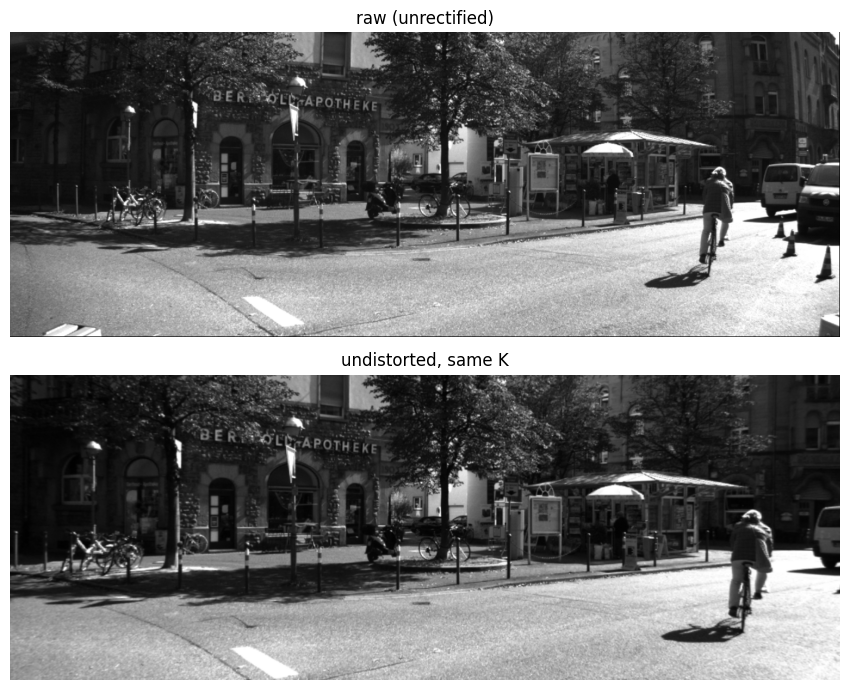

In [17]:
import importlib, pipeline.data as D
importlib.reload(D)

EUROC_SEQS = [EUROC / "cleaned" / r / s for r, s in [
    ("vicon_room1", "V1_01_easy"), ("vicon_room1", "V1_02_medium"), ("vicon_room1", "V1_03_difficult"),
    ("vicon_room2", "V2_01_easy"), ("vicon_room2", "V2_02_medium")]]

# fetch the calibration zip (small)
calz = RAW / f"{DATE}_calib.zip"
if not (RAW / DATE / "calib_cam_to_cam.txt").exists():
    r = subprocess.run(["wget", "-q", "-O", str(calz), f"{BASE}/{DATE}_calib.zip"])
    assert r.returncode == 0 and calz.stat().st_size > 1e3, "calib download failed"
    subprocess.run(["unzip", "-q", "-o", str(calz), "-d", str(RAW)], check=True)
    calz.unlink()
print("calib files:", sorted(p.name for p in (RAW / DATE).glob("calib_*.txt")))

K, Dc, size = D.parse_kitti_calib(RAW / DATE / "calib_cam_to_cam.txt", "02")
print("size (W,H):", size)
print("K =\n", np.round(K, 2))
print("dist (k1 k2 p1 p2 k3):", np.round(Dc, 5))

kitti = D.load_kitti(DRIVE)
kitti.K, kitti.dist = K, Dc
und = D.Undistorter(K, Dc, size)

raw = kitti.read_frame(80)
fix = und(raw)
print("raw", raw.shape, "-> undistorted", fix.shape)

# how strong is the distortion? displacement of the image corners after undistortion
corners = np.array([[0, 0], [size[0] - 1, 0], [0, size[1] - 1], [size[0] - 1, size[1] - 1]], np.float32)[:, None]
moved = cv2.undistortPoints(corners, K, Dc, P=K)[:, 0]
print("corner shift (px):", np.round(np.linalg.norm(moved - corners[:, 0], axis=1), 1))

fig, ax = plt.subplots(2, 1, figsize=(12, 7))
ax[0].imshow(raw, cmap="gray"); ax[0].set_title("raw (unrectified)")
ax[1].imshow(fix, cmap="gray"); ax[1].set_title("undistorted, same K")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(ROOT / "outputs" / "cell9_undistort.png", dpi=110); plt.show()

In [18]:
%%writefile /kaggle/working/imu_vlm_pipeline/pipeline/inertial.py
import numpy as np
from scipy.spatial.transform import Rotation as Rot

G_W = np.array([0.0, 0.0, 9.81])        # gravity in the world frame (z up)


def skew(w):
    return np.array([[0, -w[2], w[1]], [w[2], 0, -w[0]], [-w[1], w[0], 0]])


def exp_so3(w):
    th = np.linalg.norm(w)
    if th < 1e-9:
        return np.eye(3) + skew(w)
    K = skew(w / th)
    return np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * (K @ K)


def attitude_from_gravity(acc, n=30):
    """Body->world rotation from the mean accelerometer reading (assumes ~still). Yaw is arbitrary."""
    a = acc[:n].mean(axis=0)
    rot, _ = Rot.align_vectors([[0.0, 0.0, 1.0]], [a / np.linalg.norm(a)])
    return rot


def strapdown(imu, i0, R0, p0, v0):
    """Integrate gyro + accel from sample i0 (no bias estimation, no corrections).
    R0: scipy Rotation, body->world. Returns t_ns, p, v at samples i0..end."""
    t, acc, gyr = imu.t_ns[i0:], imu.acc[i0:], imu.gyr[i0:]
    n = len(t)
    P, V = np.zeros((n, 3)), np.zeros((n, 3))
    R, p, v = R0.as_matrix(), np.array(p0, float), np.array(v0, float)
    P[0], V[0] = p, v
    for k in range(n - 1):
        dt = (t[k + 1] - t[k]) * 1e-9
        w = 0.5 * (gyr[k] + gyr[k + 1])
        a = 0.5 * (acc[k] + acc[k + 1])
        a_w = R @ exp_so3(0.5 * w * dt) @ a - G_W      # mid-interval attitude
        R = R @ exp_so3(w * dt)
        p = p + v * dt + 0.5 * a_w * dt * dt
        v = v + a_w * dt
        P[k + 1], V[k + 1] = p, v
    return t, P, V

Writing /kaggle/working/imu_vlm_pipeline/pipeline/inertial.py


In [19]:
%%writefile /kaggle/working/imu_vlm_pipeline/pipeline/metrics.py
import numpy as np


def interp_pos(t_est, p_est, t_q):
    return np.stack([np.interp(t_q, t_est, p_est[:, i]) for i in range(3)], axis=1)


def align_yaw_trans(p_est, p_gt):
    """Best-fit yaw + translation (4-DoF). Gravity makes roll/pitch observable, so they stay fixed."""
    me, mg = p_est.mean(0), p_gt.mean(0)
    e, g = p_est - me, p_gt - mg
    th = np.arctan2((e[:, 0] * g[:, 1] - e[:, 1] * g[:, 0]).sum(),
                    (e[:, 0] * g[:, 0] + e[:, 1] * g[:, 1]).sum())
    c, s = np.cos(th), np.sin(th)
    Rz = np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])
    return e @ Rz.T + mg


def rmse(a, b):
    return float(np.sqrt(np.mean(np.sum((a - b) ** 2, axis=1))))


def ate(p_est, p_gt):
    return rmse(align_yaw_trans(p_est, p_gt), p_gt)


def windowed_ate(t_ns, p_est, p_gt, win_s=5.0, min_pts=5):
    """ATE inside consecutive non-overlapping windows, each aligned on its own -> local drift rate."""
    ts = (t_ns - t_ns[0]) * 1e-9
    out = []
    for k in range(int(ts[-1] // win_s)):
        m = (ts >= k * win_s) & (ts < (k + 1) * win_s)
        if m.sum() >= min_pts:
            out.append((k * win_s, ate(p_est[m], p_gt[m])))
    return np.array(out)        # columns: window start (s), ATE (m)

Writing /kaggle/working/imu_vlm_pipeline/pipeline/metrics.py


2011_09_26_drive_0005_extract      16.5s | ATE(full)       0.88 m | end err       2.91 m | 5s-window ATE median    0.21  max     0.42 m
V1_01_easy                        143.5s | ATE(full)   23527.27 m | end err   75207.50 m | 5s-window ATE median  789.82  max  1541.17 m
V1_02_medium                       83.5s | ATE(full)    8669.41 m | end err   29364.36 m | 5s-window ATE median  466.63  max  1094.08 m
V1_03_difficult                   104.6s | ATE(full)   16346.60 m | end err   54042.79 m | 5s-window ATE median  743.72  max  1479.10 m
V2_01_easy                        111.9s | ATE(full)    9968.92 m | end err   34162.27 m | 5s-window ATE median  334.11  max  1254.17 m
V2_02_medium                      115.3s | ATE(full)   12277.98 m | end err   41358.15 m | 5s-window ATE median  404.46  max  1268.83 m


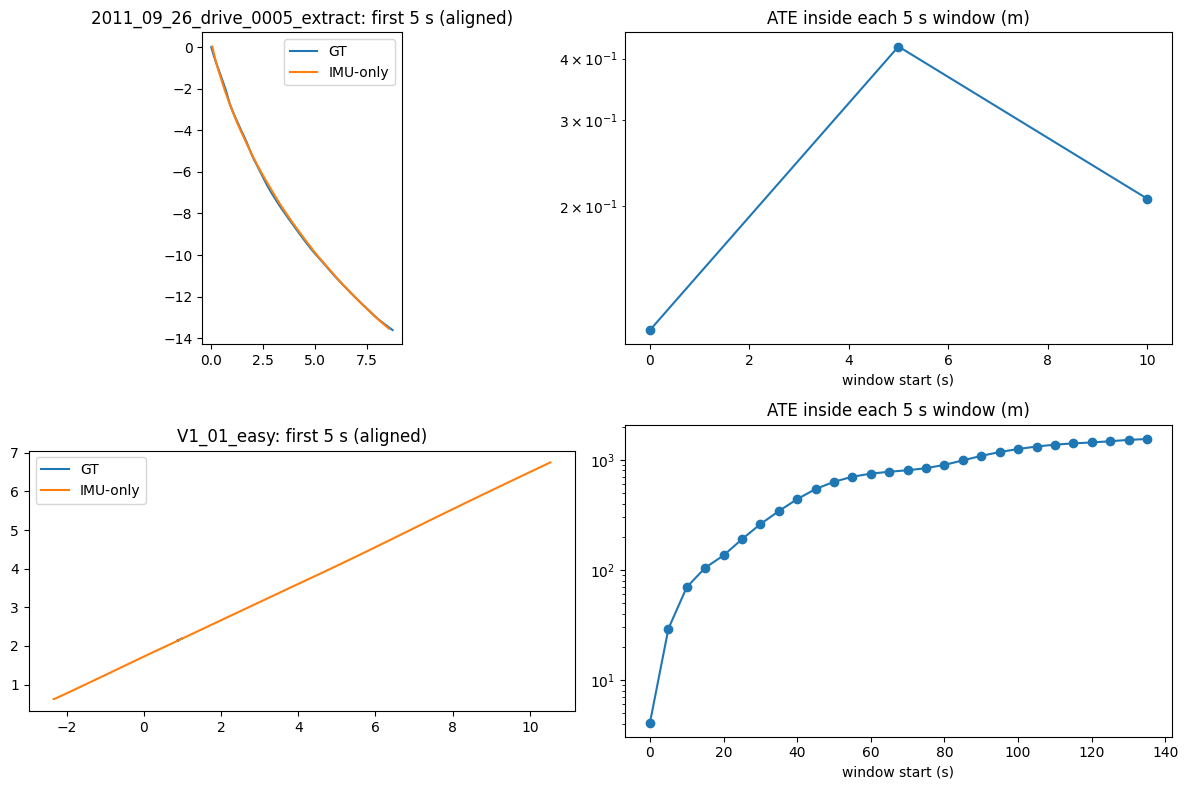

In [20]:
import importlib, pipeline.inertial as I, pipeline.metrics as M
importlib.reload(I); importlib.reload(M)
from scipy.spatial.transform import Rotation as Rot

def run_imu_only(seq):
    i0 = int(np.searchsorted(seq.imu.t_ns, seq.gt_t_ns[0]))
    m = max(int(np.searchsorted(seq.gt_t_ns, seq.gt_t_ns[0] + 200_000_000)), 1)
    v0 = (seq.gt_p[m] - seq.gt_p[0]) / ((seq.gt_t_ns[m] - seq.gt_t_ns[0]) * 1e-9)
    R0 = Rot.from_quat(seq.gt_q[0]) if seq.gt_q is not None else I.attitude_from_gravity(seq.imu.acc[i0:])
    t, P, V = I.strapdown(seq.imu, i0, R0, seq.gt_p[0], v0)
    est = M.interp_pos(t, P, seq.gt_t_ns)
    return dict(est=est, gt=seq.gt_p, t=seq.gt_t_ns, ate=M.ate(est, seq.gt_p),
                win=M.windowed_ate(seq.gt_t_ns, est, seq.gt_p, 5.0),
                end_err=float(np.linalg.norm(est[-1] - seq.gt_p[-1])))

results = {"imu_only": {}}
seqs = [kitti] + [D.load_euroc_cleaned(p) for p in EUROC_SEQS]
for s in seqs:
    r = run_imu_only(s); results["imu_only"][s.name] = r
    w = r["win"][:, 1]
    dur = (s.gt_t_ns[-1] - s.gt_t_ns[0]) * 1e-9
    print(f"{s.name:32s} {dur:6.1f}s | ATE(full) {r['ate']:10.2f} m | end err {r['end_err']:10.2f} m | "
          f"5s-window ATE median {np.median(w):7.2f}  max {w.max():8.2f} m")

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for row, name in enumerate([kitti.name, "V1_01_easy"]):
    r = results["imu_only"][name]
    ts = (r["t"] - r["t"][0]) * 1e-9
    m = ts < 5.0
    e5 = M.align_yaw_trans(r["est"][m], r["gt"][m])
    axs[row, 0].plot(r["gt"][m, 0], r["gt"][m, 1], label="GT")
    axs[row, 0].plot(e5[:, 0], e5[:, 1], label="IMU-only")
    axs[row, 0].set_aspect("equal"); axs[row, 0].legend(); axs[row, 0].set_title(f"{name}: first 5 s (aligned)")
    axs[row, 1].semilogy(r["win"][:, 0], r["win"][:, 1], "o-")
    axs[row, 1].set_title("ATE inside each 5 s window (m)"); axs[row, 1].set_xlabel("window start (s)")
plt.tight_layout(); plt.savefig(ROOT / "outputs" / "cell12_imu_only.png", dpi=110); plt.show()

In [21]:
%%writefile /kaggle/working/imu_vlm_pipeline/pipeline/frontend.py
import time
import numpy as np, cv2

LK_CRIT = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01)


class Tracker:
    """KLT feature tracker: forward-backward check, RANSAC on the fundamental matrix, border mask."""
    def __init__(self, max_feats=300, min_dist=20, border=20, win=21, levels=3,
                 fb_thresh=1.0, ransac_px=1.0, quality=0.01, refill_below=0.8):
        self.max_feats, self.min_dist, self.border = max_feats, min_dist, border
        self.win, self.levels, self.fb_thresh = win, levels, fb_thresh
        self.ransac_px, self.quality, self.refill_below = ransac_px, quality, refill_below
        self.prev = None
        self.pts = np.empty((0, 1, 2), np.float32)
        self.ids = np.empty(0, np.int64)
        self.age = np.empty(0, np.int64)
        self.next_id = 0
        self.dead_lengths = []
        self._mask = None

    def _border_mask(self, shape):
        if self._mask is None or self._mask.shape != shape:
            m = np.zeros(shape, np.uint8)
            b = self.border
            m[b:shape[0] - b, b:shape[1] - b] = 255
            self._mask = m
        return self._mask

    def _inside(self, pts, shape):
        x, y, b = pts[:, 0, 0], pts[:, 0, 1], self.border
        return (x >= b) & (x < shape[1] - b) & (y >= b) & (y < shape[0] - b)

    def step(self, gray):
        T, info = {}, dict(n_prev=len(self.pts), n_klt=0, n_inl=0, n_new=0)
        p_prev = p_cur = np.empty((0, 2), np.float32)
        if self.prev is not None and len(self.pts):
            t0 = time.perf_counter()
            kw = dict(winSize=(self.win, self.win), maxLevel=self.levels, criteria=LK_CRIT)
            nxt, st, _ = cv2.calcOpticalFlowPyrLK(self.prev, gray, self.pts, None, **kw)
            back, st2, _ = cv2.calcOpticalFlowPyrLK(gray, self.prev, nxt, None, **kw)
            T["klt"] = time.perf_counter() - t0
            fb = np.linalg.norm(back - self.pts, axis=2).ravel()
            ok = (st.ravel() == 1) & (st2.ravel() == 1) & (fb < self.fb_thresh) & self._inside(nxt, gray.shape)
            info["n_klt"] = int(ok.sum())

            t0 = time.perf_counter()
            if ok.sum() >= 15:
                _, inl = cv2.findFundamentalMat(self.pts[ok], nxt[ok], cv2.FM_RANSAC, self.ransac_px, 0.99)
                if inl is not None:
                    keep = np.zeros_like(ok)
                    keep[np.where(ok)[0][inl.ravel() == 1]] = True
                    ok = keep
            T["ransac"] = time.perf_counter() - t0
            info["n_inl"] = int(ok.sum())

            self.dead_lengths += self.age[~ok].tolist()
            p_prev = self.pts[ok][:, 0, :].copy()
            self.pts, self.ids, self.age = nxt[ok], self.ids[ok], self.age[ok] + 1
            p_cur = self.pts[:, 0, :].copy()

        t0 = time.perf_counter()
        need = self.max_feats - len(self.pts)
        if self.prev is None or need > (1 - self.refill_below) * self.max_feats:
            m = self._border_mask(gray.shape).copy()
            for x, y in self.pts[:, 0, :]:
                cv2.circle(m, (int(x), int(y)), self.min_dist, 0, -1)
            new = cv2.goodFeaturesToTrack(gray, need, self.quality, self.min_dist, mask=m)
            if new is not None:
                n = len(new)
                self.pts = np.concatenate([self.pts, new.astype(np.float32)])
                self.ids = np.concatenate([self.ids, np.arange(self.next_id, self.next_id + n)])
                self.age = np.concatenate([self.age, np.ones(n, np.int64)])
                self.next_id += n
                info["n_new"] = n
        T["detect"] = time.perf_counter() - t0
        self.prev = gray
        info["n_total"] = len(self.pts)
        return T, info, (p_prev, p_cur)

    def track_lengths(self):
        return np.array(self.dead_lengths + self.age.tolist())

Writing /kaggle/working/imu_vlm_pipeline/pipeline/frontend.py



[kitti 0005 (undistorted)] 160 frames
  read    p50   17.45 ms   p99   20.73 ms
  prep    p50    1.44 ms   p99    1.90 ms
  klt     p50   10.90 ms   p99   17.04 ms
  ransac  p50    0.54 ms   p99    1.06 ms
  detect  p50    9.90 ms   p99   11.54 ms
  total   p50   40.38 ms   p99   52.03 ms
  tracked after RANSAC per frame: median 273  min 182
  survival (RANSAC inliers / previous): 0.71 | RANSAC inlier ratio: 0.89
  track length (frames): mean 3.4  median 1  max 105

[euroc V1_01_easy, 600 frames @188x120] 600 frames
  read    p50   57.63 ms   p99  118.03 ms
  prep    p50    0.00 ms   p99    0.00 ms
  klt     p50    1.43 ms   p99    2.22 ms
  ransac  p50    0.17 ms   p99    0.29 ms
  detect  p50    1.30 ms   p99    1.74 ms
  total   p50   60.23 ms   p99  121.13 ms
  tracked after RANSAC per frame: median 104  min 8
  survival (RANSAC inliers / previous): 0.97 | RANSAC inlier ratio: 1.00
  track length (frames): mean 29.0  median 6  max 276


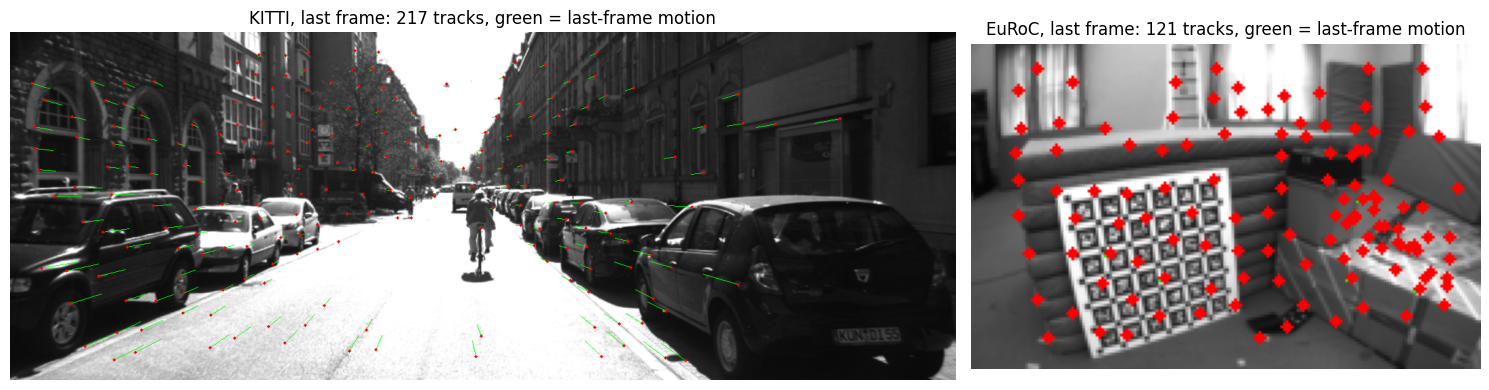

In [22]:
import time, importlib, pipeline.frontend as FE
importlib.reload(FE)

def run_frontend(seq, n_frames, prep=None, **kw):
    trk, rows, last = FE.Tracker(**kw), [], None
    for i in range(n_frames):
        t0 = time.perf_counter(); img = seq.read_frame(i);  t_read = time.perf_counter() - t0
        t0 = time.perf_counter(); img = prep(img) if prep else img; t_prep = time.perf_counter() - t0
        T, info, vis = trk.step(img)
        T.update(read=t_read, prep=t_prep)
        rows.append((T, info)); last = (img, vis)
    return trk, rows, last

def report(name, trk, rows):
    print(f"\n[{name}] {len(rows)} frames")
    stages = ["read", "prep", "klt", "ransac", "detect"]
    tot = np.array([sum(T.get(s, 0) for s in stages) for T, _ in rows[1:]]) * 1e3
    for s in stages:
        v = np.array([T[s] for T, _ in rows[1:] if s in T]) * 1e3
        print(f"  {s:7s} p50 {np.percentile(v, 50):7.2f} ms   p99 {np.percentile(v, 99):7.2f} ms")
    print(f"  total   p50 {np.percentile(tot, 50):7.2f} ms   p99 {np.percentile(tot, 99):7.2f} ms")
    I_ = rows[1:]
    n_tot = np.array([i["n_total"] for _, i in I_]); n_klt = np.array([i["n_klt"] for _, i in I_])
    n_inl = np.array([i["n_inl"] for _, i in I_]);   n_prev = np.array([i["n_prev"] for _, i in I_])
    L = trk.track_lengths()
    print(f"  tracked after RANSAC per frame: median {np.median(n_inl):.0f}  min {n_inl.min()}")
    print(f"  survival (RANSAC inliers / previous): {np.mean(n_inl / np.maximum(n_prev, 1)):.2f} | "
          f"RANSAC inlier ratio: {np.mean(n_inl / np.maximum(n_klt, 1)):.2f}")
    print(f"  track length (frames): mean {L.mean():.1f}  median {np.median(L):.0f}  max {L.max()}")

trk_k, rows_k, last_k = run_frontend(kitti, len(kitti.frame_ts), prep=und,
                                     max_feats=400, min_dist=25, border=25, win=21, levels=3)
report("kitti 0005 (undistorted)", trk_k, rows_k)

e1 = D.load_euroc_cleaned(EUROC_SEQS[0])
trk_e, rows_e, last_e = run_frontend(e1, 600, max_feats=150, min_dist=10, border=8, win=15, levels=2)
report("euroc V1_01_easy, 600 frames @188x120", trk_e, rows_e)

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw=dict(width_ratios=[2.6, 1.4]))
for ax, (img, (pp, pc)), title in [(axs[0], last_k, "KITTI, last frame"), (axs[1], last_e, "EuRoC, last frame")]:
    vis = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    for a, b in zip(pp, pc):
        cv2.line(vis, (int(a[0]), int(a[1])), (int(b[0]), int(b[1])), (0, 255, 0), 1)
        cv2.circle(vis, (int(b[0]), int(b[1])), 2, (0, 0, 255), -1)
    ax.imshow(vis[:, :, ::-1]); ax.set_title(f"{title}: {len(pc)} tracks, green = last-frame motion"); ax.axis("off")
plt.tight_layout(); plt.savefig(ROOT / "outputs" / "cell14_tracks.png", dpi=110); plt.show()

In [23]:
import importlib, pipeline.frontend as FE

p = Path(FE.__file__); src = p.read_text()
def sub(old, new):
    global src
    assert src.count(old) == 1, f"patch target not found exactly once:\n{old}"
    src = src.replace(old, new)

sub('''            ok = (st.ravel() == 1) & (st2.ravel() == 1) & (fb < self.fb_thresh) & self._inside(nxt, gray.shape)
            info["n_klt"] = int(ok.sum())''',
'''            s_ok = (st.ravel() == 1) & (st2.ravel() == 1)
            f_ok = fb < self.fb_thresh
            b_ok = self._inside(nxt, gray.shape)
            ok = s_ok & f_ok & b_ok
            info["d_status"] = int((~s_ok).sum())
            info["d_fb"] = int((s_ok & ~f_ok).sum())
            info["d_border"] = int((s_ok & f_ok & ~b_ok).sum())
            info["n_klt"] = int(ok.sum())''')
sub('''            info["n_inl"] = int(ok.sum())''',
'''            info["d_ransac"] = info["n_klt"] - int(ok.sum())
            info["n_inl"] = int(ok.sum())''')
p.write_text(src); importlib.reload(FE)

def run_cached(frames, **kw):
    trk, rows = FE.Tracker(**kw), []
    for g in frames:
        T, info, _ = trk.step(g); rows.append((T, info))
    return trk, rows

def deaths(name, rows):
    tot = {k: sum(i.get(k, 0) for _, i in rows) for k in ("d_status", "d_fb", "d_border", "d_ransac")}
    n = sum(tot.values())
    print(f"\n[{name}] features lost: {n}")
    for k, v in tot.items():
        print(f"  {k[2:]:7s} {v:6d}  ({100*v/max(n,1):4.1f}%)")

def compute_ms(rows):
    v = np.array([sum(T.get(s, 0) for s in ("klt", "ransac", "detect")) for T, _ in rows[1:]]) * 1e3
    return np.percentile(v, 50), np.percentile(v, 99)

# KITTI: undistort first (timed separately, it is a pipeline stage), then track
kit_frames = [kitti.read_frame(i) for i in range(len(kitti.frame_ts))]
t0 = time.perf_counter(); kit_und = [und(g) for g in kit_frames]; t_und = (time.perf_counter() - t0) / len(kit_frames) * 1e3
trk_k, rows_k = run_cached(kit_und, max_feats=400, min_dist=25, border=25, win=21, levels=3)
deaths("kitti, baseline settings", rows_k)
p50, p99 = compute_ms(rows_k)
print(f"  compute-only per frame (klt+ransac+detect): p50 {p50:.1f} ms  p99 {p99:.1f} ms  (+ undistort {t_und:.2f} ms mean)")

e1 = D.load_euroc_cleaned(EUROC_SEQS[0])
eu_frames = [e1.read_frame(i) for i in range(600)]       # preloaded: removes the slow input-mount reads
trk_e, rows_e = run_cached(eu_frames, max_feats=150, min_dist=10, border=8, win=15, levels=2)
deaths("euroc V1_01_easy, 600 frames", rows_e)
p50, p99 = compute_ms(rows_e)
print(f"  compute-only per frame: p50 {p50:.1f} ms  p99 {p99:.1f} ms")

# KITTI with stricter corner quality and no aggressive refill, to see if the fixable cause matters
for q, refill in [(0.05, 0.8), (0.05, 0.5)]:
    t_, r_ = run_cached(kit_und, max_feats=400, min_dist=25, border=25, win=21, levels=3,
                        quality=q, refill_below=refill)
    L = t_.track_lengths(); n_inl = np.array([i["n_inl"] for _, i in r_[1:]])
    print(f"\nkitti quality={q} refill_below={refill}: tracks/frame median {np.median(n_inl):.0f} "
          f"min {n_inl.min()} | length mean {L.mean():.1f} median {np.median(L):.0f} max {L.max()}")


[kitti, baseline settings] features lost: 17699
  status    1675  ( 9.5%)
  fb        8535  (48.2%)
  border    2178  (12.3%)
  ransac    5311  (30.0%)
  compute-only per frame (klt+ransac+detect): p50 21.5 ms  p99 34.3 ms  (+ undistort 1.37 ms mean)

[euroc V1_01_easy, 600 frames] features lost: 2020
  status     278  (13.8%)
  fb         403  (20.0%)
  border    1128  (55.8%)
  ransac     211  (10.4%)
  compute-only per frame: p50 2.7 ms  p99 3.4 ms

kitti quality=0.05 refill_below=0.8: tracks/frame median 212 min 92 | length mean 3.9 median 1 max 106

kitti quality=0.05 refill_below=0.5: tracks/frame median 187 min 92 | length mean 4.7 median 1 max 106


In [24]:
import importlib, pipeline.frontend as FE
print(subprocess.run("lscpu | grep -E 'Model name|^CPU\\(s\\)'", shell=True, capture_output=True, text=True).stdout)

p = Path(FE.__file__); src = p.read_text()
def sub(old, new):
    global src
    assert src.count(old) == 1, f"patch target not found exactly once:\n{old}"
    src = src.replace(old, new)
if "_dbg" not in src:
    sub('''            ok = s_ok & f_ok & b_ok
''', '''            ok = s_ok & f_ok & b_ok
            self._dbg = dict(pts=self.pts[:, 0, :].copy(), age=self.age.copy(), s=s_ok, f=f_ok, b=b_ok)
''')
    sub('''            info["d_ransac"] = info["n_klt"] - int(ok.sum())
''', '''            info["d_ransac"] = info["n_klt"] - int(ok.sum())
            self._dbg["final"] = ok.copy()
''')
    p.write_text(src)
importlib.reload(FE)

def run_dbg(frames, **kw):
    trk, rows, dbg = FE.Tracker(**kw), [], []
    for g in frames:
        T, info, _ = trk.step(g); rows.append((T, info))
        if getattr(trk, "_dbg", None) is not None and "final" in trk._dbg:
            dbg.append(trk._dbg); trk._dbg = None
    return trk, rows, dbg

base = dict(max_feats=400, min_dist=25, border=25, win=21, levels=3)
trk, rows, dbg = run_dbg(kit_und, **base)

pts  = np.concatenate([d["pts"] for d in dbg]); age = np.concatenate([d["age"] for d in dbg])
died = ~np.concatenate([d["final"] for d in dbg])
r = np.hypot(pts[:, 0] - K[0, 2], pts[:, 1] - K[1, 2])
print("\nper-step death rate by distance from the principal point")
for lo, hi in zip([0, 150, 300, 450, 600], [150, 300, 450, 600, 800]):
    m = (r >= lo) & (r < hi)
    print(f"  r {lo:3d}-{hi:3d} px: {m.sum():6d} feature-steps, {100*died[m].mean():4.1f}% die")
print("per-step death rate by image row band")
for lo in range(0, 512, 128):
    m = (pts[:, 1] >= lo) & (pts[:, 1] < lo + 128)
    print(f"  y {lo:3d}-{lo+127:3d}: {m.sum():6d} feature-steps, {100*died[m].mean():4.1f}% die")
for a in (1, 2, 3):
    m = age == a
    print(f"  age {a}: {m.sum():6d} feature-steps, {100*died[m].mean():4.1f}% die")

print("\nsearch-size variants (KITTI)")
print(f"{'config':34s} {'trk/frm med':>11s} {'min':>4s} {'len mean':>8s} {'len med':>7s} {'fb%':>5s} {'stat%':>5s} {'ransac%':>7s} {'ms p50':>7s}")
variants = [("levels3 win21 (baseline)", base),
            ("levels4 win21", dict(base, levels=4)),
            ("levels5 win31", dict(base, levels=5, win=31)),
            ("levels5 win31 fb<2px", dict(base, levels=5, win=31, fb_thresh=2.0))]
for name, kw in variants:
    t_, r_, _ = run_dbg(kit_und, **kw)
    n_inl = np.array([i["n_inl"] for _, i in r_[1:]]); L = t_.track_lengths()
    tot = {k: sum(i.get(k, 0) for _, i in r_) for k in ("d_status", "d_fb", "d_border", "d_ransac")}; n = sum(tot.values())
    ms = np.percentile([sum(T.get(s, 0) for s in ("klt", "ransac", "detect")) * 1e3 for T, _ in r_[1:]], 50)
    print(f"{name:34s} {np.median(n_inl):11.0f} {n_inl.min():4d} {L.mean():8.1f} {np.median(L):7.0f} "
          f"{100*tot['d_fb']/n:5.1f} {100*tot['d_status']/n:5.1f} {100*tot['d_ransac']/n:7.1f} {ms:7.1f}")

CPU(s):                                  4
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz


per-step death rate by distance from the principal point
  r   0-150 px:   8249 feature-steps,  9.5% die
  r 150-300 px:  19242 feature-steps, 23.7% die
  r 300-450 px:  15371 feature-steps, 33.7% die
  r 450-600 px:  11925 feature-steps, 34.0% die
  r 600-800 px:   5474 feature-steps, 57.0% die
per-step death rate by image row band
  y   0-127:  14867 feature-steps, 19.8% die
  y 128-255:  18044 feature-steps, 12.9% die
  y 256-383:  15215 feature-steps, 30.7% die
  y 384-511:  12135 feature-steps, 63.8% die
  age 1:  17916 feature-steps, 68.7% die
  age 2:   5559 feature-steps, 28.9% die
  age 3:   3935 feature-steps, 20.3% die

search-size variants (KITTI)
config                             trk/frm med  min len mean len med   fb% stat% ransac%  ms p50
levels3 win21 (baseline)                   273  182      3.4       1  48.2   9.5    30.0    21.2
levels4 win21        

In [25]:
%%writefile -a /kaggle/working/imu_vlm_pipeline/pipeline/inertial.py


def rel_rot(imu, t0, t1):
    """Body rotation between t0 < t1 from the gyro: R_wb(t0)^T R_wb(t1), i.e. body_t1 -> body_t0.
    Integrates exactly between t0 and t1 (gyro interpolated at both ends)."""
    m = (imu.t_ns > t0) & (imu.t_ns < t1)
    ts = np.concatenate([[t0], imu.t_ns[m], [t1]])
    g = np.stack([np.interp(ts, imu.t_ns, imu.gyr[:, i]) for i in range(3)], axis=1)
    R = np.eye(3)
    for k in range(len(ts) - 1):
        dt = (ts[k + 1] - ts[k]) * 1e-9
        R = R @ exp_so3(0.5 * (g[k] + g[k + 1]) * dt)
    return R

Appending to /kaggle/working/imu_vlm_pipeline/pipeline/inertial.py


In [26]:
import importlib, pipeline.inertial as I, pipeline.frontend as FE
importlib.reload(I); importlib.reload(FE)
from scipy.spatial.transform import Rotation as Rot

def parse_kv(path):
    kv = {}
    for line in open(path):
        if ":" in line:
            k, v = line.split(":", 1)
            try: kv[k.strip()] = np.array(v.split(), dtype=float)
            except ValueError: pass
    return kv

cal = RAW / DATE
R_iv = parse_kv(cal / "calib_imu_to_velo.txt")["R"].reshape(3, 3)     # IMU  -> velodyne
R_vc = parse_kv(cal / "calib_velo_to_cam.txt")["R"].reshape(3, 3)     # velodyne -> camera 0
R_02 = parse_kv(cal / "calib_cam_to_cam.txt")["R_02"].reshape(3, 3)   # camera 0 -> camera 2 (assumed)
Rcb_A = R_02 @ R_vc @ R_iv          # camera-from-body, assumed convention
Rcb_B = R_02.T @ R_vc @ R_iv        # if R_02 is the other way round
print("R_cam<-body (convention A), expect roughly a signed axis permutation:\n", np.round(Rcb_A, 3))

# track the undistorted KITTI frames, keep each frame pair's inlier correspondences
base = dict(max_feats=400, min_dist=25, border=25, win=21, levels=3)
trk, recs = FE.Tracker(**base), []
for g in kit_und:
    _, _, (pp, pc) = trk.step(g)
    recs.append((pp, pc, int((trk.age >= 3).sum())))
print(f"active tracks with >= 3 observations per frame: median {np.median([r[2] for r in recs[3:]]):.0f}")

ang = lambda A, B: np.degrees(np.linalg.norm(Rot.from_matrix(A.T @ B).as_rotvec()))
out = []
for i in range(1, len(kit_und)):
    pp, pc, _ = recs[i]
    if len(pp) < 30: continue
    E, m = cv2.findEssentialMat(pp, pc, K, cv2.RANSAC, 0.999, 1.0)
    if E is None: continue
    n_in, R_vo, t_vo, _ = cv2.recoverPose(E[:3], pp, pc, K, mask=m)    # prev cam -> cur cam
    dR = I.rel_rot(kitti.imu, kitti.frame_ts[i - 1], kitti.frame_ts[i])
    pred = lambda Rcb: Rcb @ dR.T @ Rcb.T                              # same quantity, from the gyro
    out.append((ang(np.eye(3), R_vo), ang(R_vo, pred(Rcb_A)), ang(R_vo, pred(Rcb_B)),
                ang(R_vo, pred(np.eye(3))), ang(np.eye(3), pred(Rcb_A)), int(n_in)))
out = np.array(out)

print(f"\n{len(out)} frame pairs used")
print(f"median rotation per frame: vision {np.median(out[:,0]):.3f} deg | gyro {np.median(out[:,4]):.3f} deg")
for name, col in [("A: R_02 as assumed", 1), ("B: R_02 transposed", 2), ("C: no extrinsics (identity)", 3)]:
    e = out[:, col]
    print(f"vision-vs-gyro rotation error, {name:28s}: median {np.median(e):.3f} deg   p90 {np.percentile(e, 90):.3f} deg")
print(f"inliers after recoverPose: median {np.median(out[:,5]):.0f}")

R_cam<-body (convention A), expect roughly a signed axis permutation:
 [[ 0.004 -1.     0.019]
 [ 0.009 -0.019 -1.   ]
 [ 1.     0.004  0.009]]
active tracks with >= 3 observations per frame: median 232

159 frame pairs used
median rotation per frame: vision 0.888 deg | gyro 0.864 deg
vision-vs-gyro rotation error, A: R_02 as assumed          : median 0.087 deg   p90 0.189 deg
vision-vs-gyro rotation error, B: R_02 transposed          : median 0.090 deg   p90 0.194 deg
vision-vs-gyro rotation error, C: no extrinsics (identity) : median 1.303 deg   p90 1.984 deg
inliers after recoverPose: median 132


In [27]:
%%writefile /kaggle/working/imu_vlm_pipeline/pipeline/eskf.py
import numpy as np
from .inertial import exp_so3, skew, G_W


class ESKF:
    """Error-state EKF core. Nominal state: R (body->world), v, p, bg, ba.
    Error state (15): [dtheta, dv, dp, dbg, dba], attitude error in the local frame: R = R_hat * exp(dtheta)."""
    def __init__(self, R0, v0, p0, bg0=None, ba0=None,
                 sig_g=1.7e-4, sig_a=2e-3, sig_bg=1.9e-5, sig_ba=3e-3, P0=None):
        self.R, self.v, self.p = np.array(R0, float), np.array(v0, float), np.array(p0, float)
        self.bg = np.zeros(3) if bg0 is None else np.array(bg0, float)
        self.ba = np.zeros(3) if ba0 is None else np.array(ba0, float)
        self.sig = (sig_g, sig_a, sig_bg, sig_ba)          # continuous noise densities / random walks
        self.P = (np.diag([1e-4] * 3 + [1e-2] * 3 + [1e-4] * 3 + [1e-6] * 3 + [1e-4] * 3)
                  if P0 is None else np.array(P0, float))

    def propagate(self, acc0, gyr0, acc1, gyr1, dt):
        sg, sa, sbg, sba = self.sig
        w = 0.5 * (gyr0 + gyr1) - self.bg
        a = 0.5 * (acc0 + acc1) - self.ba
        R = self.R
        a_w = (R @ exp_so3(0.5 * w * dt)) @ a - G_W

        F = np.eye(15)
        F[0:3, 0:3] -= skew(w) * dt
        F[0:3, 9:12] = -np.eye(3) * dt
        F[3:6, 0:3] = -R @ skew(a) * dt
        F[3:6, 12:15] = -R * dt
        F[6:9, 3:6] = np.eye(3) * dt
        Q = np.zeros((15, 15))
        Q[0:3, 0:3] = np.eye(3) * sg ** 2 * dt
        Q[3:6, 3:6] = np.eye(3) * sa ** 2 * dt
        Q[9:12, 9:12] = np.eye(3) * sbg ** 2 * dt
        Q[12:15, 12:15] = np.eye(3) * sba ** 2 * dt
        self.P = F @ self.P @ F.T + Q

        self.p = self.p + self.v * dt + 0.5 * a_w * dt * dt
        self.v = self.v + a_w * dt
        self.R = R @ exp_so3(w * dt)

Writing /kaggle/working/imu_vlm_pipeline/pipeline/eskf.py


In [29]:
import importlib, pipeline.eskf as EK
importlib.reload(EK)

def run_propagation(seq, **kw):
    imu = seq.imu
    i0 = int(np.searchsorted(imu.t_ns, seq.gt_t_ns[0]))
    m = max(int(np.searchsorted(seq.gt_t_ns, seq.gt_t_ns[0] + 200_000_000)), 1)
    v0 = (seq.gt_p[m] - seq.gt_p[0]) / ((seq.gt_t_ns[m] - seq.gt_t_ns[0]) * 1e-9)
    R0 = Rot.from_quat(seq.gt_q[0]) if seq.gt_q is not None else I.attitude_from_gravity(imu.acc[i0:])
    f = EK.ESKF(R0.as_matrix(), v0, seq.gt_p[0], **kw)
    n = len(imu.t_ns) - i0
    Pos, sig = np.zeros((n, 3)), np.zeros(n)
    Pos[0], sig[0] = f.p, np.sqrt(np.trace(f.P[6:9, 6:9]))
    for k in range(n - 1):
        j = i0 + k
        f.propagate(imu.acc[j], imu.gyr[j], imu.acc[j + 1], imu.gyr[j + 1], (imu.t_ns[j + 1] - imu.t_ns[j]) * 1e-9)
        Pos[k + 1], sig[k + 1] = f.p, np.sqrt(np.trace(f.P[6:9, 6:9]))
    return imu.t_ns[i0:], Pos, sig

# 1) must reproduce the strapdown baseline
for s in (kitti, D.load_euroc_cleaned(EUROC_SEQS[0])):
    t, Pos, sig = run_propagation(s)
    est = M.interp_pos(t, Pos, s.gt_t_ns)
    ref = results["imu_only"][s.name]["est"]
    print(f"{s.name:32s} max |ESKF - strapdown| = {np.abs(est - ref).max():.2e} m | "
          f"ATE {M.ate(est, s.gt_p):.2f} m (baseline {results['imu_only'][s.name]['ate']:.2f})")

# 2) KITTI: actual (unaligned) position error vs the filter's own predicted sigma
t, Pos, sig = run_propagation(kitti)
est = M.interp_pos(t, Pos, kitti.gt_t_ns)
err = np.linalg.norm(est - kitti.gt_p, axis=1)
ts = (kitti.gt_t_ns - kitti.gt_t_ns[0]) * 1e-9
sg = np.interp(kitti.gt_t_ns, t, sig)
print("\nKITTI 0005: actual error vs predicted 1-sigma position (trace of P_pp)")
for tt in (2, 4, 8, 12, 16):
    k = int(np.searchsorted(ts, tt))
    print(f"  t={tt:2d}s  actual {err[k]:6.2f} m   predicted sigma {sg[k]:6.2f} m   ratio {err[k]/sg[k]:5.2f}")

2011_09_26_drive_0005_extract    max |ESKF - strapdown| = 0.00e+00 m | ATE 0.88 m (baseline 0.88)
V1_01_easy                       max |ESKF - strapdown| = 0.00e+00 m | ATE 23527.27 m (baseline 23527.27)

KITTI 0005: actual error vs predicted 1-sigma position (trace of P_pp)
  t= 2s  actual   0.45 m   predicted sigma   0.44 m   ratio  1.02
  t= 4s  actual   0.84 m   predicted sigma   1.32 m   ratio  0.64
  t= 8s  actual   1.43 m   predicted sigma   4.83 m   ratio  0.30
  t=12s  actual   2.31 m   predicted sigma  10.98 m   ratio  0.21
  t=16s  actual   2.85 m   predicted sigma  20.28 m   ratio  0.14


In [30]:
import dataclasses
results["imu_only_staticinit"] = {}
sg_all, sa_all = [], []

def still_end(s, v_thresh=0.03):
    dt = np.diff(s.gt_t_ns) * 1e-9
    sp = np.linalg.norm(np.diff(s.gt_p, axis=0), axis=1) / dt
    sp = np.convolve(sp, np.ones(5) / 5, mode="same")           # smooth mocap jitter
    mv = np.where(sp > v_thresh)[0]
    return s.gt_t_ns[mv[0]] if len(mv) else s.gt_t_ns[-1]

print(f"{'seq':16s} {'still s':>7s} {'gyro bias (rad/s)':>30s} {'|bias|':>7s} {'sig_g':>8s} {'|mean acc|':>10s} {'sig_a':>8s}"
      f" | {'ATE base':>9s} -> {'ATE +static init':>16s} | 5s-win median")
for path in EUROC_SEQS:
    s = D.load_euroc_cleaned(path)
    m = s.imu.t_ns <= still_end(s)
    dur = (s.imu.t_ns[m][-1] - s.imu.t_ns[0]) * 1e-9 if m.sum() else 0
    if dur < 0.5:
        print(f"{s.name:16s} no still window >= 0.5 s at the start (moving from the beginning)"); continue
    g, a = s.imu.gyr[m], s.imu.acc[m]
    bg = g.mean(0)
    sig_g, sig_a = g.std(0).mean() * np.sqrt(0.005), a.std(0).mean() * np.sqrt(0.005)   # per-sample std -> density at 200 Hz
    sg_all.append(sig_g); sa_all.append(sig_a)

    s2 = dataclasses.replace(s, imu=D.Imu(s.imu.t_ns, s.imu.acc, s.imu.gyr - bg))
    r2 = run_imu_only(s2); results["imu_only_staticinit"][s.name] = r2
    print(f"{s.name:16s} {dur:7.1f} {np.array2string(bg, precision=4):>30s} {np.linalg.norm(bg):7.4f} "
          f"{sig_g:8.2e} {np.linalg.norm(a.mean(0)):10.3f} {sig_a:8.2e}"
          f" | {results['imu_only'][s.name]['ate']:9.1f} -> {r2['ate']:16.1f} | {np.median(r2['win'][:,1]):6.1f} m")

if sg_all:
    print(f"\nimplied noise density, median over sequences: gyro {np.median(sg_all):.2e} rad/s/rtHz (ESKF default 1.7e-04), "
          f"accel {np.median(sa_all):.2e} m/s^2/rtHz (default 2.0e-03)")

seq              still s              gyro bias (rad/s)  |bias|    sig_g |mean acc|    sig_a |  ATE base -> ATE +static init | 5s-win median
V1_01_easy           4.1      [-0.0036  0.0223  0.0778]  0.0810 1.87e-03      9.782 4.07e-02 |   23527.3 ->            808.0 |   15.9 m
V1_02_medium         3.5      [-0.002   0.016   0.0774]  0.0790 1.60e-03      9.794 2.69e-02 |    8669.4 ->            793.8 |   42.6 m
V1_03_difficult      5.0      [-0.0018  0.0219  0.0786]  0.0816 1.71e-03      9.785 3.45e-02 |   16346.6 ->            705.7 |   27.7 m
V2_01_easy           3.1      [-0.004   0.0179  0.0835]  0.0854 2.05e-03      9.782 3.65e-02 |    9968.9 ->           1491.9 |   50.6 m
V2_02_medium         2.2      [-0.0016  0.0186  0.0819]  0.0840 1.88e-03      9.788 3.20e-02 |   12278.0 ->           1889.4 |   65.9 m

implied noise density, median over sequences: gyro 1.87e-03 rad/s/rtHz (ESKF default 1.7e-04), accel 3.45e-02 m/s^2/rtHz (default 2.0e-03)


In [32]:
import numpy as np
from pathlib import Path

# patch: expose the state-transition matrix from ESKF.propagate (needed to propagate cross-covariance)
p = Path("/kaggle/working/imu_vlm_pipeline/pipeline/eskf.py"); s = p.read_text()
if "self._F = F" not in s:
    old = "        self.P = F @ self.P @ F.T + Q\n"
    assert s.count(old) == 1, "patch target not found exactly once"
    p.write_text(s.replace(old, "        self._F = F\n" + old))

VIO_SRC = r'''
import numpy as np
from scipy.spatial.transform import Rotation as Rot
from .eskf import ESKF
from .inertial import exp_so3, skew

IX = np.r_[0:3, 6:9]                  # theta and p inside the 15-dim nav error state
CHI2_99 = {3: 11.34, 5: 15.09}


def log_so3(R):
    return Rot.from_matrix(R).as_rotvec()


class VIOFilter(ESKF):
    # ESKF plus one stochastic clone (rotation, position) of the pose at the previous camera time.
    # Joint error state: [nav 15 | clone theta 3 | clone p 3] = 21
    def __init__(self, *a, **k):
        super().__init__(*a, **k)
        self.clone = None
        self.Cc = None                # (15, 6) nav x clone cross-covariance
        self.Pcc = None               # (6, 6)

    def augment(self):
        self.clone = (self.R.copy(), self.p.copy())
        self.Cc = self.P[:, IX].copy()
        self.Pcc = self.P[np.ix_(IX, IX)].copy()

    def propagate(self, *args, **kw):
        super().propagate(*args, **kw)
        if self.clone is not None:
            self.Cc = self._F @ self.Cc

    def update_relpose(self, R_vo, t_vo, R_cb, sig_rot, sig_dir, min_disp=0.05, use_dir=True):
        # R_vo, t_vo: previous camera -> current camera (OpenCV recoverPose convention), |t_vo| = 1
        if self.clone is None:
            return dict(status="noclone")
        Rc, pc = self.clone
        A = self.R.T @ Rc
        R_pred = R_cb @ A @ R_cb.T
        zs, Hs, rs = [log_so3(R_vo @ R_pred.T)], [], [sig_rot ** 2] * 3
        Hr = np.zeros((3, 21)); Hr[:, 0:3] = -R_cb; Hr[:, 15:18] = R_cb @ A
        Hs.append(Hr)
        dp = self.p - pc
        nrm = float(np.linalg.norm(dp))
        used_dir = bool(use_dir and nrm >= min_disp)
        if used_dir:
            d = Rc.T @ dp
            uh = (R_cb @ d) / nrm
            c = -R_vo.T @ np.asarray(t_vo).ravel(); c = c / np.linalg.norm(c)
            a = np.array([1.0, 0, 0]) if abs(c[0]) < 0.9 else np.array([0, 1.0, 0])
            b1 = np.cross(c, a); b1 /= np.linalg.norm(b1)
            B = np.stack([b1, np.cross(c, b1)], axis=1)               # basis of the plane normal to the measured direction
            J = B.T @ (np.eye(3) - np.outer(uh, uh)) / nrm
            M = J @ (R_cb @ Rc.T)
            Hd = np.zeros((2, 21)); Hd[:, 6:9] = M; Hd[:, 18:21] = -M; Hd[:, 15:18] = J @ (R_cb @ skew(d))
            zs.append(-B.T @ uh); Hs.append(Hd); rs += [sig_dir ** 2] * 2
        z, H, Rm = np.concatenate(zs), np.vstack(Hs), np.diag(rs)
        Pj = np.block([[self.P, self.Cc], [self.Cc.T, self.Pcc]])
        S = H @ Pj @ H.T + Rm
        nis = float(z @ np.linalg.solve(S, z))
        info = dict(status="ok", nis=nis, dof=len(z), used_dir=used_dir,
                    rot_deg=float(np.degrees(np.linalg.norm(z[:3]))), disp=nrm)
        if nis > CHI2_99[len(z)]:
            info["status"] = "gated"
            return info
        K = Pj @ H.T @ np.linalg.inv(S)
        dx = K @ z
        IKH = np.eye(21) - K @ H
        Pj = IKH @ Pj @ IKH.T + K @ Rm @ K.T
        Pj = 0.5 * (Pj + Pj.T)
        self.P, self.Cc, self.Pcc = Pj[:15, :15], Pj[:15, 15:], Pj[15:, 15:]
        self.R = self.R @ exp_so3(dx[0:3]); self.v = self.v + dx[3:6]; self.p = self.p + dx[6:9]
        self.bg = self.bg + dx[9:12]; self.ba = self.ba + dx[12:15]
        return info
'''
Path("/kaggle/working/imu_vlm_pipeline/pipeline/vio.py").write_text(VIO_SRC)
print("eskf.py patched:", "self._F = F" in p.read_text(), "| vio.py written:", len(VIO_SRC.splitlines()), "lines")

eskf.py patched: True | vio.py written: 75 lines


In [33]:
import importlib, pipeline.eskf as EK, pipeline.vio as VIO
importlib.reload(EK); importlib.reload(VIO)

# 1) one relative-pose measurement per frame pair
trk, vo = FE.Tracker(**base), {}
for i, g in enumerate(kit_und):
    _, _, (pp, pc) = trk.step(g)
    if i == 0 or len(pp) < 30: continue
    E, m = cv2.findEssentialMat(pp, pc, K, cv2.RANSAC, 0.999, 1.0)
    if E is None: continue
    n_in, R_vo, t_vo, _ = cv2.recoverPose(E[:3], pp, pc, K, mask=m)
    if n_in >= 40: vo[i] = (R_vo, t_vo, int(n_in))
print(f"visual measurements: {len(vo)} of {len(kit_und) - 1} frame pairs")

# 2) the filter loop: IMU propagation to each camera time, update, re-clone
def run_vio(seq, vo, R_cb, v_scale=1.0, sig_v0=0.1, use_vision=True, use_dir=True,
            sig_rot=3e-3, sig_dir=0.05, noise=None):
    imu = seq.imu; n = len(imu.t_ns)
    i0 = int(np.searchsorted(imu.t_ns, seq.gt_t_ns[0]))
    m = max(int(np.searchsorted(seq.gt_t_ns, seq.gt_t_ns[0] + 200_000_000)), 1)
    v_gt = (seq.gt_p[m] - seq.gt_p[0]) / ((seq.gt_t_ns[m] - seq.gt_t_ns[0]) * 1e-9)
    P0 = np.diag([1e-4] * 3 + [sig_v0 ** 2] * 3 + [1e-4] * 3 + [1e-6] * 3 + [1e-4] * 3)
    f = VIO.VIOFilter(Rot.from_quat(seq.gt_q[0]).as_matrix(), v_gt * v_scale, seq.gt_p[0], P0=P0, **(noise or {}))
    j, t_cur, a_cur, g_cur = i0, imu.t_ns[i0], imu.acc[i0], imu.gyr[i0]
    T, Pp, log = [t_cur], [f.p.copy()], []

    def advance(t_target):
        nonlocal j, t_cur, a_cur, g_cur
        while j + 1 < n and imu.t_ns[j + 1] <= t_target:
            f.propagate(a_cur, g_cur, imu.acc[j + 1], imu.gyr[j + 1], (imu.t_ns[j + 1] - t_cur) * 1e-9)
            j += 1; t_cur, a_cur, g_cur = imu.t_ns[j], imu.acc[j], imu.gyr[j]
            T.append(t_cur); Pp.append(f.p.copy())
        if t_target > t_cur and j + 1 < n:                       # partial step to the exact camera time
            w = (t_target - t_cur) / (imu.t_ns[j + 1] - t_cur)
            a_i = a_cur + w * (imu.acc[j + 1] - a_cur); g_i = g_cur + w * (imu.gyr[j + 1] - g_cur)
            f.propagate(a_cur, g_cur, a_i, g_i, (t_target - t_cur) * 1e-9)
            t_cur, a_cur, g_cur = t_target, a_i, g_i

    for i, t_f in enumerate(seq.frame_ts):
        if t_f <= imu.t_ns[i0] or t_f > imu.t_ns[-1]: continue
        advance(t_f)
        if use_vision and i in vo and f.clone is not None:
            log.append(f.update_relpose(vo[i][0], vo[i][1], R_cb, sig_rot, sig_dir, use_dir=use_dir))
        f.augment()
    advance(imu.t_ns[-1])
    return dict(f=f, t=np.array(T), p=np.array(Pp), log=log, v_gt=v_gt)

k = 30   # GT end speed from the last 0.3 s of positions
v_end = np.linalg.norm(kitti.gt_p[-1] - kitti.gt_p[-k]) / ((kitti.gt_t_ns[-1] - kitti.gt_t_ns[-k]) * 1e-9)

def evaluate(name, r, seq):
    est = M.interp_pos(r["t"], r["p"], seq.gt_t_ns)
    L = r["log"]; ok = [l for l in L if l["status"] == "ok"]
    gated = sum(l["status"] == "gated" for l in L); dirs = sum(bool(l.get("used_dir")) for l in ok)
    nis = np.median([l["nis"] for l in L if "nis" in l]) if L else float("nan")
    f = r["f"]
    print(f"{name:30s} ATE {M.ate(est, seq.gt_p):7.2f} m | end err {np.linalg.norm(est[-1] - seq.gt_p[-1]):7.2f} m | "
          f"ok {len(ok):3d} (dir {dirs:3d}) gated {gated:2d} | med NIS {nis:5.2f} | "
          f"speed {np.linalg.norm(f.v):5.2f} vs {v_end:4.2f} | |bg| {np.linalg.norm(f.bg):.4f} |ba| {np.linalg.norm(f.ba):.3f}")

cases = [("IMU only, GT init",          dict(use_vision=False)),
         ("VIO, GT init",               dict()),
         ("IMU only, v0 x0.6",          dict(use_vision=False, v_scale=0.6, sig_v0=1.5)),
         ("VIO, v0 x0.6",               dict(v_scale=0.6, sig_v0=1.5)),
         ("VIO rotation-only, v0 x0.6", dict(v_scale=0.6, sig_v0=1.5, use_dir=False))]
for name, kw in cases:
    evaluate(name, run_vio(kitti, vo, Rcb_A, **kw), kitti)
print("\nfor reference: first-row ATE should equal the strapdown baseline of 0.88 m; median NIS should be near 4.4 (5 dof, chi-square)")

visual measurements: 156 of 159 frame pairs
IMU only, GT init              ATE    0.88 m | end err    2.91 m | ok   0 (dir   0) gated  0 | med NIS   nan | speed  6.46 vs 6.46 | |bg| 0.0000 |ba| 0.000
VIO, GT init                   ATE    1.81 m | end err    5.13 m | ok 155 (dir 155) gated  0 | med NIS  0.75 | speed  7.80 vs 6.46 | |bg| 0.0018 |ba| 0.016
IMU only, v0 x0.6              ATE    5.44 m | end err   21.86 m | ok   0 (dir   0) gated  0 | med NIS   nan | speed  5.09 vs 6.46 | |bg| 0.0000 |ba| 0.000
VIO, v0 x0.6                   ATE    1.29 m | end err    2.09 m | ok 155 (dir 155) gated  0 | med NIS  0.66 | speed  7.49 vs 6.46 | |bg| 0.0008 |ba| 0.005
VIO rotation-only, v0 x0.6     ATE    5.57 m | end err   21.80 m | ok 155 (dir   0) gated  0 | med NIS  0.25 | speed  5.12 vs 6.46 | |bg| 0.0001 |ba| 0.000

for reference: first-row ATE should equal the strapdown baseline of 0.88 m; median NIS should be near 4.4 (5 dof, chi-square)


In [34]:
runs = {n: run_vio(kitti, vo, Rcb_A, **kw) for n, kw in [
    ("VIO GT init", dict()),
    ("VIO v0x0.6",  dict(v_scale=0.6, sig_v0=1.5)),
    ("IMU v0x0.6",  dict(use_vision=False, v_scale=0.6, sig_v0=1.5))]}
names = list(runs)
est = {n: M.interp_pos(r["t"], r["p"], kitti.gt_t_ns) for n, r in runs.items()}
ts = (kitti.gt_t_ns - kitti.gt_t_ns[0]) * 1e-9
gt, yaw_rate, W = kitti.gt_p, kitti.imu.gyr[:, 2], 50          # 0.5 s finite-difference windows

print("velocity error (m/s) in the vehicle's frame: along-track / lateral / vertical")
print(f"{'t':>4s} {'yaw rate':>8s} {'GT spd':>6s} | " + " | ".join(f"{n:^22s}" for n in names))
errs = {n: [] for n in names}; turning = []
for k in range(0, len(gt) - W, 50):
    dt = ts[k + W] - ts[k]
    vg = (gt[k + W] - gt[k]) / dt; sg = np.linalg.norm(vg); u = vg / sg
    lat = np.cross([0, 0, 1.0], u); lat /= np.linalg.norm(lat); up = np.cross(u, lat)
    row = []
    for n in names:
        e = (est[n][k + W] - est[n][k]) / dt - vg
        c = (e @ u, e @ lat, e @ up); errs[n].append(c); row.append(f"{c[0]:+6.2f} {c[1]:+6.2f} {c[2]:+6.2f}")
    yr = yaw_rate[k:k + W].mean(); turning.append(abs(yr) > 0.1)
    if k % 100 == 0:
        print(f"{ts[k]:4.1f} {yr:+8.3f} {sg:6.2f} | " + " | ".join(f"{r:^22s}" for r in row))

turning = np.array(turning)
print("\nRMS velocity error by component (along / lateral / vertical):")
for n in names:
    E = np.array(errs[n]); rms = lambda x: np.sqrt((x ** 2).mean(axis=0))
    print(f"  {n:12s} all {np.round(rms(E), 2)} | turning {np.round(rms(E[turning]), 2)} | straight {np.round(rms(E[~turning]), 2)}")
print(f"  ({turning.sum()} turning windows, {(~turning).sum()} straight)")

velocity error (m/s) in the vehicle's frame: along-track / lateral / vertical
   t yaw rate GT spd |      VIO GT init       |       VIO v0x0.6       |       IMU v0x0.6      
 0.0   +0.141   3.42 |   -0.06  +0.09  +0.04  |   -0.86  +0.11  -0.01  |   -1.44  +0.09  +0.06 
 1.0   +0.119   2.80 |   +0.26  +0.01  -0.13  |   +1.24  +0.07  -0.12  |   -1.13  +0.35  -0.04 
 2.0   +0.113   3.11 |   -0.31  +0.37  -0.12  |   -0.85  +0.38  -0.11  |   -1.53  +0.58  -0.05 
 3.0   +0.117   3.22 |   +0.08  +0.16  -0.16  |   +0.37  +0.13  -0.16  |   -1.43  +0.67  +0.03 
 4.0   +0.136   3.77 |   +0.08  +0.18  +0.02  |   +0.11  +0.16  +0.03  |   -1.39  +0.85  +0.06 
 5.0   +0.188   4.23 |   -0.44  +0.23  +0.37  |   -0.55  +0.26  +0.38  |   -0.95  +0.88  +0.31 
 6.0   +0.130   3.92 |   +1.16  -0.64  +0.04  |   +1.47  -0.83  +0.06  |   -0.55  +0.83  +0.16 
 7.0   -0.016   3.72 |   +1.02  -0.58  -0.05  |   -2.15  +1.16  -0.14  |   -0.54  +0.93  +0.06 
 8.0   -0.181   3.76 |   -1.35  -0.14  +0.16  |   -1.45  +

In [35]:
def ensure_extract(drive_id):
    d = RAW / "extract" / DATE / f"{DATE}_drive_{drive_id}_extract"
    if not (d / "oxts").exists():
        fetch_extract(drive_id)
    return d if (d / "oxts").exists() else None

def build_vo(seq, tracker_kw):
    trk, vo = FE.Tracker(**tracker_kw), {}
    for i in range(len(seq.frame_ts)):
        _, _, (pp, pc) = trk.step(und(seq.read_frame(i)))
        if i == 0 or len(pp) < 30: continue
        E, m = cv2.findEssentialMat(pp, pc, K, cv2.RANSAC, 0.999, 1.0)
        if E is None: continue
        n_in, R_vo, t_vo, _ = cv2.recoverPose(E[:3], pp, pc, K, mask=m)
        if n_in >= 40: vo[i] = (R_vo, t_vo, int(n_in))
    return vo

def short(r, seq):
    est = M.interp_pos(r["t"], r["p"], seq.gt_t_ns)
    return f"{M.ate(est, seq.gt_p):6.2f}/{np.linalg.norm(est[-1] - seq.gt_p[-1]):6.2f}"

cfgs = [("IMU", dict(use_vision=False)), ("VIO", dict()),
        ("IMU x.6", dict(use_vision=False, v_scale=0.6, sig_v0=1.5)), ("VIO x.6", dict(v_scale=0.6, sig_v0=1.5))]
print("each cell: ATE / end error in metres")
print(f"{'drive':6s} {'dur s':>6s} {'path m':>7s} {'v0 m/s':>6s} {'pairs':>9s} | " + " | ".join(f"{n:^13s}" for n, _ in cfgs))
for did in ["0005", "0001", "0011", "0014", "0019"]:
    d = ensure_extract(did)
    if d is None:
        print(f"{did:6s} extract not available / failed"); continue
    s = D.load_kitti(d)
    vo_s = build_vo(s, base)
    dur = (s.gt_t_ns[-1] - s.gt_t_ns[0]) * 1e-9
    path = np.linalg.norm(np.diff(s.gt_p, axis=0), axis=1).sum()
    m = max(int(np.searchsorted(s.gt_t_ns, s.gt_t_ns[0] + 200_000_000)), 1)
    v0 = np.linalg.norm(s.gt_p[m] - s.gt_p[0]) / ((s.gt_t_ns[m] - s.gt_t_ns[0]) * 1e-9)
    out = [short(run_vio(s, vo_s, Rcb_A, **kw), s) for _, kw in cfgs]
    print(f"{did:6s} {dur:6.1f} {path:7.1f} {v0:6.2f} {len(vo_s):4d}/{len(s.frame_ts) - 1:<4d} | " + " | ".join(f"{o:^13s}" for o in out))

each cell: ATE / end error in metres
drive   dur s  path m v0 m/s     pairs |      IMU      |      VIO      |    IMU x.6    |    VIO x.6   
0005     16.5    74.0   3.46  156/159  |   0.88/  2.91 |   1.81/  5.13 |   5.44/ 21.86 |   1.29/  2.09
0001     11.7   112.9  13.24  113/113  |   0.17/  0.55 |   0.17/  0.43 |  17.72/ 62.22 |   9.42/ 29.05
0011     24.6   119.1  12.04  121/237  |   0.57/  2.23 |   0.87/  3.00 |  31.35/119.23 |  22.82/ 84.07
0014     33.1   412.0   8.27  307/319  |   2.88/ 12.73 |  20.07/ 68.44 |   5.50/119.99 |  22.29/ 76.22
0019     50.4   414.7  14.36  404/486  |   2.72/ 17.77 |   5.16/ 11.80 |  81.31/294.59 |   9.95/ 30.61


In [36]:
# ---- A) drive 0014: where does the vision-aided run diverge from IMU-only?
s14 = D.load_kitti(ensure_extract("0014")); vo14 = build_vo(s14, base)

def log_times(seq, vo, log):
    imu = seq.imu
    proc = [i for i, t in enumerate(seq.frame_ts) if imu.t_ns[0] < t <= imu.t_ns[-1]]
    idx = [i for i in proc[1:] if i in vo]
    assert len(idx) == len(log), (len(idx), len(log))
    return seq.frame_ts[idx]

rv = run_vio(s14, vo14, Rcb_A); ri = run_vio(s14, vo14, Rcb_A, use_vision=False)
tu = (log_times(s14, vo14, rv["log"]) - s14.gt_t_ns[0]) * 1e-9
ts = (s14.gt_t_ns - s14.gt_t_ns[0]) * 1e-9; gt = s14.gt_p
ev = M.interp_pos(rv["t"], rv["p"], s14.gt_t_ns); ei = M.interp_pos(ri["t"], ri["p"], s14.gt_t_ns)
heading = lambda a, b: np.degrees(np.arccos(np.clip((a[:2] @ b[:2]) / (np.linalg.norm(a[:2]) * np.linalg.norm(b[:2]) + 1e-9), -1, 1)))

print("drive 0014, exact start, 3 s windows (positions unaligned)")
print(f"{'t':>3s} | {'speed GT/IMU/VIO':>17s} | {'heading err IMU/VIO':>19s} | {'pos err IMU/VIO':>16s} | upd ok/gated | med NIS | med vis-rot innov deg | med step m")
for t0 in range(0, int(ts[-1]) - 2, 3):
    a = int(np.searchsorted(ts, t0)); b = min(int(np.searchsorted(ts, t0 + 3)), len(ts) - 1)
    dg, di, dv = gt[b] - gt[a], ei[b] - ei[a], ev[b] - ev[a]
    L = [l for l, t in zip(rv["log"], tu) if t0 <= t < t0 + 3]
    nok = sum(l["status"] == "ok" for l in L)
    med = lambda k: np.median([l[k] for l in L]) if L else float("nan")
    print(f"{t0:3d} | {np.linalg.norm(dg)/3:5.1f} {np.linalg.norm(di)/3:5.1f} {np.linalg.norm(dv)/3:5.1f} | "
          f"{heading(dg, di):9.2f} {heading(dg, dv):9.2f} | {np.linalg.norm(ei[b]-gt[b]):7.1f} {np.linalg.norm(ev[b]-gt[b]):8.1f} | "
          f"{nok:3d}/{len(L) - nok:<3d}      | {med('nis'):7.2f} | {med('rot_deg'):21.2f} | {med('disp'):10.2f}")

rx = run_vio(s14, vo14, Rcb_A, use_vision=False, v_scale=0.6, sig_v0=1.5)
ex = M.interp_pos(rx["t"], rx["p"], s14.gt_t_ns); al = M.align_yaw_trans(ex, gt)
print(f"\n0014 IMU-only, v0 x0.6: ATE (aligned) {M.rmse(al, gt):.2f} m | unaligned RMSE {M.rmse(ex, gt):.2f} m | "
      f"end err {np.linalg.norm(ex[-1] - gt[-1]):.2f} m | alignment moved the estimate by {np.linalg.norm(al - ex, axis=1).mean():.1f} m on average")

# ---- B) drive 0011: why are half the frame pairs missing a visual measurement?
def vo_diag(seq, tracker_kw):
    trk, rows = FE.Tracker(**tracker_kw), []
    for i in range(len(seq.frame_ts)):
        _, _, (pp, pc) = trk.step(und(seq.read_frame(i)))
        if i == 0: continue
        n_in = -1
        if len(pp) >= 30:
            E, m = cv2.findEssentialMat(pp, pc, K, cv2.RANSAC, 0.999, 1.0)
            if E is not None: n_in = cv2.recoverPose(E[:3], pp, pc, K, mask=m)[0]
        rows.append((i, len(pp), n_in))
    return np.array(rows)

s11 = D.load_kitti(ensure_extract("0011")); R11 = vo_diag(s11, base)
ii, npts, nin = R11[:, 0].astype(int), R11[:, 1], R11[:, 2]
print(f"\n0011: {len(ii)} frame pairs | usable (>=40 inliers): {(nin >= 40).sum()} | "
      f"<30 tracked points: {(npts < 30).sum()} | essential matrix failed: {((npts >= 30) & (nin == -1)).sum()} | "
      f"<40 inliers after recoverPose: {((nin >= 0) & (nin < 40)).sum()}")
sp = np.convolve(np.linalg.norm(np.diff(s11.gt_p, axis=0), axis=1) / (np.diff(s11.gt_t_ns) * 1e-9), np.ones(20) / 20, "same")
tm = 0.5 * (s11.gt_t_ns[1:] + s11.gt_t_ns[:-1])
bad = np.where(nin < 40)[0]
for g in np.split(bad, np.where(np.diff(bad) > 1)[0] + 1)[:8]:
    if len(g) == 0: continue
    t_a, t_b = (s11.frame_ts[ii[g[0]]] - s11.frame_ts[0]) * 1e-9, (s11.frame_ts[ii[g[-1]]] - s11.frame_ts[0]) * 1e-9
    print(f"  gap frames {ii[g[0]]:3d}-{ii[g[-1]]:3d} (t {t_a:5.1f}-{t_b:5.1f} s): "
          f"GT speed {np.interp(s11.frame_ts[ii[g[0]]], tm, sp):5.2f} m/s | median tracked pts {np.median(npts[g]):4.0f} | median inliers {np.median(nin[g]):5.0f}")

drive 0014, exact start, 3 s windows (positions unaligned)
  t |  speed GT/IMU/VIO | heading err IMU/VIO |  pos err IMU/VIO | upd ok/gated | med NIS | med vis-rot innov deg | med step m
  0 |   6.4   6.1   6.1 |      0.93      0.97 |     0.9      1.0 |  20/0        |    0.47 |                  0.09 |       0.67
  3 |   7.0   6.7   7.3 |      1.78      0.35 |     2.1      1.3 |  25/0        |    0.89 |                  0.10 |       0.76
  6 |  10.6  10.4  11.3 |      1.65      0.26 |     3.2      3.4 |  29/0        |    0.60 |                  0.10 |       1.18
  9 |  12.6  12.3  13.6 |      1.41      0.54 |     4.5      6.4 |  29/0        |    0.29 |                  0.07 |       1.42
 12 |  13.4  13.1  15.1 |      1.28      0.36 |     5.7     11.6 |  29/0        |    0.28 |                  0.08 |       1.54
 15 |  13.6  13.3  15.7 |      0.97      0.59 |     6.8     17.9 |  29/0        |    0.44 |                  0.10 |       1.62
 18 |  13.4  13.0  15.9 |      1.24      0.09 |     

In [37]:
# ---- A) record attitude and velocity after every visual update, drive 0014, exact start
hist = []
class RecFilter(VIO.VIOFilter):
    def update_relpose(self, *a, **k):
        info = super().update_relpose(*a, **k)
        hist.append((self.R.copy(), self.v.copy()))
        return info

_orig = VIO.VIOFilter; VIO.VIOFilter = RecFilter
try:
    rv = run_vio(s14, vo14, Rcb_A)
finally:
    VIO.VIOFilter = _orig
assert len(hist) == len(rv["log"])

tn = log_times(s14, vo14, rv["log"])
ix = np.clip(np.searchsorted(s14.gt_t_ns, tn), 30, len(s14.gt_p) - 31)
Re = np.array([h[0] for h in hist]); Ve = np.array([h[1] for h in hist])
Rg = Rot.from_quat(s14.gt_q[ix]).as_matrix()
tilt = Rot.from_matrix(np.einsum("nji,njk->nik", Rg, Re)).as_rotvec()     # R_est = R_gt exp(tilt); body axes x fwd, y left, z up
dt30 = (s14.gt_t_ns[ix + 30] - s14.gt_t_ns[ix - 30]) * 1e-9
Vg = (s14.gt_p[ix + 30] - s14.gt_p[ix - 30]) / dt30[:, None]
u = Vg / np.linalg.norm(Vg, axis=1, keepdims=True)
v_err = ((Ve - Vg) * u).sum(1)                                            # along-track velocity error
tt = (tn - s14.gt_t_ns[0]) * 1e-9
t_imu = (s14.imu.t_ns - s14.gt_t_ns[0]) * 1e-9
g = 9.81

print("drive 0014, exact start, 3 s windows. First-order tilt model: along-track accel error = g*tilt_y, lateral = -g*tilt_x")
print(f"{'t':>3s} | {'yaw rate':>8s} | {'tilt deg: x(roll) y(pitch) z(yaw)':>34s} | {'v_err':>6s} | {'d(v_err)/dt':>11s} | {'g*tilt_y':>8s} | {'-g*tilt_x':>9s}")
for t0 in range(0, int(tt[-1]) - 2, 3):
    m = (tt >= t0) & (tt < t0 + 3)
    if m.sum() < 5: continue
    slope = np.polyfit(tt[m], v_err[m], 1)[0]; tl = tilt[m].mean(0)
    yr = np.abs(s14.imu.gyr[(t_imu >= t0) & (t_imu < t0 + 3), 2]).mean()
    print(f"{t0:3d} | {yr:8.3f} | {np.degrees(tl[0]):8.2f} {np.degrees(tl[1]):9.2f} {np.degrees(tl[2]):9.2f} | "
          f"{v_err[m].mean():+6.2f} | {slope:+11.3f} | {g*tl[1]:+8.3f} | {-g*tl[0]:+9.3f}")

# ---- B) does the creep scale with how much the direction term is trusted?
gt14 = s14.gt_p; k = 30
v_end14 = np.linalg.norm(gt14[-1] - gt14[-k]) / ((s14.gt_t_ns[-1] - s14.gt_t_ns[-k]) * 1e-9)
print(f"\n0014 sweep, exact start; GT end speed {v_end14:.2f} m/s")
print(f"{'config':18s} {'end speed':>9s} {'end err m':>9s} {'RMSE unaligned':>14s} {'ATE aligned':>11s}")
for name, kw in [("IMU only", dict(use_vision=False)), ("rotation only", dict(use_dir=False)),
                 ("dir sigma 0.05", dict(sig_dir=0.05)), ("dir sigma 0.1", dict(sig_dir=0.1)),
                 ("dir sigma 0.2", dict(sig_dir=0.2)), ("dir sigma 0.5", dict(sig_dir=0.5))]:
    r = run_vio(s14, vo14, Rcb_A, **kw); e = M.interp_pos(r["t"], r["p"], s14.gt_t_ns)
    print(f"{name:18s} {np.linalg.norm(r['f'].v):9.2f} {np.linalg.norm(e[-1] - gt14[-1]):9.2f} "
          f"{M.rmse(e, gt14):14.2f} {M.ate(e, gt14):11.2f}")

# ---- C) drive 0011: is the car actually stopped where the measurements are missing?
fi = np.clip(np.searchsorted(s11.gt_t_ns, s11.frame_ts), 5, len(s11.gt_p) - 6)
sp11 = np.linalg.norm(s11.gt_p[fi + 5] - s11.gt_p[fi - 5], axis=1) / ((s11.gt_t_ns[fi + 5] - s11.gt_t_ns[fi - 5]) * 1e-9)
print(f"\n0011 GT speed (m/s): frames 1-120 median {np.median(sp11[1:121]):.2f} | "
      f"frames 125-end median {np.median(sp11[125:]):.2f}, max {sp11[125:].max():.2f}")

drive 0014, exact start, 3 s windows. First-order tilt model: along-track accel error = g*tilt_y, lateral = -g*tilt_x
  t | yaw rate |  tilt deg: x(roll) y(pitch) z(yaw) |  v_err | d(v_err)/dt | g*tilt_y | -g*tilt_x
  0 |    0.225 |     0.23     -0.02      0.74 |  -0.25 |      -0.178 |   -0.004 |    -0.039
  3 |    0.274 |    -0.05      0.50      0.96 |  +0.21 |      +0.206 |   +0.086 |    +0.009
  6 |    0.015 |    -0.30      0.68      0.13 |  +0.74 |      +0.123 |   +0.116 |    +0.051
  9 |    0.012 |    -0.30      0.69      0.15 |  +1.07 |      +0.119 |   +0.117 |    +0.052
 12 |    0.011 |    -0.17      0.75      0.21 |  +1.52 |      +0.176 |   +0.128 |    +0.029
 15 |    0.008 |    -0.10      0.78      0.21 |  +2.03 |      +0.149 |   +0.134 |    +0.017
 18 |    0.011 |    -0.01      0.88      0.23 |  +2.45 |      +0.082 |   +0.151 |    +0.001
 21 |    0.008 |     0.01      0.82      0.29 |  +2.74 |      +0.164 |   +0.141 |    -0.002
 24 |    0.001 |    -0.03      0.90      0.32 | 

In [38]:
DRIVES = ["0005", "0001", "0011", "0014", "0019"]
S, VO = {}, {}
for did in DRIVES:
    S[did] = D.load_kitti(ensure_extract(did)); VO[did] = build_vo(S[did], base)

ORIG = VIO.VIOFilter
assert ORIG.__name__ == "VIOFilter"
class PriorFilter(ORIG):
    sig_th0 = 0.01
    def __init__(self, *a, **k):
        super().__init__(*a, **k)
        self.P[0:3, 0:3] = np.eye(3) * PriorFilter.sig_th0 ** 2

def end_rmse(seq, vo, **kw):
    r = run_vio(seq, vo, Rcb_A, **kw)
    e = M.interp_pos(r["t"], r["p"], seq.gt_t_ns)
    return np.linalg.norm(e[-1] - seq.gt_p[-1]), M.rmse(e, seq.gt_p)

configs = [("IMU only (reference)",        dict(use_vision=False),  0.01),
           ("prior .01, dir .05 (current)", dict(sig_dir=0.05),      0.01),
           ("prior .003, dir .05",          dict(sig_dir=0.05),      0.003),
           ("prior .001, dir .05",          dict(sig_dir=0.05),      0.001),
           ("prior .001, dir .2",           dict(sig_dir=0.2),       0.001),
           ("prior .01, dir .5 (stopgap)",  dict(sig_dir=0.5),       0.01)]
starts = [("exact start", dict()), ("v0 x0.6, sigma_v0 1.5", dict(v_scale=0.6, sig_v0=1.5))]

for sname, skw in starts:
    print(f"\n{sname}: end error / unaligned RMSE (m)")
    print(f"{'config':30s} " + " ".join(f"{d:>12s}" for d in DRIVES) + f" {'median end':>11s}")
    for cname, ckw, prior in configs:
        PriorFilter.sig_th0 = prior
        VIO.VIOFilter = PriorFilter
        try:
            vals = [end_rmse(S[d], VO[d], **ckw, **skw) for d in DRIVES]
        finally:
            VIO.VIOFilter = ORIG
        print(f"{cname:30s} " + " ".join(f"{e:5.1f}/{r:<6.1f}" for e, r in vals) + f" {np.median([e for e, _ in vals]):11.1f}")


exact start: end error / unaligned RMSE (m)
config                                 0005         0001         0011         0014         0019  median end
IMU only (reference)             2.9/1.8      0.5/0.3      2.2/1.3     12.7/7.4     17.8/8.1            2.9
prior .01, dir .05 (current)     5.1/2.3      0.4/0.3      3.0/1.0     68.4/29.0    11.8/5.5            5.1
prior .003, dir .05              5.3/2.2      0.5/0.4      2.4/0.9     39.7/15.7     7.4/4.6            5.3
prior .001, dir .05              5.5/2.0      0.5/0.4      1.9/0.9     38.8/15.1     5.3/4.3            5.3
prior .001, dir .2               5.0/1.9      0.4/0.3      1.0/0.6      6.3/3.0      4.7/3.7            4.7
prior .01, dir .5 (stopgap)      4.2/1.7      0.4/0.3      0.9/0.5      4.3/3.3      5.7/3.7            4.2

v0 x0.6, sigma_v0 1.5: end error / unaligned RMSE (m)
config                                 0005         0001         0011         0014         0019  median end
IMU only (reference)            21.9

In [39]:
def run_end(seq, vo, Rcb, **kw):
    r = run_vio(seq, vo, Rcb, **kw)
    e = M.interp_pos(r["t"], r["p"], seq.gt_t_ns)
    return float(np.linalg.norm(e[-1] - seq.gt_p[-1]))

def perturbed(axis, deg):
    w = np.zeros(3); w["xyz".index(axis)] = np.radians(deg)
    return Rot.from_rotvec(w).as_matrix() @ Rcb_A      # small rotation applied on the camera side

rows = [("IMU only (reference)", None, None)]
rows += [("baseline (no change)", "x", 0.0)]
rows += [(f"camera {ax} {d:+.1f} deg", ax, d) for ax in "xyz" for d in (-1.0, -0.5, 0.5, 1.0)]

res = {}
print("exact start, default filter (prior 0.01, dir sigma 0.05): end error in metres")
print(f"{'config':24s} " + " ".join(f"{d:>7s}" for d in DRIVES) + f" {'median':>7s}")
for name, ax, dg in rows:
    if ax is None:
        vals = [run_end(S[d], VO[d], Rcb_A, use_vision=False) for d in DRIVES]
    else:
        Rp = perturbed(ax, dg)
        vals = [run_end(S[d], VO[d], Rp) for d in DRIVES]
    res[name] = vals
    print(f"{name:24s} " + " ".join(f"{v:7.1f}" for v in vals) + f" {np.median(vals):7.1f}")

print("\nbest perturbation per drive (lowest end error):")
cand = [r for r in rows if r[1] is not None]
for k, d in enumerate(DRIVES):
    best = min(cand, key=lambda r: res[r[0]][k])
    print(f"  {d}: {best[0]:22s} {res[best[0]][k]:6.1f} m   (baseline {res['baseline (no change)'][k]:.1f}, IMU only {res['IMU only (reference)'][k]:.1f})")

exact start, default filter (prior 0.01, dir sigma 0.05): end error in metres
config                      0005    0001    0011    0014    0019  median
IMU only (reference)         2.9     0.5     2.2    12.7    17.8     2.9
baseline (no change)         5.1     0.4     3.0    68.4    11.8     5.1
camera x -1.0 deg            5.2     4.6    21.6    72.5     6.7     6.7
camera x -0.5 deg            5.1     2.1    10.0    70.2     8.9     8.9
camera x +0.5 deg            5.2     2.5     8.1    67.2    14.5     8.1
camera x +1.0 deg            5.3     4.4    10.0    66.4    16.1    10.0
camera y -1.0 deg            5.5     1.2     4.6    66.0    11.3     5.5
camera y -0.5 deg            5.3     0.8     2.5    67.1    11.6     5.3
camera y +0.5 deg            5.0     0.6     5.1    70.0    11.7     5.1
camera y +1.0 deg            5.0     1.0     7.3    71.6    11.0     7.3
camera z -1.0 deg            5.2     0.4     2.9    70.8    12.0     5.2
camera z -0.5 deg            5.1     0.4     2

In [40]:
# --- EuRoC cam0 calibration, original 752x480 (intrinsics/distortion confirmed from a published calib file)
K_full = np.array([[458.654, 0, 367.215], [0, 457.296, 248.375], [0, 0, 1.0]])
D_euroc = np.array([-0.28340811, 0.07395907, 0.00019359, 1.76187114e-05])
R_BC = np.array([[ 0.0148655429818, -0.999880929698,  0.00414029679422],     # camera -> body (T_B_C rotation)
                 [ 0.999557249008,   0.0149672133247, 0.025715529948],        # rows 2-3 from memory: orthonormality below
                 [-0.0257744366974,  0.00375618835797, 0.999660727178]])
print("R_BC orthonormality error:", np.linalg.norm(R_BC.T @ R_BC - np.eye(3)).__format__(".1e"), "| det", round(np.linalg.det(R_BC), 6))

K4 = K_full.copy()
K4[0, 0] /= 4; K4[1, 1] /= 4
K4[0, 2] = (K_full[0, 2] + 0.5) / 4 - 0.5; K4[1, 2] = (K_full[1, 2] + 0.5) / 4 - 0.5
und4 = D.Undistorter(K4, D_euroc, (188, 120))
print("K4 =\n", np.round(K4, 2))
corners = np.array([[0, 0], [187, 0], [0, 119], [187, 119]], np.float32)[:, None]
print("corner shift if the images ARE distorted (px):",
      np.round(np.linalg.norm(cv2.undistortPoints(corners, K4, D_euroc, P=K4)[:, 0] - corners[:, 0], axis=1), 1))

# --- static gyro bias, as in Cell 19
e1 = D.load_euroc_cleaned(EUROC_SEQS[0])
mstill = e1.imu.t_ns <= still_end(e1)
bg = e1.imu.gyr[mstill].mean(0)
imu_corr = D.Imu(e1.imu.t_ns, e1.imu.acc, e1.imu.gyr - bg)
print("static gyro bias used (rad/s):", np.round(bg, 4))

# --- visual relative rotations from the 600 preloaded frames
def vo_pairs(frames, undist):
    trk, out = FE.Tracker(max_feats=150, min_dist=10, border=8, win=15, levels=2), {}
    for i, g in enumerate(frames):
        _, _, (pp, pc) = trk.step(und4(g) if undist else g)
        if i == 0 or len(pp) < 20: continue
        E, mk = cv2.findEssentialMat(pp, pc, K4, cv2.RANSAC, 0.999, 0.5)
        if E is None: continue
        n_in, R_vo, t_vo, _ = cv2.recoverPose(E[:3], pp, pc, K4, mask=mk)
        if n_in >= 20: out[i] = (R_vo, t_vo, int(n_in))
    return out

VOE = {u: vo_pairs(eu_frames, u) for u in (True, False)}
for u in (True, False):
    print(f"undistort={u}: {len(VOE[u])} of {len(eu_frames) - 1} frame pairs usable, median inliers {np.median([v[2] for v in VOE[u].values()]):.0f}")

ang = lambda A, B: np.degrees(np.linalg.norm(Rot.from_matrix(A.T @ B).as_rotvec()))
Rcb_A_e, Rcb_I = R_BC.T, np.eye(3)

def compare(vo, imu, Rcb, shift=0):
    errs, mags = [], []
    for i, (R_vo, _, _) in vo.items():
        a, b = i - 1 + shift, i + shift
        if a < 0 or b >= len(e1.frame_ts): continue
        dR = I.rel_rot(imu, e1.frame_ts[a], e1.frame_ts[b])
        errs.append(ang(R_vo, Rcb @ dR.T @ Rcb.T)); mags.append(ang(np.eye(3), R_vo))
    return np.array(errs), np.array(mags)

print(f"\n{'images':16s} {'R_cb':10s} {'gyro':10s} {'IMU shift':>9s} | {'vision rot/frame':>16s} | {'error median':>12s} {'p90':>6s}")
runs = [(u, rn, Rc, gn, im, 0) for u in (True, False) for rn, Rc in (("body-cam", Rcb_A_e), ("identity", Rcb_I))
        for gn, im in (("bias-corr", imu_corr),)]
runs += [(u, "body-cam", Rcb_A_e, "raw", e1.imu, 0) for u in (True, False)]
runs += [(u, "body-cam", Rcb_A_e, "bias-corr", imu_corr, sh) for u in (True, False) for sh in (-1, 1)]
for u, rn, Rc, gn, im, sh in runs:
    e, mg = compare(VOE[u], im, Rc, sh)
    print(f"{'undistorted' if u else 'as-is':16s} {rn:10s} {gn:10s} {sh:+9d} | {np.median(mg):13.3f} deg | "
          f"{np.median(e):9.3f} deg {np.percentile(e, 90):6.2f}")

R_BC orthonormality error: 6.8e-13 | det 1.0
K4 =
 [[114.66   0.    91.43]
 [  0.   114.32  61.72]
 [  0.     0.     1.  ]]
corner shift if the images ARE distorted (px): [40.7 42.4 39.  41.1]
static gyro bias used (rad/s): [-0.0036  0.0223  0.0778]
undistort=True: 37 of 599 frame pairs usable, median inliers 48
undistort=False: 105 of 599 frame pairs usable, median inliers 78

images           R_cb       gyro       IMU shift | vision rot/frame | error median    p90
undistorted      body-cam   bias-corr         +0 |         1.464 deg |     0.895 deg   1.24
undistorted      identity   bias-corr         +0 |         1.464 deg |     1.552 deg   2.70
as-is            body-cam   bias-corr         +0 |         1.047 deg |     1.237 deg   1.84
as-is            identity   bias-corr         +0 |         1.047 deg |     1.432 deg   2.40
undistorted      body-cam   raw               +0 |         1.464 deg |     0.879 deg   1.25
as-is            body-cam   raw               +0 |         1.047 deg 

In [41]:
# track once on the raw frames (no remap) and keep every pair's correspondences
trk = FE.Tracker(max_feats=150, min_dist=10, border=8, win=15, levels=2)
PAIRS = {}
for i, g in enumerate(eu_frames):
    _, _, (pp, pc) = trk.step(g)
    if i > 0 and len(pp) >= 30:
        PAIRS[i] = (pp.astype(np.float64), pc.astype(np.float64))
print(f"{len(PAIRS)} pairs with >= 30 tracks | median tracks {np.median([len(v[0]) for v in PAIRS.values()]):.0f}")

def rays(pts, dist):
    p = pts.reshape(-1, 1, 2)
    n = cv2.undistortPoints(p, K4, D_euroc if dist else None)[:, 0, :]
    r = np.c_[n, np.ones(len(n))]
    return r / np.linalg.norm(r, axis=1, keepdims=True)

def epi_resid(x1, x2, R):
    """Angular distance (deg) from each correspondence to the epipolar plane of the best-fit translation,
    after rotating the previous rays by R. Constraint: t . (R x1 cross x2) = 0, solved by SVD."""
    x1r = x1 @ R.T
    _, _, Vt = np.linalg.svd(np.cross(x1r, x2), full_matrices=False)
    t = Vt[-1]
    m = np.cross(t, x1r); m /= np.linalg.norm(m, axis=1, keepdims=True) + 1e-12
    return np.degrees(np.arcsin(np.clip(np.abs((x2 * m).sum(1)), 0, 1)))

def run_rows(imu, Rcb, dist, shift=0, mode="gyro", min_gyro_deg=0.5):
    meds, mags = [], []
    for i, (pp, pc) in PAIRS.items():
        a, b = i - 1 + shift, i + shift
        if a < 0 or b >= len(e1.frame_ts): continue
        dR = I.rel_rot(imu, e1.frame_ts[a], e1.frame_ts[b])
        mag = np.degrees(np.linalg.norm(Rot.from_matrix(dR).as_rotvec()))
        if mag < min_gyro_deg: continue
        R = np.eye(3) if mode == "none" else Rcb @ dR.T @ Rcb.T
        meds.append(np.median(epi_resid(rays(pp, dist), rays(pc, dist), R))); mags.append(mag)
    return np.array(meds), np.array(mags)

_, mg = run_rows(imu_corr, Rcb_A_e, True)
print(f"pairs with gyro rotation >= 0.5 deg: {len(mg)} | median gyro rotation {np.median(mg):.2f} deg per frame\n")

print(f"{'geometry':26s} {'rotation used':30s} {'pairs':>5s} | {'median residual':>15s} {'p90':>6s}")
for dist, gname in [(True, "distorted -> undistort pts"), (False, "already pinhole")]:
    rows = [("none (R = identity)",        dict(imu=imu_corr, Rcb=Rcb_A_e, mode="none")),
            ("gyro, body-cam, bias-corr",  dict(imu=imu_corr, Rcb=Rcb_A_e)),
            ("gyro, identity R_cb",        dict(imu=imu_corr, Rcb=Rcb_I)),
            ("gyro, body-cam, raw gyro",   dict(imu=e1.imu,   Rcb=Rcb_A_e)),
            ("gyro, body-cam, shift -1 fr", dict(imu=imu_corr, Rcb=Rcb_A_e, shift=-1)),
            ("gyro, body-cam, shift +1 fr", dict(imu=imu_corr, Rcb=Rcb_A_e, shift=+1))]
    for rname, kw in rows:
        e, _ = run_rows(dist=dist, **kw)
        print(f"{gname:26s} {rname:30s} {len(e):5d} | {np.median(e):12.3f} deg {np.percentile(e, 90):6.2f}")
    print()

597 pairs with >= 30 tracks | median tracks 104
pairs with gyro rotation >= 0.5 deg: 372 | median gyro rotation 1.19 deg per frame

geometry                   rotation used                  pairs | median residual    p90
distorted -> undistort pts none (R = identity)              372 |        0.141 deg   0.30
distorted -> undistort pts gyro, body-cam, bias-corr        372 |        0.019 deg   0.05
distorted -> undistort pts gyro, identity R_cb              372 |        0.098 deg   0.15
distorted -> undistort pts gyro, body-cam, raw gyro         380 |        0.057 deg   0.10
distorted -> undistort pts gyro, body-cam, shift -1 fr      372 |        0.044 deg   0.10
distorted -> undistort pts gyro, body-cam, shift +1 fr      372 |        0.038 deg   0.09

already pinhole            none (R = identity)              372 |        0.128 deg   0.29
already pinhole            gyro, body-cam, bias-corr        372 |        0.051 deg   0.12
already pinhole            gyro, identity R_cb            

In [42]:
N_FR = 1400                                    # 70 s of V1_01_easy
t0 = time.perf_counter()
eu_frames = list(eu_frames[:N_FR]) + [e1.read_frame(i) for i in range(len(eu_frames[:N_FR]), N_FR)]
print(f"{len(eu_frames)} frames in RAM ({time.perf_counter() - t0:.0f} s)")

def direction_from_pair(x1, x2, R):
    """Translation direction (unit, current-camera frame, x2 ~ R x1 + t) under a given rotation R."""
    x1r = x1 @ R.T
    _, _, Vt = np.linalg.svd(np.cross(x1r, x2), full_matrices=False)
    t = Vt[-1]
    c = np.clip((x1r * x2).sum(1), -1, 1)
    b1, b2, det = -(x1r @ t), x2 @ t, 1 - c ** 2 + 1e-12
    d1, d2 = (b1 + c * b2) / det, (c * b1 + b2) / det           # depths along both rays for this t
    front, back = ((d1 > 0) & (d2 > 0)).mean(), ((d1 < 0) & (d2 < 0)).mean()
    if back > front: t, front = -t, back                         # cheirality picks the sign
    return t, float(np.median(np.degrees(np.arccos(c)))), float(front)

trk = FE.Tracker(max_feats=150, min_dist=10, border=8, win=15, levels=2)
VOE2, why, par_all = {}, dict(few_tracks=0, low_parallax=0, cheirality=0), []
for i, g in enumerate(eu_frames):
    _, _, (pp, pc) = trk.step(g)
    if i == 0: continue
    if len(pp) < 30: why["few_tracks"] += 1; continue
    dR = I.rel_rot(imu_corr, e1.frame_ts[i - 1], e1.frame_ts[i])
    R = Rcb_A_e @ dR.T @ Rcb_A_e.T
    t, par, front = direction_from_pair(rays(pp.astype(float), True), rays(pc.astype(float), True), R)
    par_all.append(par)
    if par < 0.15: why["low_parallax"] += 1; continue
    if front < 0.7: why["cheirality"] += 1; continue
    VOE2[i] = (R, t, len(pp))

print(f"usable direction measurements: {len(VOE2)} of {len(eu_frames) - 1} pairs | rejected: {why}")
print(f"median parallax over all pairs: {np.median(par_all):.2f} deg (noise floor from Cell 28 is about 0.02 deg)")
span = (e1.frame_ts[N_FR - 1] - e1.frame_ts[0]) * 1e-9
tf = (e1.frame_ts - e1.frame_ts[0]) * 1e-9
print("usable pairs per 10 s bin (200 possible):",
      [sum(1 for i in VOE2 if k <= tf[i] < k + 10) for k in range(0, int(span), 10)])

1400 frames in RAM (48 s)
usable direction measurements: 1162 of 1399 pairs | rejected: {'few_tracks': 5, 'low_parallax': 189, 'cheirality': 43}
median parallax over all pairs: 0.31 deg (noise floor from Cell 28 is about 0.02 deg)
usable pairs per 10 s bin (200 possible): [85, 152, 185, 180, 182, 181, 197]


In [43]:
import dataclasses, importlib, pipeline.vio as VIO
importlib.reload(VIO)                      # resets VIO.VIOFilter to the original class
ORIG0 = VIO.VIOFilter
from pipeline.inertial import exp_so3, skew

class LeverFilter(ORIG0):
    """Direction-only visual update that accounts for the camera sitting at `lever` (body frame, metres)."""
    lever, min_disp = np.zeros(3), 0.004

    def update_relpose(self, R_vo, t_vo, R_cb, sig_rot, sig_dir, min_disp=None, use_dir=True):
        if self.clone is None: return dict(status="noclone")
        Rc, pc = self.clone; l = self.lever
        delta = (self.p - pc) + (self.R - Rc) @ l                  # camera-centre displacement, world frame
        nrm = float(np.linalg.norm(delta))
        if nrm < self.min_disp: return dict(status="small", disp=nrm)
        d = Rc.T @ delta
        uh = (R_cb @ d) / nrm                                       # predicted direction, previous camera frame
        c = -R_vo.T @ np.asarray(t_vo).ravel(); c = c / np.linalg.norm(c)   # measured: current centre in previous frame
        a = np.array([1.0, 0, 0]) if abs(c[0]) < 0.9 else np.array([0, 1.0, 0])
        b1 = np.cross(c, a); b1 /= np.linalg.norm(b1)
        B = np.stack([b1, np.cross(c, b1)], axis=1)
        Jf = B.T @ (np.eye(3) - np.outer(uh, uh)) / nrm @ R_cb      # (2,3)
        H = np.zeros((2, 21))
        H[:, 0:3]   = -Jf @ (Rc.T @ self.R @ skew(l))               # current attitude (only through the lever arm)
        H[:, 6:9]   =  Jf @ Rc.T
        H[:, 15:18] =  Jf @ (skew(l) + skew(d))                     # clone attitude
        H[:, 18:21] = -Jf @ Rc.T
        z = -B.T @ uh; Rm = sig_dir ** 2 * np.eye(2)
        Pj = np.block([[self.P, self.Cc], [self.Cc.T, self.Pcc]])
        S = H @ Pj @ H.T + Rm
        nis = float(z @ np.linalg.solve(S, z))
        if nis > 9.21: return dict(status="gated", nis=nis, disp=nrm)       # chi-square 99%, 2 dof
        K_ = Pj @ H.T @ np.linalg.inv(S); dx = K_ @ z
        IKH = np.eye(21) - K_ @ H
        Pj = IKH @ Pj @ IKH.T + K_ @ Rm @ K_.T; Pj = 0.5 * (Pj + Pj.T)
        self.P, self.Cc, self.Pcc = Pj[:15, :15], Pj[:15, 15:], Pj[15:, 15:]
        self.R = self.R @ exp_so3(dx[0:3]); self.v = self.v + dx[3:6]; self.p = self.p + dx[6:9]
        self.bg = self.bg + dx[9:12]; self.ba = self.ba + dx[12:15]
        return dict(status="ok", nis=nis, disp=nrm)

# same initialisation for every run: gravity attitude, zero velocity (the sequence starts still), static gyro bias
R0 = I.attitude_from_gravity(e1.imu.acc, n=int(mstill.sum()))
seq2 = dataclasses.replace(e1, gt_q=np.tile(R0.as_quat(), (len(e1.gt_t_ns), 1)))
noise = dict(bg0=bg, sig_g=1.5e-3, sig_a=3.8e-2)                  # measured values from Cell 20
l_cam = np.array([-0.0216401454975, -0.064676986768, 0.00981073058949])
t_end = e1.frame_ts[N_FR - 1]; mwin = seq2.gt_t_ns <= t_end

def run_cfg(vision, lever, sig_dir):
    LeverFilter.lever = l_cam if lever else np.zeros(3)
    VIO.VIOFilter = LeverFilter
    try:
        return run_vio(seq2, VOE2, Rcb_A_e, sig_v0=0.05, use_vision=vision, sig_dir=sig_dir, noise=noise)
    finally:
        VIO.VIOFilter = ORIG0

def row(name, r):
    est = M.interp_pos(r["t"], r["p"], seq2.gt_t_ns)
    ate = M.ate(est[mwin], seq2.gt_p[mwin])
    w = M.windowed_ate(seq2.gt_t_ns[mwin], est[mwin], seq2.gt_p[mwin], 5.0)
    L = r["log"]; cnt = {k: sum(l["status"] == k for l in L) for k in ("ok", "gated", "small")}
    nis = np.median([l["nis"] for l in L if "nis" in l]) if any("nis" in l for l in L) else float("nan")
    print(f"{name:30s} ATE {ate:8.2f} m | 5 s-window median {np.median(w[:, 1]):7.2f} m | "
          f"ok {cnt['ok']:4d} gated {cnt['gated']:3d} small {cnt['small']:3d} | med NIS {nis:5.2f} | "
          f"|bg - static| {np.linalg.norm(r['f'].bg - bg):.4f}")

print(f"window: first {(t_end - e1.frame_ts[0]) * 1e-9:.0f} s of V1_01_easy; ATE is 4-DoF aligned (yaw + translation)")
row("IMU only (same init)",        run_cfg(False, False, 0.05))
row("VIO, no lever, dir 0.05",     run_cfg(True,  False, 0.05))
row("VIO, lever,    dir 0.05",     run_cfg(True,  True,  0.05))
row("VIO, lever,    dir 0.02",     run_cfg(True,  True,  0.02))
row("VIO, lever,    dir 0.10",     run_cfg(True,  True,  0.10))

window: first 70 s of V1_01_easy; ATE is 4-DoF aligned (yaw + translation)
IMU only (same init)           ATE    76.69 m | 5 s-window median    3.74 m | ok    0 gated   0 small   0 | med NIS   nan | |bg - static| 0.0000
VIO, no lever, dir 0.05        ATE   114.44 m | 5 s-window median    7.88 m | ok   73 gated 1089 small   0 | med NIS 217.54 | |bg - static| 0.0022
VIO, lever,    dir 0.05        ATE   116.09 m | 5 s-window median    7.94 m | ok   73 gated 1089 small   0 | med NIS 218.46 | |bg - static| 0.0022
VIO, lever,    dir 0.02        ATE    78.64 m | 5 s-window median    6.68 m | ok   50 gated 1112 small   0 | med NIS 539.24 | |bg - static| 0.0016
VIO, lever,    dir 0.10        ATE    90.06 m | 5 s-window median    4.99 m | ok  114 gated 1048 small   0 | med NIS 61.96 | |bg - static| 0.0008


In [44]:
# ---------- A) direction errors against ground truth, independent of the filter ----------
imu = imu_corr
R_samp = np.empty((len(imu.t_ns), 3, 3)); Rk = R0.as_matrix(); R_samp[0] = Rk
for k in range(len(imu.t_ns) - 1):
    Rk = Rk @ exp_so3(0.5 * (imu.gyr[k] + imu.gyr[k + 1]) * (imu.t_ns[k + 1] - imu.t_ns[k]) * 1e-9)
    R_samp[k + 1] = Rk
Rf = R_samp[np.clip(np.searchsorted(imu.t_ns, e1.frame_ts), 0, len(imu.t_ns) - 1)]     # R_wb at every frame time
gtc = lambda i: seq2.gt_p[i - 1] + Rf[i] @ l_cam            # GT camera centre at frame i (gt row j <-> frame j+1)

unit = lambda v: v / (np.linalg.norm(v) + 1e-12)
angd = lambda a, b: np.degrees(np.arccos(np.clip((a * b).sum(-1), -1, 1)))
Rz = lambda psi: np.array([[np.cos(psi), -np.sin(psi), 0], [np.sin(psi), np.cos(psi), 0], [0, 0, 1]])

idx = [i for i in sorted(VOE2) if i >= 2]
gt_d = np.array([gtc(i) - gtc(i - 1) for i in idx]); gt_n = np.linalg.norm(gt_d, axis=1); gt_u = gt_d / gt_n[:, None]
meas = np.array([Rf[i - 1] @ Rcb_A_e.T @ unit(-VOE2[i][0].T @ VOE2[i][1]) for i in idx])
tfr = np.array([tf[i] for i in idx])

# IMU-only prediction of the same directions (same world frame as the measurements)
r_imu = run_cfg(False, False, 0.05)
pc = lambda i: M.interp_pos(r_imu["t"], r_imu["p"], np.array([e1.frame_ts[i]]))[0] + Rf[i] @ l_cam
imu_u = np.array([unit(pc(i) - pc(i - 1)) for i in idx])

psis = np.radians(np.arange(-180, 180, 1.0))
def fit_psi(a, b, m): return psis[np.argmax([(Rz(p) @ a[m].T * b[m].T).sum() for p in psis])]
mv = gt_n >= 0.01                                            # >= 1 cm per frame, i.e. >= 0.2 m/s
psi_m = fit_psi(meas, gt_u, mv & (tfr < 20)); psi_i = fit_psi(imu_u, gt_u, mv & (tfr < 8))
print(f"{mv.sum()} moving pairs (>= 1 cm/frame) of {len(idx)}")
print(f"yaw offset to the Vicon frame fitted from measurements (t<20 s): {np.degrees(psi_m):.1f} deg | from IMU-only motion (t<8 s): {np.degrees(psi_i):.1f} deg")

psi = psi_i
e_meas = angd((Rz(psi) @ meas.T).T, gt_u); e_imu = angd((Rz(psi) @ imu_u.T).T, gt_u)
print(f"\n{'time bin':>10s} {'moving pairs':>12s} | {'measured dir err: median / p90':>30s} | {'IMU-only predicted dir err: median / p90':>41s}")
for k in range(0, 70, 10):
    m = mv & (tfr >= k) & (tfr < k + 10)
    if m.sum() < 5: continue
    print(f"{k:4d}-{k+10:<4d}s {m.sum():12d} | {np.median(e_meas[m]):10.1f} / {np.percentile(e_meas[m], 90):6.1f} deg {'':9s} | "
          f"{np.median(e_imu[m]):12.1f} / {np.percentile(e_imu[m], 90):6.1f} deg")
print("measured dir error by GT step size:", {f"{lo}-{hi} cm": round(float(np.median(e_meas[mv & (gt_n * 100 >= lo) & (gt_n * 100 < hi)])), 1)
      for lo, hi in [(1, 2), (2, 3), (3, 5), (5, 20)] if (mv & (gt_n * 100 >= lo) & (gt_n * 100 < hi)).sum() >= 5})

# ---------- B) the same lever filter with wider bias priors ----------
class PriorLever(LeverFilter):
    sig_ba0, sig_bg0 = 0.01, 1e-3
    def __init__(self, *a, **k):
        super().__init__(*a, **k)
        self.P[9:12, 9:12] = np.eye(3) * PriorLever.sig_bg0 ** 2
        self.P[12:15, 12:15] = np.eye(3) * PriorLever.sig_ba0 ** 2

def run_pl(ba0, bg0, sd):
    PriorLever.sig_ba0, PriorLever.sig_bg0 = ba0, bg0
    LeverFilter.lever = l_cam
    VIO.VIOFilter = PriorLever
    try:
        return run_vio(seq2, VOE2, Rcb_A_e, sig_v0=0.05, sig_dir=sd, noise=noise)
    finally:
        VIO.VIOFilter = ORIG0

print(f"\nIMU only: ATE {M.ate(M.interp_pos(r_imu['t'], r_imu['p'], seq2.gt_t_ns)[mwin], seq2.gt_p[mwin]):.1f} m   (reference, 70 s)")
print(f"{'accel-bias sigma':>16s} {'gyro-bias sigma':>15s} {'dir sigma':>9s} | {'ATE m':>7s} {'ok':>5s} {'gated':>5s} {'med NIS':>8s} | {'|ba| est':>8s} {'|bg-static|':>11s}")
for ba0, bg0, sd in [(0.01, 1e-3, 0.05), (0.1, 1e-3, 0.05), (0.1, 5e-3, 0.05), (0.3, 5e-3, 0.05), (0.1, 5e-3, 0.15)]:
    r = run_pl(ba0, bg0, sd); est = M.interp_pos(r["t"], r["p"], seq2.gt_t_ns)
    L = r["log"]; ok = sum(l["status"] == "ok" for l in L); gt_ = sum(l["status"] == "gated" for l in L)
    nis = np.median([l["nis"] for l in L if "nis" in l])
    print(f"{ba0:16.2f} {bg0:15.4f} {sd:9.2f} | {M.ate(est[mwin], seq2.gt_p[mwin]):7.1f} {ok:5d} {gt_:5d} {nis:8.1f} | "
          f"{np.linalg.norm(r['f'].ba):8.3f} {np.linalg.norm(r['f'].bg - bg):11.4f}")

1051 moving pairs (>= 1 cm/frame) of 1162
yaw offset to the Vicon frame fitted from measurements (t<20 s): -163.0 deg | from IMU-only motion (t<8 s): -143.0 deg

  time bin moving pairs | measured dir err: median / p90 |  IMU-only predicted dir err: median / p90
   0-10  s           68 |       13.5 /   30.2 deg           |         20.5 /   51.7 deg
  10-20  s          150 |       21.4 /   27.0 deg           |         71.8 /   99.4 deg
  20-30  s          173 |       24.5 /   34.4 deg           |         71.9 /  113.6 deg
  30-40  s          158 |       28.1 /   40.1 deg           |         80.2 /  128.9 deg
  40-50  s          165 |       26.9 /   36.0 deg           |         85.9 /  127.1 deg
  50-60  s          140 |       26.2 /   32.0 deg           |         74.0 /  147.9 deg
  60-70  s          197 |       30.9 /   37.9 deg           |        135.5 /  153.5 deg
measured dir error by GT step size: {'1-2 cm': 23.2, '2-3 cm': 28.0, '3-5 cm': 28.4}

IMU only: ATE 76.7 m   (reference, 

In [45]:
def eval_case(case, vision=True, sd=0.15, lever=True, ba0=0.1, bg0=5e-3):
    s_ = case["seq"]
    LeverFilter.lever = l_cam if lever else np.zeros(3)
    PriorLever.sig_ba0, PriorLever.sig_bg0 = ba0, bg0
    VIO.VIOFilter = PriorLever
    try:
        r = run_vio(s_, case["vo"], Rcb_A_e, sig_v0=0.05, use_vision=vision, sig_dir=sd,
                    noise=dict(bg0=case["bg"], sig_g=1.5e-3, sig_a=3.8e-2))
    finally:
        VIO.VIOFilter = ORIG0
    mw = s_.gt_t_ns <= case["t_end"]
    est = M.interp_pos(r["t"], r["p"], s_.gt_t_ns)
    L = r["log"]
    return dict(r=r, ate=M.ate(est[mw], s_.gt_p[mw]),
                ok=sum(l["status"] == "ok" for l in L), gated=sum(l["status"] == "gated" for l in L),
                nis=float(np.median([l["nis"] for l in L if "nis" in l])) if any("nis" in l for l in L) else float("nan"))

def still_ate(case):
    """ATE of an estimate that never moves: RMS spread of the ground truth around its centroid."""
    s_ = case["seq"]; mw = s_.gt_t_ns <= case["t_end"]
    return (M.ate(np.tile(s_.gt_p[0], (mw.sum(), 1)), s_.gt_p[mw]),
            float(np.linalg.norm(np.diff(s_.gt_p[mw], axis=0), axis=1).sum()))

case101 = dict(seq=seq2, vo=VOE2, bg=bg, t_end=t_end)
a_still, plen = still_ate(case101)
a_imu = eval_case(case101, vision=False)["ate"]
print(f"V1_01_easy, first 70 s: path {plen:.1f} m | 'stay at the start' ATE {a_still:.2f} m | IMU only {a_imu:.1f} m\n")

print(f"{'direction sigma':>15s} {'lever':>6s} {'ba/bg prior':>12s} | {'ATE m':>7s} {'ok':>5s} {'gated':>5s} {'med NIS':>8s}")
rows = [(sd, True, .1, 5e-3) for sd in (0.06, 0.08, 0.1, 0.15, 0.2, 0.3, 0.5)] + \
       [(0.15, False, .1, 5e-3), (0.15, True, .01, 1e-3)]
for sd, lv, ba0, bg0 in rows:
    e = eval_case(case101, sd=sd, lever=lv, ba0=ba0, bg0=bg0)
    print(f"{sd:15.2f} {str(lv):>6s} {ba0:>5.2f}/{bg0:<6.0e} | {e['ate']:7.2f} {e['ok']:5d} {e['gated']:5d} {e['nis']:8.2f}")

# how does the early gating unfold? o = accepted, G = gated
code = {"ok": "o", "gated": "G", "small": "s", "noclone": "c"}
for sd in (0.05, 0.15):
    e = eval_case(case101, sd=sd)
    s = "".join(code[l["status"]] for l in e["r"]["log"][:80])
    print(f"\nfirst 80 updates, sigma {sd}: {s}")

V1_01_easy, first 70 s: path 23.8 m | 'stay at the start' ATE 1.85 m | IMU only 76.7 m

direction sigma  lever  ba/bg prior |   ATE m    ok gated  med NIS
           0.06   True  0.10/5e-03  |  148.59    90  1072   141.81
           0.08   True  0.10/5e-03  |  456.66    92  1070    97.61
           0.10   True  0.10/5e-03  |    0.93  1069    91     0.46
           0.15   True  0.10/5e-03  |    0.42  1116    44     0.23
           0.20   True  0.10/5e-03  |    0.41  1129    31     0.16
           0.30   True  0.10/5e-03  |    0.27  1156     5     0.08
           0.50   True  0.10/5e-03  |    0.20  1160     0     0.04
           0.15  False  0.10/5e-03  |    0.39  1112    48     0.24
           0.15   True  0.01/1e-03  |    2.21   978   180     0.38

first 80 updates, sigma 0.05: oGoGGGGoGGGGGGGGGGGGGGGGGoGGoGGoGGoGGGGGoGoooGooGooGoooooooooooooooGoooooooooooo

first 80 updates, sigma 0.15: ooGooooGoosoGoooooooooooooooGooGooGoooooooooooooGooGoooooooooooooooooooooooooooo


In [46]:
def build_euroc_case(path, n_frames=1400):
    s = D.load_euroc_cleaned(path)
    still = s.imu.t_ns <= still_end(s)
    bg_ = s.imu.gyr[still].mean(0)
    imu_c = D.Imu(s.imu.t_ns, s.imu.acc, s.imu.gyr - bg_)
    R0_ = I.attitude_from_gravity(s.imu.acc, n=int(still.sum()))
    n_frames = min(n_frames, len(s.frame_ts))
    frames = [s.read_frame(i) for i in range(n_frames)]
    trk, vo = FE.Tracker(max_feats=150, min_dist=10, border=8, win=15, levels=2), {}
    for i, g in enumerate(frames):
        _, _, (pp, pc) = trk.step(g)
        if i == 0 or len(pp) < 30: continue
        dR = I.rel_rot(imu_c, s.frame_ts[i - 1], s.frame_ts[i])
        R = Rcb_A_e @ dR.T @ Rcb_A_e.T
        t, par, front = direction_from_pair(rays(pp.astype(float), True), rays(pc.astype(float), True), R)
        if par < 0.15 or front < 0.7: continue
        vo[i] = (R, t, len(pp))
    seq_ = dataclasses.replace(s, gt_q=np.tile(R0_.as_quat(), (len(s.gt_t_ns), 1)))
    return dict(seq=seq_, vo=vo, bg=bg_, t_end=s.frame_ts[n_frames - 1], n=n_frames, still_s=float((s.imu.t_ns[still][-1] - s.imu.t_ns[0]) * 1e-9))

results["vio_euroc"] = {"V1_01_easy": dict(still=a_still, imu=a_imu, vio={sd: eval_case(case101, sd=sd)["ate"] for sd in (0.1, 0.15, 0.3)})}
print(f"{'sequence':16s} {'pairs':>6s} {'path m':>7s} | {'stay-still':>10s} {'IMU only':>9s} | " +
      " | ".join(f"VIO sigma {sd}: ATE/ok/gated" for sd in (0.1, 0.15, 0.3)))
for path in EUROC_SEQS[1:]:
    t0 = time.perf_counter(); c = build_euroc_case(path)
    a_s, pl = still_ate(c); a_i = eval_case(c, vision=False)["ate"]
    out, cell = {}, []
    for sd in (0.1, 0.15, 0.3):
        e = eval_case(c, sd=sd); out[sd] = e["ate"]; cell.append(f"{e['ate']:7.2f} /{e['ok']:4d} /{e['gated']:4d}")
    results["vio_euroc"][c["seq"].name] = dict(still=a_s, imu=a_i, vio=out)
    print(f"{c['seq'].name:16s} {len(c['vo']):6d} {pl:7.1f} | {a_s:10.2f} {a_i:9.1f} | " + " | ".join(cell) +
          f"   ({time.perf_counter() - t0:.0f} s)")

sequence          pairs  path m | stay-still  IMU only | VIO sigma 0.1: ATE/ok/gated | VIO sigma 0.15: ATE/ok/gated | VIO sigma 0.3: ATE/ok/gated
V1_02_medium       1226    65.8 |       1.84     516.0 |  986.74 / 291 / 932 |    2.21 /1121 / 104 | 1359.39 / 950 / 276   (110 s)
V1_03_difficult    1125    54.1 |       1.74     255.1 |  666.00 / 158 / 967 |  534.74 / 322 / 803 |    2.41 /1111 /  14   (113 s)
V2_01_easy         1079    23.0 |       2.06     475.0 |    0.46 / 979 /  99 |    6.85 / 794 / 283 |    0.44 /1065 /  12   (111 s)
V2_02_medium       1258    52.5 |       2.09     475.7 |    0.60 /1136 / 122 |    0.66 /1203 /  55 |    0.75 /1246 /  12   (113 s)


In [47]:
from pipeline.inertial import exp_so3, skew

CASES = {"V1_01_easy": case101}
for path in EUROC_SEQS[1:]:
    t0 = time.perf_counter(); c = build_euroc_case(path); CASES[c["seq"].name] = c
    print(f"built {c['seq'].name}: {len(c['vo'])} usable pairs ({time.perf_counter() - t0:.0f} s)")

class RobustLever(PriorLever):
    mode, gate = "gate", 9.21
    def update_relpose(self, R_vo, t_vo, R_cb, sig_rot, sig_dir, min_disp=None, use_dir=True):
        if self.clone is None: return dict(status="noclone")
        Rc, pc = self.clone; l = self.lever
        delta = (self.p - pc) + (self.R - Rc) @ l
        nrm = float(np.linalg.norm(delta))
        if nrm < self.min_disp: return dict(status="small", disp=nrm)
        d = Rc.T @ delta
        uh = (R_cb @ d) / nrm
        c = -R_vo.T @ np.asarray(t_vo).ravel(); c = c / np.linalg.norm(c)
        a = np.array([1.0, 0, 0]) if abs(c[0]) < 0.9 else np.array([0, 1.0, 0])
        b1 = np.cross(c, a); b1 /= np.linalg.norm(b1)
        B = np.stack([b1, np.cross(c, b1)], axis=1)
        Jf = B.T @ (np.eye(3) - np.outer(uh, uh)) / nrm @ R_cb
        H = np.zeros((2, 21))
        H[:, 0:3] = -Jf @ (Rc.T @ self.R @ skew(l))
        H[:, 6:9] = Jf @ Rc.T
        H[:, 15:18] = Jf @ (skew(l) + skew(d))
        H[:, 18:21] = -Jf @ Rc.T
        z = -B.T @ uh; Rm = sig_dir ** 2 * np.eye(2)
        Pj = np.block([[self.P, self.Cc], [self.Cc.T, self.Pcc]])
        S = H @ Pj @ H.T + Rm
        nis = float(z @ np.linalg.solve(S, z)); infl = False
        if nis > self.gate:
            if self.mode == "gate": return dict(status="gated", nis=nis, disp=nrm)
            if self.mode == "inflate":
                Rm = Rm * (nis / self.gate); S = H @ Pj @ H.T + Rm; infl = True
        K_ = Pj @ H.T @ np.linalg.inv(S); dx = K_ @ z
        IKH = np.eye(21) - K_ @ H
        Pj = IKH @ Pj @ IKH.T + K_ @ Rm @ K_.T; Pj = 0.5 * (Pj + Pj.T)
        self.P, self.Cc, self.Pcc = Pj[:15, :15], Pj[:15, 15:], Pj[15:, 15:]
        self.R = self.R @ exp_so3(dx[0:3]); self.v = self.v + dx[3:6]; self.p = self.p + dx[6:9]
        self.bg = self.bg + dx[9:12]; self.ba = self.ba + dx[12:15]
        return dict(status="ok", nis=nis, disp=nrm, infl=infl)

def eval_mode(case, sd, mode):
    RobustLever.mode = mode
    LeverFilter.lever = l_cam
    PriorLever.sig_ba0, PriorLever.sig_bg0 = 0.1, 5e-3
    VIO.VIOFilter = RobustLever
    try:
        r = run_vio(case["seq"], case["vo"], Rcb_A_e, sig_v0=0.05, sig_dir=sd,
                    noise=dict(bg0=case["bg"], sig_g=1.5e-3, sig_a=3.8e-2))
    finally:
        VIO.VIOFilter = ORIG0
    mw = case["seq"].gt_t_ns <= case["t_end"]
    est = M.interp_pos(r["t"], r["p"], case["seq"].gt_t_ns)
    L = r["log"]
    return dict(ate=M.ate(est[mw], case["seq"].gt_p[mw]),
                gated=sum(l["status"] == "gated" for l in L), infl=sum(bool(l.get("infl")) for l in L))

modes, sigmas = ("gate", "inflate", "none"), (0.1, 0.15, 0.3, 0.5)
results["vio_euroc_robust"] = {}
beat = {(sd, m): [] for sd in sigmas for m in modes}
for name, c in CASES.items():
    a_s, _ = still_ate(c); a_i = eval_case(c, vision=False)["ate"]
    print(f"\n{name}: stay-still {a_s:.2f} m | IMU only {a_i:.1f} m")
    print(f"{'sigma':>6s} | {'gate: ATE (rejected)':>21s} | {'inflate: ATE (inflated)':>24s} | {'no gate: ATE':>13s}")
    results["vio_euroc_robust"][name] = {}
    for sd in sigmas:
        o = {m: eval_mode(c, sd, m) for m in modes}
        results["vio_euroc_robust"][name][sd] = {m: o[m]["ate"] for m in modes}
        for m in modes: beat[(sd, m)].append(o[m]["ate"] < a_s)
        print(f"{sd:6.2f} | {o['gate']['ate']:9.2f} ({o['gate']['gated']:4d})    | "
              f"{o['inflate']['ate']:9.2f} ({o['inflate']['infl']:4d})      | {o['none']['ate']:11.2f}")

print("\nsequences (of 5) whose ATE is below the stay-still baseline:")
print(f"{'sigma':>6s} | " + " | ".join(f"{m:>7s}" for m in modes))
for sd in sigmas:
    print(f"{sd:6.2f} | " + " | ".join(f"{sum(beat[(sd, m)]):>5d}/5" for m in modes))

built V1_02_medium: 1226 usable pairs (8 s)
built V1_03_difficult: 1125 usable pairs (8 s)
built V2_01_easy: 1079 usable pairs (8 s)
built V2_02_medium: 1258 usable pairs (8 s)

V1_01_easy: stay-still 1.85 m | IMU only 76.7 m
 sigma |  gate: ATE (rejected) |  inflate: ATE (inflated) |  no gate: ATE
  0.10 |      0.93 (  91)    |      0.42 (  72)      |        0.36
  0.15 |      0.42 (  44)    |      0.41 (  43)      |        0.33
  0.30 |      0.27 (   5)    |      0.28 (   6)      |        0.28
  0.50 |      0.20 (   0)    |      0.20 (   0)      |        0.20

V1_02_medium: stay-still 1.84 m | IMU only 516.0 m
 sigma |  gate: ATE (rejected) |  inflate: ATE (inflated) |  no gate: ATE
  0.10 |    986.74 ( 932)    |   1526.93 ( 984)      |        5.92
  0.15 |      2.21 ( 104)    |   1599.58 ( 790)      |     2037.31
  0.30 |   1359.39 ( 276)    |   1480.49 ( 263)      |     1489.11
  0.50 |   1133.48 (   0)    |   1133.48 (   0)      |     1133.48

V1_03_difficult: stay-still 1.74 m | 

In [48]:
def gt_speed(seq, i):
    j = int(np.clip(i - 1, 5, len(seq.gt_p) - 6))
    return float(np.linalg.norm(seq.gt_p[j + 5] - seq.gt_p[j - 5]) / ((seq.gt_t_ns[j + 5] - seq.gt_t_ns[j - 5]) * 1e-9))

# ---- A) what is different about V1_02?
print(f"{'sequence':16s} {'median |omega|':>14s} {'median GT speed':>15s} {'moving share':>12s} {'tracks/pair':>11s} {'still s':>8s}")
for name, c in CASES.items():
    s_ = c["seq"]; m = s_.imu.t_ns <= c["t_end"]
    om = np.median(np.linalg.norm(s_.imu.gyr[m] - c["bg"], axis=1))
    mw = s_.gt_t_ns <= c["t_end"]
    sp = np.linalg.norm(np.diff(s_.gt_p[mw], axis=0), axis=1) / (np.diff(s_.gt_t_ns[mw]) * 1e-9)
    sp = np.convolve(sp, np.ones(5) / 5, "same"); mv = sp > 0.05
    print(f"{name:16s} {om:9.2f} rad/s {np.median(sp[mv]):10.2f} m/s {100 * mv.mean():11.0f}% "
          f"{np.median([v[2] for v in c['vo'].values()]):11.0f} {still_end(s_) / 1e9 - s_.frame_ts[0] / 1e9:8.1f}")

# ---- B) state timelines on V1_02
hist = []
class RecRobust(RobustLever):
    def update_relpose(self, *a, **k):
        info = super().update_relpose(*a, **k)
        hist.append((self.ba.copy(), self.bg.copy(), self.v.copy()))
        return info

def update_frames(seq, vo):                      # same frame logic as run_vio
    imu = seq.imu; i0 = int(np.searchsorted(imu.t_ns, seq.gt_t_ns[0]))
    proc = [i for i, t in enumerate(seq.frame_ts) if imu.t_ns[i0] < t <= imu.t_ns[-1]]
    return [i for i in proc[1:] if i in vo]

def timeline(case, sd, mode):
    seq, vo = case["seq"], case["vo"]
    hist.clear(); RobustLever.mode = mode; LeverFilter.lever = l_cam
    PriorLever.sig_ba0, PriorLever.sig_bg0 = 0.1, 5e-3
    VIO.VIOFilter = RecRobust
    try:
        r = run_vio(seq, vo, Rcb_A_e, sig_v0=0.05, sig_dir=sd,
                    noise=dict(bg0=case["bg"], sig_g=1.5e-3, sig_a=3.8e-2))
    finally:
        VIO.VIOFilter = ORIG0
    fr = update_frames(seq, vo); assert len(fr) == len(hist) == len(r["log"]), (len(fr), len(hist), len(r["log"]))
    tt = np.array([(seq.frame_ts[i] - seq.frame_ts[0]) * 1e-9 for i in fr])
    gs = np.array([gt_speed(seq, i) for i in fr]); es = np.array([np.linalg.norm(h[2]) for h in hist])
    ba = np.array([np.linalg.norm(h[0]) for h in hist]); dbg = np.array([np.linalg.norm(h[1] - case["bg"]) for h in hist])
    st = np.array([l["status"] for l in r["log"]])
    mw = seq.gt_t_ns <= case["t_end"]
    ate = M.ate(M.interp_pos(r["t"], r["p"], seq.gt_t_ns)[mw], seq.gt_p[mw])
    bad = es > gs + 1.0; run3 = bad[:-2] & bad[1:-1] & bad[2:]
    t_first = f"{tt[np.argmax(run3)]:.1f} s" if run3.any() else "never"
    print(f"\n{seq.name}, {mode} sigma {sd}: ATE {ate:.2f} m | first sustained speed blow-up (est > GT + 1 m/s, 3 updates): {t_first}")
    print(f"{'t bin':>9s} {'GT speed':>9s} {'est speed':>9s} {'|ba|':>7s} {'|bg-static|':>11s} {'rejected':>8s}")
    for k in range(0, 70, 5):
        m = (tt >= k) & (tt < k + 5)
        if m.sum() < 3: continue
        print(f"{k:3d}-{k + 5:<4d}s {np.median(gs[m]):9.2f} {np.median(es[m]):9.2f} {np.median(ba[m]):7.3f} "
              f"{np.median(dbg[m]):11.4f} {int((st[m] == 'gated').sum()):8d}")

c = CASES["V1_02_medium"]
for sd, mode in [(0.15, "gate"), (0.1, "gate"), (0.5, "gate")]:
    timeline(c, sd, mode)

sequence         median |omega| median GT speed moving share tracks/pair  still s
V1_01_easy            0.23 rad/s       0.36 m/s          94%         100      4.1
V1_02_medium          0.55 rad/s       0.98 m/s          95%          69      3.5
V1_03_difficult       0.56 rad/s       0.78 m/s          93%          65      5.0
V2_01_easy            0.23 rad/s       0.31 m/s          95%          90      3.1
V2_02_medium          0.54 rad/s       0.74 m/s          97%          72      2.2

V1_02_medium, gate sigma 0.15: ATE 2.21 m | first sustained speed blow-up (est > GT + 1 m/s, 3 updates): 7.2 s
    t bin  GT speed est speed    |ba| |bg-static| rejected
  0-5   s      0.35      0.16   0.092      0.0060        8
  5-10  s      0.71      1.45   0.129      0.0104       59
 10-15  s      1.28      1.71   0.234      0.0131        1
 15-20  s      1.00      1.03   0.254      0.0243        5
 20-25  s      1.18      1.08   0.232      0.0238        0
 25-30  s      1.14      1.10   0.182     

In [49]:
def gt_speed_series(seq, k_s=0.1):
    t, p = seq.gt_t_ns, seq.gt_p
    k = max(1, int(round(k_s / (np.median(np.diff(t)) * 1e-9))))
    sp = np.zeros(len(t))
    for i in range(len(t)):
        a, b = max(i - k, 0), min(i + k, len(t) - 1)
        sp[i] = np.linalg.norm(p[b] - p[a]) / ((t[b] - t[a]) * 1e-9)
    return sp

def window_stats(seq, win_s=0.3):
    imu = seq.imu
    n = int(round(win_s / (np.median(np.diff(imu.t_ns)) * 1e-9))); stride = max(n // 2, 1)
    sp, out = gt_speed_series(seq), []
    for a in range(0, len(imu.t_ns) - n, stride):
        b = a + n
        m = (seq.gt_t_ns >= imu.t_ns[a]) & (seq.gt_t_ns <= imu.t_ns[b - 1])
        if m.sum() < 2: continue
        out.append((np.sqrt(imu.gyr[a:b].var(axis=0).sum()),      # bias-independent: spread, not mean
                    np.sqrt(imu.acc[a:b].var(axis=0).sum()),
                    sp[m].max(), np.median(sp[m])))
    return np.array(out)

seqs34 = [(f"KITTI {d}", S[d]) for d in DRIVES] + [(f"EuRoC {n}", c["seq"]) for n, c in CASES.items()]
for name, s_ in seqs34:
    W = window_stats(s_); sg, sa, vmax, vmed = W.T
    st, mv = vmax < 0.05, vmed > 0.2
    print(f"\n{name}: {st.sum()} stationary windows, {mv.sum()} moving windows (of {len(W)}; 0.3 s windows, half-overlapping)")
    if st.sum() < 5:
        print("   no stationary windows"); continue
    tg, ta = np.percentile(sg[st], 95), np.percentile(sa[st], 95)
    print(f"   gyro std  (rad/s)  : stationary median {np.median(sg[st]):.4f}  p95 {tg:.4f} | moving p5 {np.percentile(sg[mv], 5):.4f}  median {np.median(sg[mv]):.4f}")
    print(f"   accel std (m/s^2)  : stationary median {np.median(sa[st]):.3f}  p95 {ta:.3f} | moving p5 {np.percentile(sa[mv], 5):.3f}  median {np.median(sa[mv]):.3f}")
    print(f"   moving windows that pass stationary-p95 thresholds: gyro {100 * np.mean(sg[mv] <= tg):.1f}%  "
          f"accel {100 * np.mean(sa[mv] <= ta):.1f}%  both {100 * np.mean((sg[mv] <= tg) & (sa[mv] <= ta)):.1f}%")


KITTI 0005: 0 stationary windows, 108 moving windows (of 108; 0.3 s windows, half-overlapping)
   no stationary windows

KITTI 0001: 0 stationary windows, 76 moving windows (of 76; 0.3 s windows, half-overlapping)
   no stationary windows

KITTI 0011: 22 stationary windows, 114 moving windows (of 163; 0.3 s windows, half-overlapping)
   gyro std  (rad/s)  : stationary median 0.0008  p95 0.0014 | moving p5 0.0017  median 0.0059
   accel std (m/s^2)  : stationary median 0.016  p95 0.052 | moving p5 0.047  median 0.131
   moving windows that pass stationary-p95 thresholds: gyro 3.5%  accel 7.0%  both 2.6%

KITTI 0014: 0 stationary windows, 219 moving windows (of 219; 0.3 s windows, half-overlapping)
   no stationary windows

KITTI 0019: 0 stationary windows, 312 moving windows (of 335; 0.3 s windows, half-overlapping)
   no stationary windows

EuRoC V1_01_easy: 38 stationary windows, 805 moving windows (of 955; 0.3 s windows, half-overlapping)
   gyro std  (rad/s)  : stationary median 0.

In [50]:
def stationary_flags(seq, tg=0.0014, ta=0.05, win_s=0.3, need=3):
    imu, raw = seq.imu, []
    for t in seq.frame_ts:
        a, b = np.searchsorted(imu.t_ns, [t - int(win_s * 1e9), t], side="right")
        if b - a < 10: raw.append(False); continue
        raw.append(bool(np.sqrt(imu.gyr[a:b].var(axis=0).sum()) < tg and np.sqrt(imu.acc[a:b].var(axis=0).sum()) < ta))
    raw = np.array(raw); ok = np.zeros(len(raw), bool)
    for i in range(need - 1, len(raw)): ok[i] = raw[i - need + 1:i + 1].all()
    return ok

# ---- A) false triggers on moving drives, hits on the stop
print(f"{'drive':6s} {'frames':>6s} {'flagged':>7s} {'GT stopped':>10s} {'flagged & stopped':>17s} {'flagged but GT speed > 0.2 m/s':>32s}")
for d in DRIVES:
    s_ = S[d]; fl = stationary_flags(s_)
    sp = np.interp(s_.frame_ts, s_.gt_t_ns, gt_speed_series(s_))
    stopped = sp < 0.05
    bad = fl & (sp > 0.2)
    print(f"{d:6s} {len(fl):6d} {fl.sum():7d} {stopped.sum():10d} {(fl & stopped).sum():17d} {bad.sum():32d}"
          + (f"   (max GT speed among them {sp[bad].max():.2f} m/s)" if bad.any() else ""))

# ---- B) ZUPT inside the filter
def zupt(f, sig_v=0.05):
    n = 21 if f.clone is not None else 15
    H = np.zeros((3, n)); H[:, 3:6] = np.eye(3)
    Pj = np.block([[f.P, f.Cc], [f.Cc.T, f.Pcc]]) if n == 21 else f.P.copy()
    Rm = sig_v ** 2 * np.eye(3); S_ = H @ Pj @ H.T + Rm
    K_ = Pj @ H.T @ np.linalg.inv(S_); dx = K_ @ (-f.v)
    IKH = np.eye(n) - K_ @ H
    Pj = IKH @ Pj @ IKH.T + K_ @ Rm @ K_.T; Pj = 0.5 * (Pj + Pj.T)
    if n == 21: f.P, f.Cc, f.Pcc = Pj[:15, :15], Pj[:15, 15:], Pj[15:, 15:]
    else: f.P = Pj
    f.R = f.R @ exp_so3(dx[0:3]); f.v = f.v + dx[3:6]; f.p = f.p + dx[6:9]
    f.bg = f.bg + dx[9:12]; f.ba = f.ba + dx[12:15]

def run_vio_h(seq, vo, R_cb, hook=None, v_scale=1.0, sig_v0=0.1, use_vision=True, sig_rot=3e-3, sig_dir=0.05):
    imu = seq.imu; n = len(imu.t_ns)
    i0 = int(np.searchsorted(imu.t_ns, seq.gt_t_ns[0]))
    m = max(int(np.searchsorted(seq.gt_t_ns, seq.gt_t_ns[0] + 200_000_000)), 1)
    v_gt = (seq.gt_p[m] - seq.gt_p[0]) / ((seq.gt_t_ns[m] - seq.gt_t_ns[0]) * 1e-9)
    P0 = np.diag([1e-4] * 3 + [sig_v0 ** 2] * 3 + [1e-4] * 3 + [1e-6] * 3 + [1e-4] * 3)
    f = VIO.VIOFilter(Rot.from_quat(seq.gt_q[0]).as_matrix(), v_gt * v_scale, seq.gt_p[0], P0=P0)
    j, t_cur, a_cur, g_cur = i0, imu.t_ns[i0], imu.acc[i0], imu.gyr[i0]
    T, Pp, spd = [t_cur], [f.p.copy()], {}
    def advance(t_target):
        nonlocal j, t_cur, a_cur, g_cur
        while j + 1 < n and imu.t_ns[j + 1] <= t_target:
            f.propagate(a_cur, g_cur, imu.acc[j + 1], imu.gyr[j + 1], (imu.t_ns[j + 1] - t_cur) * 1e-9)
            j += 1; t_cur, a_cur, g_cur = imu.t_ns[j], imu.acc[j], imu.gyr[j]
            T.append(t_cur); Pp.append(f.p.copy())
        if t_target > t_cur and j + 1 < n:
            w = (t_target - t_cur) / (imu.t_ns[j + 1] - t_cur)
            a_i = a_cur + w * (imu.acc[j + 1] - a_cur); g_i = g_cur + w * (imu.gyr[j + 1] - g_cur)
            f.propagate(a_cur, g_cur, a_i, g_i, (t_target - t_cur) * 1e-9)
            t_cur, a_cur, g_cur = t_target, a_i, g_i
    for i, t_f in enumerate(seq.frame_ts):
        if t_f <= imu.t_ns[i0] or t_f > imu.t_ns[-1]: continue
        advance(t_f)
        if hook is not None: hook(i, f)
        if use_vision and i in vo and f.clone is not None:
            f.update_relpose(vo[i][0], vo[i][1], R_cb, sig_rot, sig_dir)
        f.augment(); spd[i] = float(np.linalg.norm(f.v))
    advance(imu.t_ns[-1])
    return dict(f=f, t=np.array(T), p=np.array(Pp), spd=spd)

s11, vo11 = S["0011"], VO["0011"]
fl11 = stationary_flags(s11); hook11 = lambda i, f: zupt(f) if fl11[i] else None
sp11f = np.interp(s11.frame_ts, s11.gt_t_ns, gt_speed_series(s11)); stop_fr = np.where(sp11f < 0.05)[0]
print(f"\n0011: ZUPT applied on {fl11.sum()} frames; GT stopped on {len(stop_fr)} frames")
print(f"{'start':22s} {'config':14s} | {'end err m':>9s} {'RMSE m':>7s} | {'median est speed while GT stopped':>34s}")
for sname, kw in [("exact", dict()), ("v0 x0.6, sigma 1.5", dict(v_scale=0.6, sig_v0=1.5))]:
    for cname, vis, hk in [("IMU only", False, None), ("IMU + ZUPT", False, hook11), ("VIO", True, None), ("VIO + ZUPT", True, hook11)]:
        r = run_vio_h(s11, vo11, Rcb_A, hook=hk, use_vision=vis, **kw)
        e = M.interp_pos(r["t"], r["p"], s11.gt_t_ns)
        v_stop = np.median([r["spd"][i] for i in stop_fr if i in r["spd"]])
        print(f"{sname:22s} {cname:14s} | {np.linalg.norm(e[-1] - s11.gt_p[-1]):9.1f} {M.rmse(e, s11.gt_p):7.1f} | {v_stop:34.2f} m/s")

drive  frames flagged GT stopped flagged & stopped   flagged but GT speed > 0.2 m/s
0005      160       0          0                 0                                0
0001      114       0          0                 0                                0
0011      238      60         46                39                                0
0014      320       0          0                 0                                0
0019      487      35          0                 0                               16   (max GT speed among them 0.38 m/s)

0011: ZUPT applied on 60 frames; GT stopped on 46 frames
start                  config         | end err m  RMSE m |  median est speed while GT stopped
exact                  IMU only       |       2.2     1.3 |                               0.15 m/s
exact                  IMU + ZUPT     |       0.4     1.7 |                               0.03 m/s
exact                  VIO            |       3.0     1.0 |                               0.37 m/s
exact    

In [52]:
s19, vo19 = S["0019"], VO["0019"]
fl19 = stationary_flags(s19); hook19 = lambda i, f: zupt(f) if fl19[i] else None
sp19 = np.interp(s19.frame_ts, s19.gt_t_ns, gt_speed_series(s19))
idx = np.where(fl19)[0]
print(f"0019: {len(idx)} flagged frames, GT speed of those: min {sp19[idx].min():.2f} median {np.median(sp19[idx]):.2f} max {sp19[idx].max():.2f} m/s")
print("      flagged frame groups (start-end, time s):",
      [(int(g[0]), int(g[-1]), round(float((s19.frame_ts[g[0]] - s19.frame_ts[0]) * 1e-9), 1)) for g in np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)])
print(f"      GT speed over the drive: min {sp19.min():.2f}  5th pct {np.percentile(sp19, 5):.2f}  median {np.median(sp19):.2f} m/s")

print(f"\n{'start':20s} {'config':12s} | {'end err m':>9s} {'RMSE m':>7s}")
for sname, kw in [("exact", dict()), ("v0 x0.6, sigma 1.5", dict(v_scale=0.6, sig_v0=1.5))]:
    for cname, vis, hk in [("IMU only", False, None), ("IMU + ZUPT", False, hook19), ("VIO", True, None), ("VIO + ZUPT", True, hook19)]:
        r = run_vio_h(s19, vo19, Rcb_A, hook=hk, use_vision=vis, **kw)
        e = M.interp_pos(r["t"], r["p"], s19.gt_t_ns)
        print(f"{sname:20s} {cname:12s} | {np.linalg.norm(e[-1] - s19.gt_p[-1]):9.1f} {M.rmse(e, s19.gt_p):7.1f}")

# ---- detector threshold sweep over all five drives
print(f"\n{'gyro thr':>8s} {'accel thr':>9s} | {'flagged, 3 moving drives':>24s} {'flagged 0019':>12s} {'of those GT>0.2':>15s} | {'0011 flagged':>12s} {'recall of stopped':>17s}")
for tg, ta in [(0.0014, 0.05), (0.0014, 0.03), (0.0010, 0.05), (0.0010, 0.03), (0.0008, 0.03), (0.0008, 0.02)]:
    cnt = {}
    for d in DRIVES:
        s_ = S[d]; fl = stationary_flags(s_, tg=tg, ta=ta)
        sp = np.interp(s_.frame_ts, s_.gt_t_ns, gt_speed_series(s_))
        cnt[d] = (int(fl.sum()), int((fl & (sp > 0.2)).sum()), int((fl & (sp < 0.05)).sum()), int((sp < 0.05).sum()))
    mov3 = sum(cnt[d][0] for d in ("0005", "0001", "0014"))
    print(f"{tg:8.4f} {ta:9.2f} | {mov3:24d} {cnt['0019'][0]:12d} {cnt['0019'][1]:15d} | {cnt['0011'][0]:12d} "
          f"{cnt['0011'][2]:>8d}/{cnt['0011'][3]:<8d}")

0019: 35 flagged frames, GT speed of those: min 0.15 median 0.19 max 0.38 m/s
      flagged frame groups (start-end, time s): [(431, 465, 44.6)]
      GT speed over the drive: min 0.09  5th pct 0.18  median 8.12 m/s

start                config       | end err m  RMSE m
exact                IMU only     |      17.8     8.1
exact                IMU + ZUPT   |       2.7     6.1
exact                VIO          |      11.8     5.5
exact                VIO + ZUPT   |       9.4     6.3
v0 x0.6, sigma 1.5   IMU only     |     294.6   168.7
v0 x0.6, sigma 1.5   IMU + ZUPT   |      65.8   142.6
v0 x0.6, sigma 1.5   VIO          |      30.6    33.2
v0 x0.6, sigma 1.5   VIO + ZUPT   |      34.5    34.1

gyro thr accel thr | flagged, 3 moving drives flagged 0019 of those GT>0.2 | 0011 flagged recall of stopped
  0.0014      0.05 |                        0           35              16 |           60       39/46      
  0.0014      0.03 |                        0           34              15 |    

In [53]:
def hook_for(seq, sig_v):
    fl = stationary_flags(seq)
    return lambda i, f: zupt(f, sig_v) if fl[i] else None

svs = (None, 0.05, 0.2, 0.5)
print("end error m / RMSE m")
print(f"{'drive':5s} {'start':8s} {'config':9s} | " + " | ".join(f"{'no ZUPT' if s is None else 'sig_v ' + str(s):>14s}" for s in svs))
for d in ("0011", "0019"):
    s_, vo_ = S[d], VO[d]
    for sname, kw in [("exact", {}), ("v0 x0.6", dict(v_scale=0.6, sig_v0=1.5))]:
        for cname, vis in [("IMU only", False), ("VIO", True)]:
            cells = []
            for sv in svs:
                r = run_vio_h(s_, vo_, Rcb_A, hook=None if sv is None else hook_for(s_, sv), use_vision=vis, **kw)
                e = M.interp_pos(r["t"], r["p"], s_.gt_t_ns)
                cells.append(f"{np.linalg.norm(e[-1] - s_.gt_p[-1]):6.1f}/{M.rmse(e, s_.gt_p):6.1f}")
            print(f"{d:5s} {sname:8s} {cname:9s} | " + " | ".join(f"{c:>14s}" for c in cells))

# where does the 0011 exact-start RMSE change? split at the first flagged frame
s_, vo_ = S["0011"], VO["0011"]
fl = stationary_flags(s_); i_first = int(np.argmax(fl)); t_first = s_.frame_ts[i_first]
pre = s_.gt_t_ns < t_first
sp = np.interp(s_.frame_ts, s_.gt_t_ns, gt_speed_series(s_))
print(f"\n0011: first flagged frame {i_first} at {(t_first - s_.frame_ts[0]) * 1e-9:.1f} s | "
      f"GT speed there {sp[i_first]:.2f} m/s | stopped (<0.05) from frame {int(np.argmax(sp < 0.05))} | {pre.sum()} GT samples before, {(~pre).sum()} after")
print(f"{'config':12s} {'sig_v':>7s} | {'RMSE before':>11s} {'RMSE after':>10s} | {'end err':>7s}")
for cname, vis in [("IMU only", False), ("VIO", True)]:
    for sv in (None, 0.05, 0.2):
        r = run_vio_h(s_, vo_, Rcb_A, hook=None if sv is None else hook_for(s_, sv), use_vision=vis)
        e = M.interp_pos(r["t"], r["p"], s_.gt_t_ns)
        print(f"{cname:12s} {'none' if sv is None else sv:>7} | {M.rmse(e[pre], s_.gt_p[pre]):11.2f} {M.rmse(e[~pre], s_.gt_p[~pre]):10.2f} | "
              f"{np.linalg.norm(e[-1] - s_.gt_p[-1]):7.2f}")

end error m / RMSE m
drive start    config    |        no ZUPT |     sig_v 0.05 |      sig_v 0.2 |      sig_v 0.5
0011  exact    IMU only  |     2.2/   1.3 |     0.4/   1.7 |     0.3/   0.8 |     0.4/   0.7
0011  exact    VIO       |     3.0/   1.0 |     0.6/   1.5 |     0.2/   0.8 |     0.4/   0.7
0011  v0 x0.6  IMU only  |   119.2/  68.4 |    14.7/  41.7 |    10.8/  41.5 |    12.3/  42.0
0011  v0 x0.6  VIO       |    84.1/  46.6 |    12.8/  29.5 |    13.2/  30.3 |    21.3/  32.5
0019  exact    IMU only  |    17.8/   8.1 |     2.7/   6.1 |     2.4/   6.1 |     2.9/   6.2
0019  exact    VIO       |    11.8/   5.5 |     9.4/   6.3 |    15.8/   7.2 |    16.1/   6.8
0019  v0 x0.6  IMU only  |   294.6/ 168.7 |    65.8/ 142.6 |    74.2/ 144.2 |   102.7/ 146.5
0019  v0 x0.6  VIO       |    30.6/  33.2 |    34.5/  34.1 |    39.6/  34.4 |    38.8/  34.1

0011: first flagged frame 167 at 17.3 s | GT speed there 0.16 m/s | stopped (<0.05) from frame 172 | 1727 GT samples before, 738 after
config

In [54]:
import json
summary = {"cpu": subprocess.run("lscpu | grep 'Model name'", shell=True, capture_output=True, text=True).stdout.split(":", 1)[1].strip()}

# ---------- 1) latency: median / p99 per stage, this CPU
pct = lambda x: (round(float(np.percentile(x, 50)), 2), round(float(np.percentile(x, 99)), 2))
def track_stages(frames, **kw):
    trk, rows = FE.Tracker(**kw), []
    for g in frames:
        T, _, _ = trk.step(g); rows.append(T)
    rows = rows[1:]
    out = {s: pct([T.get(s, 0) * 1e3 for T in rows]) for s in ("klt", "ransac", "detect")}
    out["tracker total"] = pct([sum(T.get(s, 0) for s in ("klt", "ransac", "detect")) * 1e3 for T in rows])
    return out

lat, t_und = {}, []
for g in kit_frames:
    t0 = time.perf_counter(); und(g); t_und.append((time.perf_counter() - t0) * 1e3)
lat["KITTI 1392x512"] = dict(undistort=pct(t_und), **track_stages(kit_und, **base))

trk, t_dir = FE.Tracker(max_feats=150, min_dist=10, border=8, win=15, levels=2), []
for i, g in enumerate(eu_frames[:600]):
    _, _, (pp, pc) = trk.step(g)
    if i == 0 or len(pp) < 30: continue
    t0 = time.perf_counter()
    direction_from_pair(rays(pp.astype(float), True), rays(pc.astype(float), True), np.eye(3))
    t_dir.append((time.perf_counter() - t0) * 1e3)
lat["EuRoC 188x120"] = dict(**track_stages(eu_frames[:600], max_feats=150, min_dist=10, border=8, win=15, levels=2),
                            epipolar_direction=pct(t_dir))
f_, t_prop, im_ = EK.ESKF(np.eye(3), np.zeros(3), np.zeros(3)), [], kitti.imu
for k in range(len(im_.t_ns) - 1):
    t0 = time.perf_counter(); f_.propagate(im_.acc[k], im_.gyr[k], im_.acc[k + 1], im_.gyr[k + 1], 0.01)
    t_prop.append((time.perf_counter() - t0) * 1e6)
lat["ESKF propagate per IMU sample (microseconds)"] = pct(t_prop)
summary["latency"] = lat

# ---------- 2) KITTI grid: the six configurations of Cell 25, nothing selected
kcfgs = [("IMU only (reference)", dict(use_vision=False), 0.01), ("prior .01, dir .05 (current)", dict(sig_dir=0.05), 0.01),
         ("prior .003, dir .05", dict(sig_dir=0.05), 0.003), ("prior .001, dir .05", dict(sig_dir=0.05), 0.001),
         ("prior .001, dir .2", dict(sig_dir=0.2), 0.001), ("prior .01, dir .5 (stopgap)", dict(sig_dir=0.5), 0.01)]
kstarts = [("exact start", {}), ("v0 x0.6, sigma_v0 1.5", dict(v_scale=0.6, sig_v0=1.5))]
kgrid = {}
for d in DRIVES:
    for cname, ckw, prior in kcfgs:
        PriorFilter.sig_th0 = prior; VIO.VIOFilter = PriorFilter
        try:
            for sname, skw in kstarts:
                r = run_vio(S[d], VO[d], Rcb_A, **ckw, **skw)
                e = M.interp_pos(r["t"], r["p"], S[d].gt_t_ns)
                kgrid[f"{d}|{cname}|{sname}"] = (float(np.linalg.norm(e[-1] - S[d].gt_p[-1])), float(M.rmse(e, S[d].gt_p)))
        finally:
            VIO.VIOFilter = ORIG0
summary["kitti_grid_end_err_and_rmse"] = kgrid

# ---------- 3) ZUPT grid (sigma_v 0.2 adopted by the rule fixed beforehand)
zgrid, zstarts = {}, [("exact", {}), ("v0x0.6", dict(v_scale=0.6, sig_v0=1.5))]
for d in ("0011", "0019"):
    for sname, skw in zstarts:
        for cname, vis in (("IMU only", False), ("VIO", True)):
            for zname, sv in (("no ZUPT", None), ("ZUPT sigma_v 0.2", 0.2)):
                r = run_vio_h(S[d], VO[d], Rcb_A, hook=None if sv is None else hook_for(S[d], sv), use_vision=vis, **skw)
                e = M.interp_pos(r["t"], r["p"], S[d].gt_t_ns)
                zgrid[f"{d}|{cname}|{sname}|{zname}"] = (float(np.linalg.norm(e[-1] - S[d].gt_p[-1])), float(M.rmse(e, S[d].gt_p)))
summary["zupt_end_err_and_rmse"] = zgrid
summary["zupt_detector"] = dict(gyro_std_thr=0.0014, accel_std_thr=0.05, window_s=0.3, consecutive_frames=3,
                                note="thresholds taken from the single stop in KITTI drive 0011; no validation set")

# ---------- 4) stored results from earlier cells
summary["imu_only_zero_bias"] = {n: dict(ate=r["ate"], end_err=r["end_err"], win5_median=float(np.median(r["win"][:, 1])))
                                 for n, r in results["imu_only"].items()}
summary["imu_only_static_gyro_bias"] = {n: dict(ate=r["ate"], win5_median=float(np.median(r["win"][:, 1])))
                                        for n, r in results["imu_only_staticinit"].items()}
summary["euroc_first70s_stay_still_imu_vio"] = results["vio_euroc"]
summary["euroc_gate_sweep_full_grid"] = results["vio_euroc_robust"]

(ROOT / "outputs" / "results.json").write_text(json.dumps(summary, indent=1, default=float))
print("saved", (ROOT / "outputs" / "results.json").stat().st_size, "bytes | cpu:", summary["cpu"])
for k, v in lat.items(): print(f"\n{k}\n  " + "\n  ".join(f"{s:22s} p50 {x[0] if isinstance(x, tuple) else x:>7} / p99 {x[1] if isinstance(x, tuple) else ''}" for s, x in (v.items() if isinstance(v, dict) else [("value", v)])))

# reproduction checks against numbers printed earlier (notebook state has not drifted if these match)
for key, expect in [("0014|prior .01, dir .05 (current)|exact start", 68.4),
                    ("0005|IMU only (reference)|v0 x0.6, sigma_v0 1.5", 21.9),
                    ("0011|prior .001, dir .05|v0 x0.6, sigma_v0 1.5", 17.6)]:
    print(f"check {key}: end err {kgrid[key][0]:.1f} (earlier {expect})")
print(f"check 0011|IMU only|v0x0.6|ZUPT sigma_v 0.2: end err {zgrid['0011|IMU only|v0x0.6|ZUPT sigma_v 0.2'][0]:.1f} (earlier 10.8)")

saved 13094 bytes | cpu: Intel(R) Xeon(R) CPU @ 2.00GHz

KITTI 1392x512
  undistort              p50    1.28 / p99 1.95
  klt                    p50   12.85 / p99 20.18
  ransac                 p50    0.64 / p99 1.36
  detect                 p50   11.69 / p99 14.31
  tracker total          p50   25.46 / p99 34.21

EuRoC 188x120
  klt                    p50    1.53 / p99 2.1
  ransac                 p50    0.18 / p99 0.33
  detect                 p50    1.46 / p99 1.72
  tracker total          p50    3.13 / p99 3.81
  epipolar_direction     p50    0.58 / p99 0.97

ESKF propagate per IMU sample (microseconds)
  value                  p50  158.71 / p99 287.92
check 0014|prior .01, dir .05 (current)|exact start: end err 68.4 (earlier 68.4)
check 0005|IMU only (reference)|v0 x0.6, sigma_v0 1.5: end err 21.9 (earlier 21.9)
check 0011|prior .001, dir .05|v0 x0.6, sigma_v0 1.5: end err 17.6 (earlier 17.6)
check 0011|IMU only|v0x0.6|ZUPT sigma_v 0.2: end err 10.8 (earlier 10.8)


In [55]:
import json
R = json.loads((ROOT / "outputs" / "results.json").read_text())
md = [f"_All numbers are generated from `results.json`. CPU: {R['cpu']}._\n"]

def table(title, header, rows, note=None):
    md.append(f"### {title}\n")
    if note: md.append(note + "\n")
    md.append("| " + " | ".join(header) + " |")
    md.append("|" + "|".join(["---"] * len(header)) + "|")
    md.extend("| " + " | ".join(str(x) for x in r) + " |" for r in rows)
    md.append("")

# 1) EuRoC headline (first 70 s of each sequence)
E70, GRID = R["euroc_first70s_stay_still_imu_vio"], R["euroc_gate_sweep_full_grid"]
rows = []
for n in E70:
    still, imu_ = E70[n]["still"], E70[n]["imu"]
    inf, gate = GRID[n]["0.3"]["inflate"], GRID[n]["0.3"]["gate"]
    rows.append((n, f"{still:.2f}", f"{imu_:.1f}", f"{gate:.2f}", f"{inf:.2f}",
                 f"yes, {still / inf:.1f}x better" if inf < still else "no"))
table("EuRoC (cleaned, 188x120), first 70 s: ATE in metres, 4-DoF aligned",
      ("sequence", "stay still", "IMU only", "VIO, hard gate", "VIO, inflate (default)", "beats stay-still?"), rows,
      "Stay still = ATE of an estimate that never moves. The inflate / sigma 0.3 default was chosen after all five sequences had been "
      "seen, so there is no held-out set. The full grid is the next table.")

# 2) full EuRoC grid
rows = []
for n in GRID:
    for sd in sorted(GRID[n], key=float):
        g = GRID[n][sd]; rows.append((n, sd, f"{g['gate']:.2f}", f"{g['inflate']:.2f}", f"{g['none']:.2f}"))
table("EuRoC, every setting tried: ATE in metres", ("sequence", "direction sigma (rad)", "hard gate", "inflate", "no gate"), rows)

# 3) KITTI, both starts, all six configurations
KG = R["kitti_grid_end_err_and_rmse"]
drives = ["0005", "0001", "0011", "0014", "0019"]
cfg_names = list(dict.fromkeys(k.split("|")[1] for k in KG))
for sname in ("exact start", "v0 x0.6, sigma_v0 1.5"):
    rows = [(c,) + tuple(f"{KG[f'{d}|{c}|{sname}'][0]:.1f} / {KG[f'{d}|{c}|{sname}'][1]:.1f}" for d in drives) for c in cfg_names]
    table(f"KITTI raw, {sname}: end error / RMSE in metres (unaligned)", ("config",) + tuple(drives), rows,
          "All six configurations shown, nothing selected. Ground-truth initial pose and velocity (the x0.6 start corrupts the velocity).")

# 4) ZUPT
ZG = R["zupt_end_err_and_rmse"]; rows = []
for d in ("0011", "0019"):
    for s in ("exact", "v0x0.6"):
        for c in ("IMU only", "VIO"):
            a, b = ZG[f"{d}|{c}|{s}|no ZUPT"], ZG[f"{d}|{c}|{s}|ZUPT sigma_v 0.2"]
            rows.append((d, s, c, f"{a[0]:.1f} / {a[1]:.1f}", f"{b[0]:.1f} / {b[1]:.1f}"))
table("KITTI zero-velocity update (sigma_v 0.2 m/s): end error / RMSE in metres", ("drive", "start", "config", "no ZUPT", "ZUPT"), rows,
      f"Detector thresholds {R['zupt_detector']['note']}. Drive 0011 has the only clear stop; on 0019 the detector fired during a slow roll (GT up to 0.38 m/s).")

# 5) latency
rows = []
for ds, st in R["latency"].items():
    if isinstance(st, dict):
        rows += [(ds, stage, f"{v[0]:.2f}", f"{v[1]:.2f}") for stage, v in st.items()]
    else:
        rows.append((ds.split(" (")[0], "per IMU sample, in microseconds", f"{st[0]:.1f}", f"{st[1]:.1f}"))
table("Per-stage latency (ms unless stated)", ("pipeline", "stage", "p50", "p99"), rows,
      "One run on a shared 4-vCPU CPU; run-to-run variation is about 15%. The KITTI row excludes the essential-matrix solve and the filter update.")

# 6) IMU-only baselines, full sequences
B0, B1 = R["imu_only_zero_bias"], R["imu_only_static_gyro_bias"]
rows = [(n, f"{B0[n]['ate']:.1f}", f"{B0[n]['win5_median']:.1f}",
         f"{B1[n]['ate']:.1f}" if n in B1 else "n/a (bias pre-removed in OXTS)", f"{B1[n]['win5_median']:.1f}" if n in B1 else "n/a") for n in B0]
table("IMU-only dead reckoning, full sequences, ATE in metres", ("sequence", "ATE, zero bias", "5 s-window median", "ATE, static gyro bias", "5 s-window median"), rows,
      "Different window from the 70 s EuRoC table above (full length here), so the two tables cannot be compared directly.")

(ROOT / "outputs" / "tables.md").write_text("\n".join(md))
print("\n".join(md))

_All numbers are generated from `results.json`. CPU: Intel(R) Xeon(R) CPU @ 2.00GHz._

### EuRoC (cleaned, 188x120), first 70 s: ATE in metres, 4-DoF aligned

Stay still = ATE of an estimate that never moves. The inflate / sigma 0.3 default was chosen after all five sequences had been seen, so there is no held-out set. The full grid is the next table.

| sequence | stay still | IMU only | VIO, hard gate | VIO, inflate (default) | beats stay-still? |
|---|---|---|---|---|---|
| V1_01_easy | 1.85 | 76.7 | 0.27 | 0.28 | yes, 6.7x better |
| V1_02_medium | 1.84 | 516.0 | 1359.39 | 1480.49 | no |
| V1_03_difficult | 1.74 | 255.1 | 2.41 | 2.42 | no |
| V2_01_easy | 2.06 | 475.0 | 0.44 | 0.80 | yes, 2.6x better |
| V2_02_medium | 2.09 | 475.7 | 0.75 | 0.74 | yes, 2.8x better |

### EuRoC, every setting tried: ATE in metres

| sequence | direction sigma (rad) | hard gate | inflate | no gate |
|---|---|---|---|---|
| V1_01_easy | 0.1 | 0.93 | 0.42 | 0.36 |
| V1_01_easy | 0.15 | 0.42 | 0.41 | 0.

In [57]:
import shutil, importlib.metadata as md

REPO = Path("/kaggle/working/repo_export")
if REPO.exists(): shutil.rmtree(REPO)
REPO.mkdir(parents=True)

# code snapshot: final state, after the in-notebook patches
shutil.copytree(ROOT / "pipeline", REPO / "pipeline", ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))

# results + figures (with the two text fixes)
(REPO / "results").mkdir()
tables = (ROOT / "outputs" / "tables.md").read_text()
tables = (tables.replace("Detector thresholds thresholds", "Detector thresholds")
                .replace("n/a (bias pre-removed in OXTS)", "n/a (not computed)"))
(REPO / "results" / "tables.md").write_text(tables)
shutil.copy(ROOT / "outputs" / "results.json", REPO / "results" / "results.json")
for p in (ROOT / "outputs").glob("*.png"): shutil.copy(p, REPO / "results" / p.name)

def ver(*names):
    for n in names:
        try: return f"{n}=={md.version(n)}"
        except md.PackageNotFoundError: pass
    return names[0]
(REPO / "requirements.txt").write_text("\n".join(
    [ver("numpy"), ver("scipy"), ver("opencv-python", "opencv-python-headless"), ver("matplotlib")]) + "\n")
(REPO / ".gitignore").write_text("__pycache__/\n*.pyc\n.ipynb_checkpoints/\nkitti_raw/\ndata/\n*.zip\n")

README = r"""# Visual-inertial odometry on KITTI and EuRoC

A visual-inertial pipeline built step by step in a Kaggle notebook (the `.ipynb` at the repo root is the source of truth).
Everything is scored against ground truth, and every configuration that was tried is reported, including the ones that fail.

**Status: research prototype.** The camera update is a two-view relative-pose update, not a multi-view MSCKF, and this is not a reimplementation of OpenVINS.

## What is in it
- Sensor loaders for KITTI raw and a cleaned EuRoC copy, with timestamp-glitch repair and a time-ordered `replay()` interface (meant to be swapped for a live camera + IMU source later)
- Camera calibration and undistortion; KLT feature tracker with per-stage timing
- 15-state error-state EKF with a clone of the previous camera pose. Rotation for the camera update comes from the gyro; the camera supplies the translation direction through the epipolar constraint
- Zero-velocity update with a simple IMU-variance stationary detector

## Findings (numbers are in the tables below)
- **EuRoC, first 70 s:** the filter beats an estimate that never moves on 3 of 5 sequences (V1_01, V2_01, V2_02; 2.6x to 6.7x lower ATE). On V1_03 it is no better than standing still. On V1_02 the speed estimate diverges within about 7 s of the start of motion whatever the outlier-gating setting, and the cause is not identified. IMU-only dead reckoning reaches 77-516 m ATE in 70 s on this MEMS IMU even after static gyro-bias removal.
- **KITTI, exact initial pose and velocity:** IMU-only is hard to beat; by end error vision is better on two drives and worse on three. **With a corrupted initial velocity (x0.6)** vision lowers end error on all five drives with the default configuration (for example 295 m to 31 m on drive 0019).
- **Zero-velocity update:** on the only clear stop (KITTI 0011) it cut end error from 2.2 to 0.3 m (IMU-only) and 3.0 to 0.2 m (VIO) from an exact start. The thresholds come from that same stop. On drive 0019 the detector fired during a slow roll (up to 0.38 m/s) and VIO RMSE rose from 5.5 to 7.2 m.
- **Latency (one run, shared 4-vCPU Xeon):** tracker 25 ms p50 / 34 ms p99 on 1392x512 KITTI frames, 3 ms / 4 ms on 188x120 EuRoC frames; ESKF propagation 159 microseconds per IMU sample in numpy.

## Limitations and open questions
- The EuRoC default (inflate, direction sigma 0.3) was chosen after all five sequences had been seen. There is no held-out set.
- The EuRoC copy used here ("cleaned" Kaggle upload) has images downscaled 4x to 188x120, IMU packed as 10 samples per camera interval (timestamps synthesised by even spacing), and position-only ground truth, so attitude is not evaluated. V2_03_difficult is dropped because its frame list and arrays do not match.
- KITTI ground truth is the OXTS GPS/INS output, the same unit that supplies the IMU data.
- IMU noise values come from the still period of one EuRoC sequence and probably include platform vibration.
- On KITTI drive 0014 vision inflates the speed estimate over long straight runs. Extrinsic rotation errors of up to 1 degree were tested and ruled out as the cause; the cause is unresolved.
- The camera-IMU lever arm is modelled for EuRoC with no measurable effect (0.42 m with, 0.39 m without, one sequence) and ignored on KITTI.
- Not done: multi-view (MSCKF-style) update, a C++ implementation, and the retrieval / VLM layer originally planned.

## Data
KITTI raw (the `extract` drives, 100 Hz OXTS, about 10 Hz camera) is downloaded from the official bucket inside the notebook. EuRoC comes from the Kaggle dataset `danylomarchuk/euroc-cleaned`. Neither is included here.

## Reproducing
Run the notebook top to bottom on Kaggle with internet on and the EuRoC dataset attached. Some cells write modules into `pipeline/` and others patch them in place, so order matters. `pipeline/` here is the final state after those patches. Several pieces (the filter variants, `run_vio`, ZUPT, the direction solver) still live only in notebook cells. Paths are Kaggle-specific.

## Results
@@TABLES@@
"""
(REPO / "README.md").write_text(README.replace("@@TABLES@@", tables))

zpath = shutil.make_archive("/kaggle/working/imu_vlm_pipeline_repo", "zip", REPO)
for p in sorted(REPO.rglob("*")):
    if p.is_file(): print(f"{str(p.relative_to(REPO)):40s} {p.stat().st_size / 1024:8.1f} KB")
print("zip:", zpath, f"{Path(zpath).stat().st_size / 1e6:.2f} MB")

.gitignore                                    0.1 KB
README.md                                     9.4 KB
pipeline/__init__.py                          0.0 KB
pipeline/data.py                              7.1 KB
pipeline/eskf.py                              1.7 KB
pipeline/frontend.py                          4.2 KB
pipeline/inertial.py                          2.0 KB
pipeline/metrics.py                           1.2 KB
pipeline/vio.py                               3.2 KB
requirements.txt                              0.1 KB
results/cell12_imu_only.png                  93.6 KB
results/cell14_tracks.png                   497.5 KB
results/cell3_sanity.png                     80.0 KB
results/cell9_undistort.png                 642.6 KB
results/results.json                         12.8 KB
results/tables.md                             5.5 KB
zip: /kaggle/working/imu_vlm_pipeline_repo.zip 1.33 MB
